# Forecasting Major League Rugby Fantasy Points

**MSDS 498 Capstone, Northwestern University** | Seasons 2023 to 2025 | `MLRStats_2023-2024-2025.csv` (13,000 player-game rows, 27 columns)

## What this project answers

Fantasy points are calculated from a player's box score (tries, meters, tackles, and so on). That gives two very different modeling questions, and this notebook keeps them separate:

1. **Pre-game forecast (the real prediction problem).** Using only what is known before kickoff (recent form, prior-season output, position, home or away, opponent), how many fantasy points will a starter score? This is what a fantasy player or a team analyst would use. It is hard, and the results reflect that.
2. **In-game model (an upper bound, not a forecast).** Given the player's actual match statistics, how well can fantasy points be reconstructed? Because the scoring formula is built from those statistics, this model is expected to be near-perfect. Its value is as a ceiling: the gap between it and the pre-game model measures how much of a player's score is decided by what happens in the match itself.

Both are trained on 2023 to 2024, tuned on 2025 Rounds 1 to 10, and tested once on 2025 Rounds 11 to 16.

## Contents
1-11. Exploratory data analysis
12-13. Data preparation, leak-free feature engineering, temporal split, forward/back split
14-24. In-game models (linear, ridge, random forest, XGBoost, ElasticNet), tuning, overfitting audit, test set
25. Pre-game forecast model and comparison with naive baselines
26. Feature decisions
27. Conclusions

## 1. Setup & Data Loading

In [1]:
# Import required libraries for EDA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (12, 5)

DATA_PATH = '../data/MLRStats_2023-2024-2025.csv'
df = pd.read_csv(DATA_PATH)

# Positions. DSP (jersey 24) = team bonus-point rows, not players. Excluded from player models.
POS_ORDER   = ['FR', 'SR', 'BR', 'SH', 'FH', 'C', 'B3', 'Bench']
STARTER_POS = ['FR', 'SR', 'BR', 'SH', 'FH', 'C', 'B3']
KEY_STATS = ['Meters', 'Tries', 'Tackles', 'Assists', 'Steals',
             'Conversions', 'Penalty_goals', 'Minutes',
             'Yellow_card', 'Red_card', 'Turnovers']

# Proprietary dataset (not in repo): outputs show aggregates only.
print(f'Loaded {df.shape[0]:,} rows x {df.shape[1]} columns')

Loaded 13,000 rows x 27 columns


## 2. Dataset Overview & Structure

In [2]:
# Understand the Schema and Overview of Dataset

print('Column Types')
print(df.dtypes.to_string())
print()
print('Rows per Season')
print(df['year'].value_counts().sort_index())
print()
print('Rounds per Season')
print(df.groupby('year')['Rnd'].max().rename('max_round'))
print()
print('Teams Present')
print(sorted(df['Team'].unique()))
print()
print('Position Distribution')
print(df['Pos'].value_counts())

Column Types
year                    int64
Rnd                     int64
Match_ID                int64
Home_away                 str
Team                      str
Number                  int64
Player                    str
Player_ID               int64
Fantasy_Points        float64
Started                 int64
Minutes                 int64
Tries                   int64
Meters                  int64
Assists                 int64
Tackles                 int64
Steals                  int64
Turnovers               int64
Conversions             int64
Penalty_goals           int64
minutes_70              int64
minutes_80              int64
Yellow_card             int64
Red_card                int64
SetPieceTryAssists      int64
OffensiveBP             int64
DefensiveBP             int64
Pos                       str

Rows per Season
year
2023    4279
2024    4789
2025    3932
Name: count, dtype: int64

Rounds per Season
year
2023    17
2024    19
2025    16
Name: max_round, dtype: int64

Te

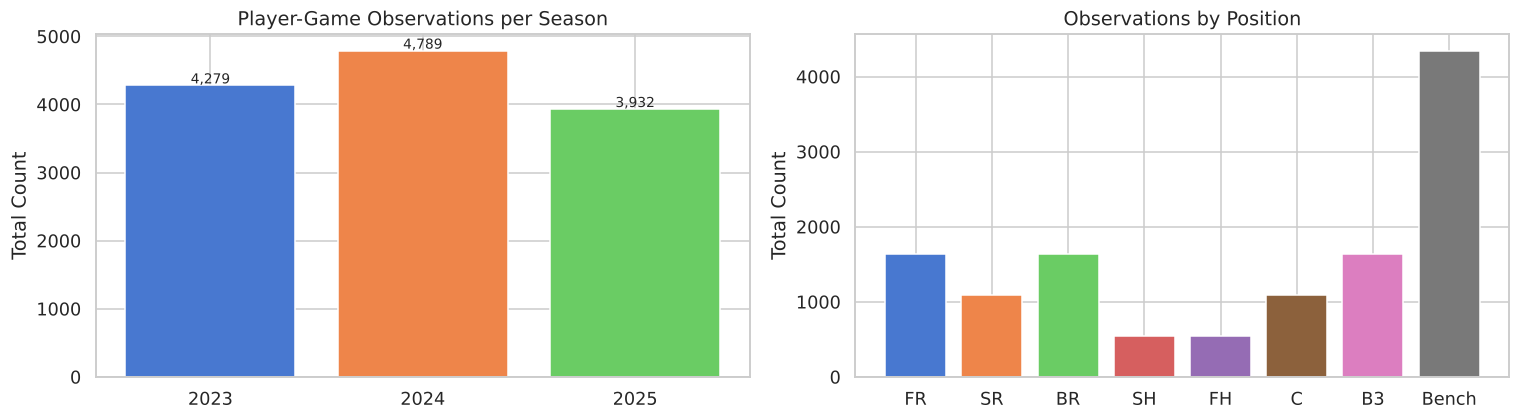

In [3]:
# Observations of Seasons and Positions
# My only goal here is to confirm the shape of the data by getting a 
# Total Count (y-axis)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: rows per year
year_counts = df['year'].value_counts().sort_index()
axes[0].bar(year_counts.index.astype(str), year_counts.values, color=sns.color_palette('muted'))
axes[0].set_title('Player-Game Observations per Season')
axes[0].set_ylabel('Total Count')
for i, v in enumerate(year_counts.values):
    axes[0].text(i, v + 30, f'{v:,}', ha='center', fontsize=9)

# Right: position composition
pos_counts = df['Pos'].value_counts().reindex(POS_ORDER)
axes[1].bar(pos_counts.index, pos_counts.values, color=sns.color_palette('muted'))
axes[1].set_title('Observations by Position')
axes[1].set_ylabel('Total Count')

plt.tight_layout()
plt.show()

## 3. Missing Data & Data Quality Audit

In [4]:
# Running a scan on the null data

null_counts = df.isnull().sum()
print('Null Counts per Column')
print(null_counts[null_counts > 0] if null_counts.any() else 'No nulls found.')
print()

# Zero-minute rows: players who dressed but did not play
zero_min = df[df['Minutes'] == 0]
print(f'Zero-minute rows: {len(zero_min):,}')
print('Breakdown by position:')
print(zero_min['Pos'].value_counts())
started_zero = ((df['Started'] == 1) & (df['Minutes'] == 0)).sum()
print()
print('DSP rows are team bonus-point entries (always 0 minutes). Bench zero-minute rows')
print('are players who dressed but never entered. Both are excluded from the starter models.')
print(f'{started_zero} rows are marked Started=1 with 0 minutes. These are data anomalies '
      'and are dropped in Section 12.')

Null Counts per Column
No nulls found.

Zero-minute rows: 807
Breakdown by position:
Pos
DSP      496
Bench    309
FR         1
B3         1
Name: count, dtype: int64

DSP rows are team bonus-point entries (always 0 minutes). Bench zero-minute rows
are players who dressed but never entered. Both are excluded from the starter models.
2 rows are marked Started=1 with 0 minutes. These are data anomalies and are dropped in Section 12.


In [5]:
# Advanced stat coverage audit: OffensiveBP, DefensiveBP, SetPieceTryAssists

advanced = ['SetPieceTryAssists', 'OffensiveBP', 'DefensiveBP']
print('Advanced stat value distributions')
for col in advanced:
    vc = df[col].value_counts().sort_index()
    pct_nonzero = (df[col] > 0).mean() * 100
    print(f'{col}: {dict(vc)} | Non-zero: {pct_nonzero:.1f}%')

print()
print('All three are excluded from modeling. Each is nonzero in under 2.5% of rows,')
print('and for starters the per-position correlation with fantasy points is undefined')
print('(the columns are constant within starting positions; see Section 6).')

Advanced stat value distributions
SetPieceTryAssists: {0: np.int64(12766), 1: np.int64(174), 2: np.int64(44), 3: np.int64(10), 4: np.int64(5), 5: np.int64(1)} | Non-zero: 1.8%
OffensiveBP: {0: np.int64(12716), 1: np.int64(284)} | Non-zero: 2.2%
DefensiveBP: {0: np.int64(12894), 1: np.int64(106)} | Non-zero: 0.8%

All three are excluded from modeling. Each is nonzero in under 2.5% of rows,
and for starters the per-position correlation with fantasy points is undefined
(the columns are constant within starting positions; see Section 6).


In [6]:
# Duplicate review: each player should appear once per match

key = ['year', 'Match_ID', 'Player_ID']
dupe_mask = df.duplicated(subset=key, keep=False)
print(f'Rows sharing a (year, Match_ID, Player_ID) key: {dupe_mask.sum()}')
print(f'Exact duplicate rows (every column identical): {df.duplicated().sum()}')
dupes = df[dupe_mask].sort_values(key)
first, other = dupes.groupby(key).nth(0), dupes.groupby(key).nth(1)
print(f'Duplicate pairs: {len(first)} '
      f'({(first["Pos"] == "DSP").sum()} team bonus rows, {(first["Pos"] != "DSP").sum()} player rows)')
stale = ((first['Fantasy_Points'].to_numpy() < other['Fantasy_Points'].to_numpy()) |
         (first['Minutes'].to_numpy() < other['Minutes'].to_numpy()))
print(f'Pairs where the first row is the less complete record: {stale.sum()} of {len(first)}')

# Duplicate pairs differ: usually one stale row (0.0 FP, no meters) and one full stat line.
# Keep the most complete record (most minutes, then most FP), then restore row order.
n_before = len(df)
df = (df.sort_values(['Minutes', 'Fantasy_Points'], ascending=False, kind='stable')
        .drop_duplicates(subset=key, keep='first')
        .sort_index()
        .reset_index(drop=True))
print(f'Rows after de-duplication: {len(df):,} (removed {n_before - len(df)})')

# Copied matches: drop any match where most jersey-matched stat lines are identical
# across both teams (API error).
STAT_COLS = ['Fantasy_Points', 'Minutes', 'Tries', 'Meters', 'Assists', 'Tackles', 'Steals', 'Turnovers']
copied = []
for (yr, mid), g in df[(df['Minutes'] > 0) & (df['Pos'] != 'DSP')].groupby(['year', 'Match_ID']):
    sides = [s.drop_duplicates('Number').set_index('Number')[STAT_COLS] for _, s in g.groupby('Team')]
    if len(sides) != 2:
        continue
    common = sides[0].index.intersection(sides[1].index)
    same = (sides[0].loc[common].values == sides[1].loc[common].values).all(axis=1)
    if len(common) and same.mean() > 0.5:
        copied.append((yr, mid, g['Rnd'].iloc[0], sorted(g['Team'].unique()), int(same.sum()), len(common)))
for yr, mid, rnd, teams, n_same, n in copied:
    print(f'Match {mid} ({yr} Rd {rnd}, {teams[0]} v {teams[1]}): {n_same} of {n} jersey-matched lines identical. Dropped.')
bad = df.set_index(['year', 'Match_ID']).index.isin([(c[0], c[1]) for c in copied])
df = df[~bad].reset_index(drop=True)
print(f'Rows after removing copied matches: {len(df):,}')

Rows sharing a (year, Match_ID, Player_ID) key: 32
Exact duplicate rows (every column identical): 0
Duplicate pairs: 16 (7 team bonus rows, 9 player rows)
Pairs where the first row is the less complete record: 13 of 16
Rows after de-duplication: 12,984 (removed 16)


Match 355 (2024 Rd 18, SDL v SEA): 19 of 23 jersey-matched lines identical. Dropped.
Rows after removing copied matches: 12,936


## 4. Target Variable: Fantasy Points Distribution

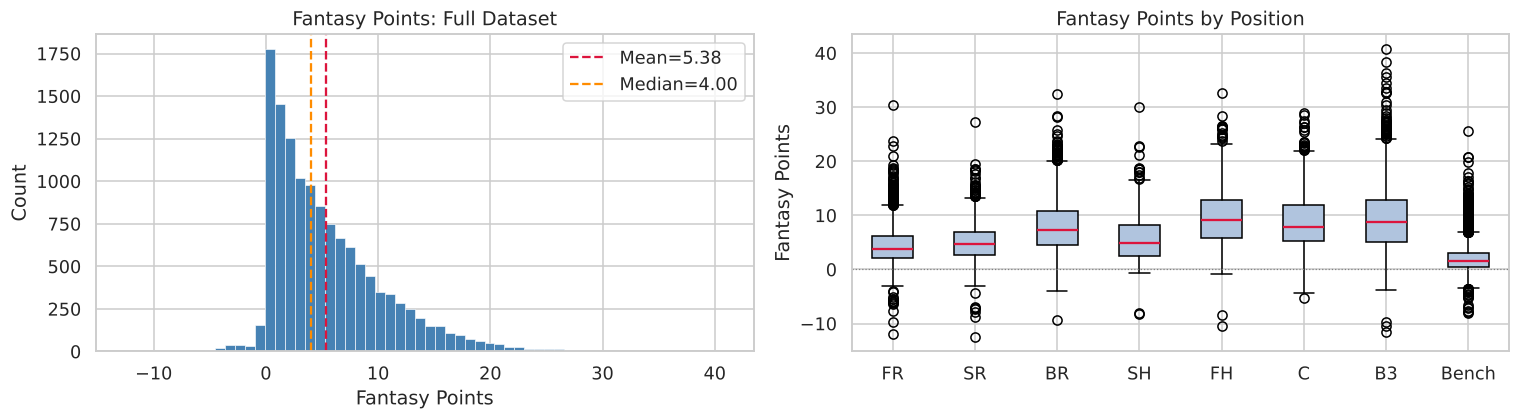


 Fantasy Points Summary Statistics
count    12936.00
mean         5.38
std          5.15
min        -12.50
25%          1.50
50%          4.00
75%          8.00
max         40.80
Name: Fantasy_Points, dtype: float64

Skewness: 1.301
Kurtosis: 2.397


In [7]:
# Total Distribution of Fantasy Points

fp = df['Fantasy_Points']

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Histogram Created for visualization
axes[0].hist(fp, bins=60, color='steelblue', edgecolor='white', linewidth=0.4)
axes[0].axvline(fp.mean(), color='crimson', linestyle='--', label=f'Mean={fp.mean():.2f}')
axes[0].axvline(fp.median(), color='darkorange', linestyle='--', label=f'Median={fp.median():.2f}')
axes[0].set_title('Fantasy Points: Full Dataset')
axes[0].set_xlabel('Fantasy Points')
axes[0].set_ylabel('Count')
axes[0].legend()

# Box plot by position
pos_data = [df[df['Pos'] == p]['Fantasy_Points'].values for p in POS_ORDER]
axes[1].boxplot(pos_data, tick_labels=POS_ORDER, patch_artist=True,
                boxprops=dict(facecolor='lightsteelblue'),
                medianprops=dict(color='crimson', linewidth=1.5))
axes[1].set_title('Fantasy Points by Position')
axes[1].set_ylabel('Fantasy Points')
axes[1].axhline(0, color='gray', linestyle=':', linewidth=0.8)

plt.tight_layout()
plt.show()

print('\n Fantasy Points Summary Statistics')
print(fp.describe().round(2))
print(f'\nSkewness: {fp.skew():.3f}')
print(f'Kurtosis: {fp.kurtosis():.3f}')

In [8]:
# Fantasy Points by Position with more detail than standard EDA outputs

pos_summary = (
    df.groupby('Pos')['Fantasy_Points']
    .describe()
    .round(2)
    .reindex(POS_ORDER)
)
print('Fantasy Points by Position')
print(pos_summary.to_string())
print()
print('Key observation: B3, FH, and C produce the highest median FP among starters.')
print('FR and SR are lowest, consistent with their primarily defensive/set-piece roles.')

Fantasy Points by Position
        count  mean   std   min  25%   50%    75%   max
Pos                                                    
FR     1626.0  4.52  3.72 -12.0  2.2  3.80   6.10  30.4
SR     1083.0  5.13  3.61 -12.5  2.7  4.70   6.90  27.3
BR     1626.0  8.07  5.07  -9.4  4.6  7.30  10.80  32.5
SH      542.0  5.77  4.55  -8.3  2.5  4.95   8.20  30.0
FH      542.0  9.64  5.58 -10.4  5.8  9.10  12.80  32.6
C      1082.0  8.86  5.16  -5.2  5.2  7.90  11.90  28.9
B3     1626.0  9.44  6.20 -11.5  5.1  8.70  12.78  40.8
Bench  4322.0  2.14  2.66  -8.1  0.4  1.50   3.00  25.6

Key observation: B3, FH, and C produce the highest median FP among starters.
FR and SR are lowest, consistent with their primarily defensive/set-piece roles.


In [9]:
# Analyzing Points per minute to review efficiency
# Restrict to players who played (Minutes > 0)

played = df[df['Minutes'] > 0].copy()
played['pts_per_min'] = played['Fantasy_Points'] / played['Minutes']

ppm_by_pos = (
    played[played['Pos'].isin(STARTER_POS)]
    .groupby('Pos')['pts_per_min']
    .agg(['mean', 'median'])
    .round(3)
    .reindex(STARTER_POS)
)

print('Fantasy Points per Minute by Position (starters who played)')
print(ppm_by_pos.to_string())
print()
print('Interpretation: Minutes is a significant driver. Pts/min isolates quality from usage.')

Fantasy Points per Minute by Position (starters who played)
      mean  median
Pos               
FR   0.075   0.065
SR   0.072   0.067
BR   0.112   0.102
SH   0.084   0.072
FH   0.120   0.119
C    0.118   0.108
B3   0.126   0.115

Interpretation: Minutes is a significant driver. Pts/min isolates quality from usage.


## 5. Position-Level Analysis

In [10]:
# Stat means by position (starters only)

starters = df[df['Started'] == 1].copy()

stat_cols = ['Fantasy_Points', 'Minutes', 'Tries', 'Meters', 'Assists',
             'Tackles', 'Steals', 'Conversions', 'Penalty_goals']

pos_means = (
    starters[starters['Pos'].isin(STARTER_POS)]
    .groupby('Pos')[stat_cols]
    .mean()
    .round(3)
    .reindex(STARTER_POS)
)

print('Mean Statistics by Starting Position')
print(pos_means.to_string())

Mean Statistics by Starting Position
     Fantasy_Points  Minutes  Tries  Meters  Assists  Tackles  Steals  Conversions  Penalty_goals
Pos                                                                                              
FR            4.519   57.675  0.153  16.817    0.022    7.876   0.140        0.000          0.000
SR            5.134   69.577  0.086  18.083    0.036    9.458   0.152        0.000          0.000
BR            8.070   70.903  0.213  31.972    0.073   11.085   0.371        0.001          0.000
SH            5.771   66.439  0.236  20.161    0.443    5.786   0.173        0.031          0.009
FH            9.636   74.369  0.137  34.424    0.406    5.721   0.116        1.692          0.782
C             8.859   74.298  0.212  45.997    0.185    7.953   0.255        0.044          0.011
B3            9.444   74.277  0.334  57.695    0.147    4.504   0.208        0.062          0.034


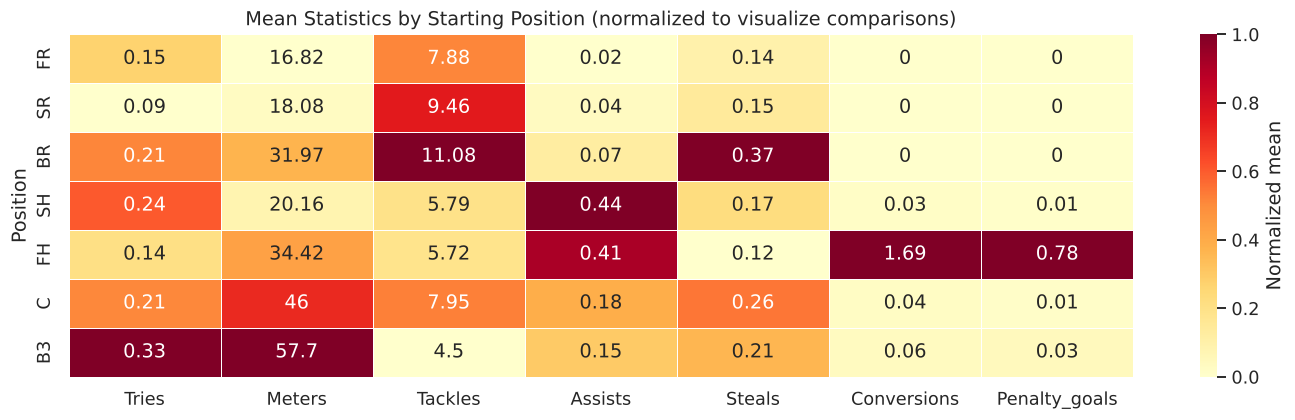


Annotations show raw means. Color shows relative magnitude within each stat column.


In [11]:
# Heatmap: mean stat by position
# Normalize each column to [0,1] to visualize comparisons

heatmap_cols = ['Tries', 'Meters', 'Tackles', 'Assists', 'Steals',
                'Conversions', 'Penalty_goals',]

hm_data = pos_means[heatmap_cols].copy()
hm_norm = (hm_data - hm_data.min()) / (hm_data.max() - hm_data.min())

fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(hm_norm, annot=hm_data.round(2), fmt='g', cmap='YlOrRd',
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Normalized mean'})
ax.set_title('Mean Statistics by Starting Position (normalized to visualize comparisons)')
ax.set_xlabel('')
ax.set_ylabel('Position')
plt.tight_layout()
plt.show()

print('\nAnnotations show raw means. Color shows relative magnitude within each stat column.')

## 6. Feature Correlation Analysis (Global & Per-Position)

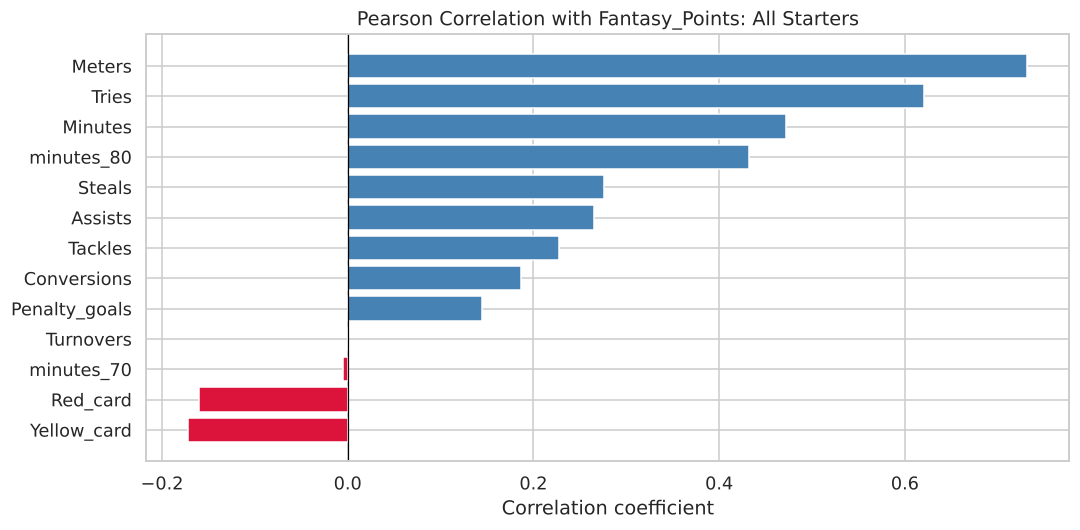


 Global Correlations (starters)
Meters           0.732
Tries            0.620
Minutes          0.472
minutes_80       0.432
Steals           0.276
Assists          0.265
Tackles          0.227
Conversions      0.187
Penalty_goals    0.145
Turnovers        0.000
minutes_70      -0.005
Red_card        -0.160
Yellow_card     -0.172


In [12]:
# Global correlation with Fantasy_Points (starters only again)

numeric_features = ['Minutes', 'Tries', 'Meters', 'Assists', 'Tackles',
                    'Steals', 'Turnovers', 'Conversions', 'Penalty_goals',
                    'minutes_70', 'minutes_80', 'Yellow_card', 'Red_card']

global_corr = (
    starters[numeric_features + ['Fantasy_Points']]
    .corr()['Fantasy_Points']
    .drop('Fantasy_Points')
    .sort_values(ascending=False)
)

fig, ax = plt.subplots(figsize=(10, 5))
colors = ['steelblue' if v >= 0 else 'crimson' for v in global_corr.values]
ax.barh(global_corr.index[::-1], global_corr.values[::-1], color=colors[::-1])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Pearson Correlation with Fantasy_Points: All Starters')
ax.set_xlabel('Correlation coefficient')
plt.tight_layout()
plt.show()

print('\n Global Correlations (starters)')
print(global_corr.round(3).to_string())

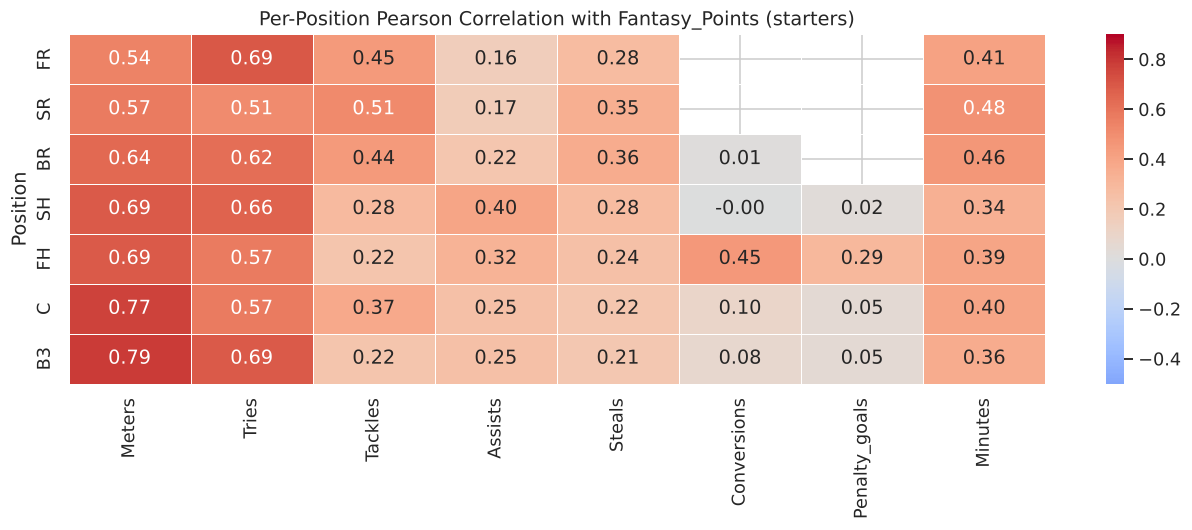


Key insight: Meters is the single strongest predictor across all positions.
Conversions is only meaningful for FH. Tackles matters more for forwards.


In [13]:
# Per-position correlation heatmap

corr_features = ['Meters', 'Tries', 'Tackles', 'Assists', 'Steals',
                 'Conversions', 'Penalty_goals', 'Minutes']

per_pos_corr = {}
for pos in STARTER_POS:
    sub = starters[starters['Pos'] == pos]
    corr_row = sub[corr_features + ['Fantasy_Points']].corr()['Fantasy_Points'].drop('Fantasy_Points')
    per_pos_corr[pos] = corr_row

corr_df = pd.DataFrame(per_pos_corr).T  # shape: (7 positions × 8 features)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(corr_df, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, ax=ax, vmin=-0.5, vmax=0.9)
ax.set_title('Per-Position Pearson Correlation with Fantasy_Points (starters)')
ax.set_ylabel('Position')
plt.tight_layout()
plt.show()

print('\nKey insight: Meters is the single strongest predictor across all positions.')
print('Conversions is only meaningful for FH. Tackles matters more for forwards.')

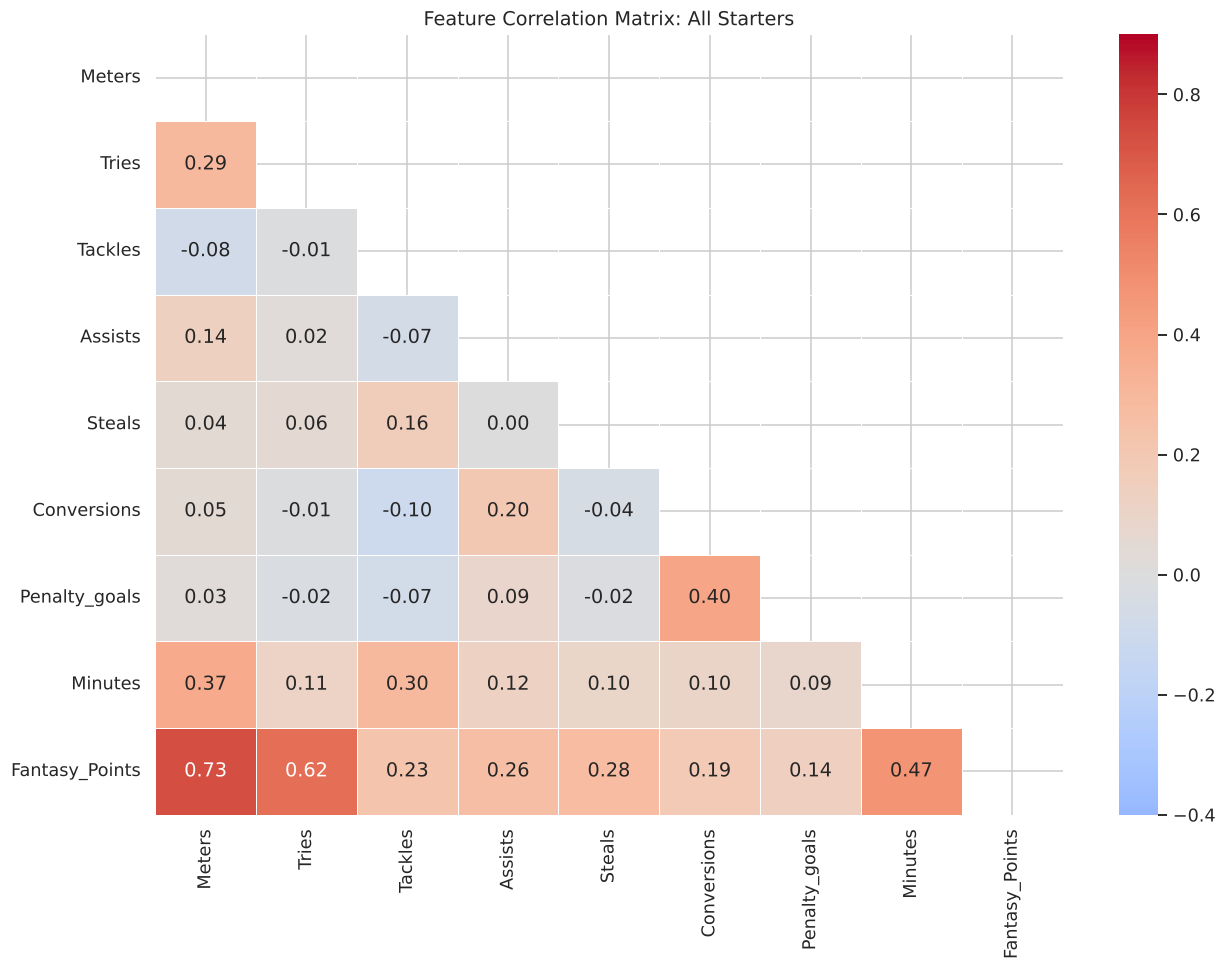

In [14]:
# Full correlation matrix (starters, numeric features)

full_corr = starters[corr_features + ['Fantasy_Points']].corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(full_corr, dtype=bool))  # upper triangle
sns.heatmap(full_corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.4, ax=ax, vmin=-0.4, vmax=0.9)
ax.set_title('Feature Correlation Matrix: All Starters')
plt.tight_layout()
plt.show()

## 7. Starter vs. Bench Analysis

Started distribution
Started
Started          8127
Did not start    4809
Name: count, dtype: int64



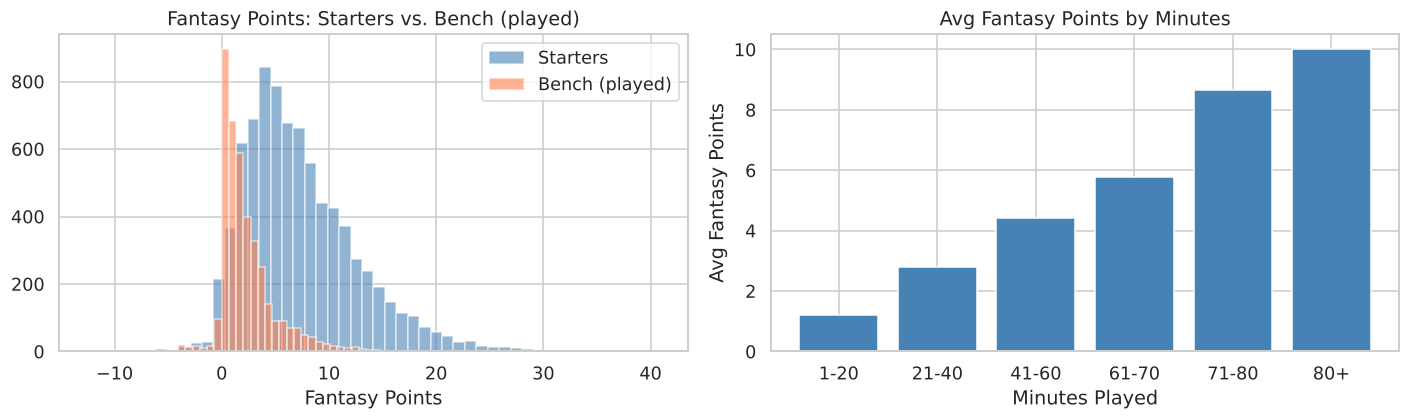

Starter mean: 7.30  |  Bench (played) mean: 2.30
t-statistic: 56.045  |  p-value: 0.00e+00
Starters score significantly higher. This justifies separate modeling by role.


In [15]:
# Starter/bench split and Fantasy Points comparison

print('Started distribution')
print(df['Started'].value_counts().rename({1: 'Started', 0: 'Did not start'}))
print()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Fantasy Point distributions: starters vs bench

for label, subset, color in [('Starters', df[df['Started']==1], 'steelblue'),
                               ('Bench (played)', df[(df['Started']==0) & (df['Minutes']>0)], 'coral')]:
    axes[0].hist(subset['Fantasy_Points'], bins=50, alpha=0.6, label=label, color=color, edgecolor='white')
axes[0].set_title('Fantasy Points: Starters vs. Bench (played)')
axes[0].set_xlabel('Fantasy Points')
axes[0].legend()

# Average Fantasy Points by minutes

played = df[df['Minutes'] > 0].copy()
played['min_bucket'] = pd.cut(played['Minutes'], bins=[0,20,40,60,70,80,91],
                               labels=['1-20','21-40','41-60','61-70','71-80','80+'])
avg_by_min = played.groupby('min_bucket', observed=True)['Fantasy_Points'].mean()
axes[1].bar(avg_by_min.index, avg_by_min.values, color='steelblue')
axes[1].set_title('Avg Fantasy Points by Minutes')
axes[1].set_xlabel('Minutes Played')
axes[1].set_ylabel('Avg Fantasy Points')

plt.tight_layout()
plt.show()

# t-test

s_fp = df[df['Started']==1]['Fantasy_Points']
b_fp = df[(df['Started']==0) & (df['Minutes']>0)]['Fantasy_Points']
t, p = stats.ttest_ind(s_fp, b_fp)
print(f'Starter mean: {s_fp.mean():.2f}  |  Bench (played) mean: {b_fp.mean():.2f}')
print(f't-statistic: {t:.3f}  |  p-value: {p:.2e}')
print('Starters score significantly higher. This justifies separate modeling by role.')

In [16]:
# minutes_70 / minutes_80 flag analysis
# These indicate whether a player played ≥70 or ≥80 minutes

for col in ['minutes_70', 'minutes_80']:
    grouped = df.groupby(col)['Fantasy_Points'].agg(['mean','count'])
    print(f'\n{col}:')
    print(grouped.round(2))

print('\nNote: minutes_70 and minutes_80 are binary milestone flags, not raw minute counts.')
print('These will be useful as engineered features in the model we build in the future.')


minutes_70:
            mean  count
minutes_70             
0           5.21  11883
1           7.23   1053

minutes_80:
            mean  count
minutes_80             
0           3.60   9242
1           9.82   3694

Note: minutes_70 and minutes_80 are binary milestone flags, not raw minute counts.
These will be useful as engineered features in the model we build in the future.


## 8. Cross-Season Trends

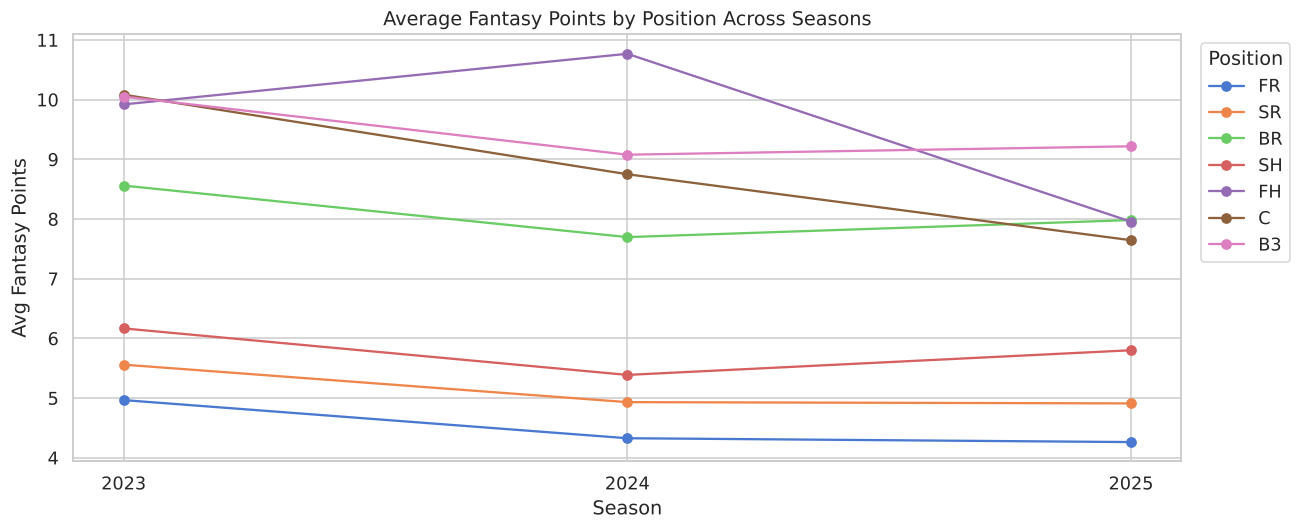


Avg Fantasy Points by Year & Position
Pos     FR    SR    BR    SH     FH      C     B3
year                                             
2023  4.97  5.56  8.56  6.17   9.92  10.08  10.05
2024  4.33  4.93  7.70  5.39  10.77   8.75   9.08
2025  4.26  4.91  7.98  5.80   7.96   7.64   9.22


In [17]:
# Average Fantasy Points by season and position (starters, all teams)

yp_avg = (
    df[df['Pos'].isin(STARTER_POS)]
    .groupby(['year', 'Pos'])['Fantasy_Points']
    .mean()
    .unstack('Pos')
    .reindex(columns=STARTER_POS)
)

fig, ax = plt.subplots(figsize=(12, 5))
for pos in STARTER_POS:
    ax.plot(yp_avg.index, yp_avg[pos], marker='o', label=pos)
ax.set_title('Average Fantasy Points by Position Across Seasons')
ax.set_xlabel('Season')
ax.set_ylabel('Avg Fantasy Points')
ax.set_xticks([2023, 2024, 2025])
ax.legend(title='Position', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

print('\nAvg Fantasy Points by Year & Position')
print(yp_avg.round(2).to_string())

Average Fantasy Points per Team per Round by Season
year
2023    138.08
2024    123.42
2025    125.69


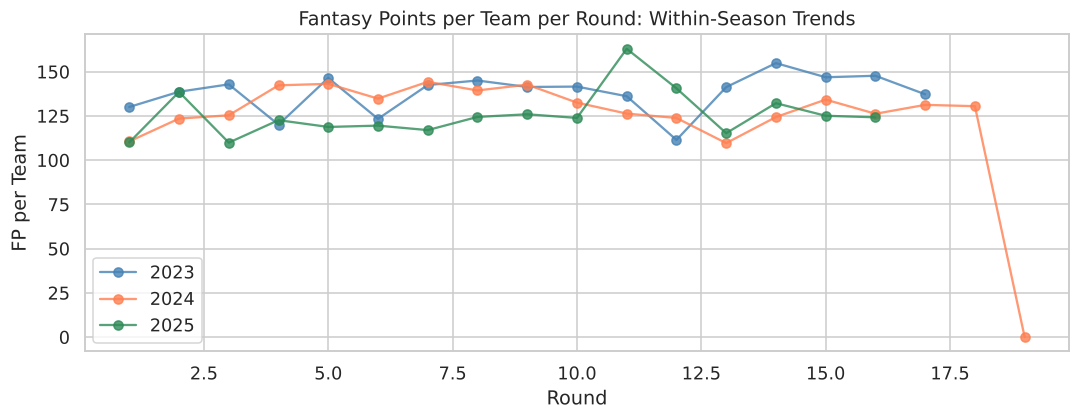

In [18]:
# Total scoring volume per season (controlling for team count)

teams_per_round = df.groupby(['year', 'Rnd'])['Team'].nunique().reset_index(name='n_teams')
round_totals = df.groupby(['year', 'Rnd'])['Fantasy_Points'].sum().reset_index(name='total_fp')
merged = round_totals.merge(teams_per_round, on=['year','Rnd'])
merged['fp_per_team'] = merged['total_fp'] / merged['n_teams']

season_avg = merged.groupby('year')['fp_per_team'].mean().round(2)
print('Average Fantasy Points per Team per Round by Season')
print(season_avg.to_string())

fig, ax = plt.subplots(figsize=(10, 4))

# Rolling average per round to see potential in-season drift

for yr, color in [(2023, 'steelblue'), (2024, 'coral'), (2025, 'seagreen')]:
    sub = merged[merged['year'] == yr].sort_values('Rnd')
    ax.plot(sub['Rnd'], sub['fp_per_team'], marker='o', label=str(yr), color=color, alpha=0.8)
ax.set_title('Fantasy Points per Team per Round: Within-Season Trends')
ax.set_xlabel('Round')
ax.set_ylabel('FP per Team')
ax.legend()
plt.tight_layout()
plt.show()

In [19]:
# Home vs Away impact

ha = df[df['Pos'].isin(STARTER_POS)].groupby('Home_away')['Fantasy_Points'].agg(['mean','std','count'])
print('Fantasy Points by Home/Away (starters)')
print(ha.round(3).to_string())

# t-test
home_fp = df[(df['Home_away']=='Home') & (df['Pos'].isin(STARTER_POS))]['Fantasy_Points']
away_fp = df[(df['Home_away']=='Away') & (df['Pos'].isin(STARTER_POS))]['Fantasy_Points']
t, p = stats.ttest_ind(home_fp, away_fp)
print(f'\nt-stat: {t:.3f}  |  p-value: {p:.4f}')
print('Implication: Home/Away is a candidate feature for the model.')

Fantasy Points by Home/Away (starters)
            mean    std  count
Home_away                     
Away       7.174  5.255   4063
Home       7.424  5.394   4064

t-stat: 2.112  |  p-value: 0.0347
Implication: Home/Away is a candidate feature for the model.


## 9. Player-Level Continuity (Multi-Season Players)

In [20]:
# How many players appear across seasons?

player_seasons = df.groupby('Player_ID')['year'].nunique()
print('Player season counts')
print(player_seasons.value_counts().rename_axis('seasons_played').rename('players'))

n3, n2plus, n1 = (player_seasons == 3).sum(), (player_seasons >= 2).sum(), (player_seasons == 1).sum()
print(f'\nPlayers with data in all 3 seasons: {n3}')
print(f'Players in 2+ seasons: {n2plus}')
print(f'Single-season players: {n1}')
print()
print(f'Implication: {n2plus} players have at least one prior season, which supports '
      'prior-season lag features. The rest need a cold-start fallback.')

Player season counts
seasons_played
1    394
2    221
3    179
Name: players, dtype: int64

Players with data in all 3 seasons: 179
Players in 2+ seasons: 400
Single-season players: 394

Implication: 400 players have at least one prior season, which supports prior-season lag features. The rest need a cold-start fallback.


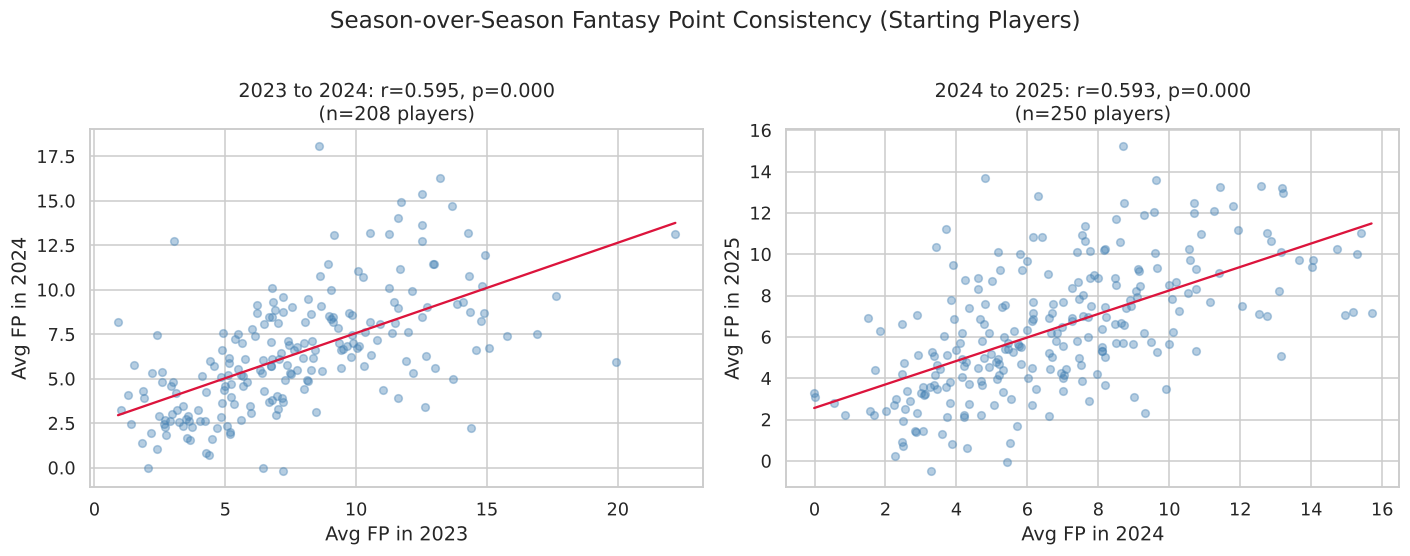


Strong year-over-year correlation validates prior-season average Fantasy Points as a key model feature.


In [21]:
# Season-over-season fantasy point correlation
# Only covering players with both 2023 and 2024 data

avg_by_player_year = (
    df[df['Pos'].isin(STARTER_POS)]
    .groupby(['Player_ID', 'year'])['Fantasy_Points']
    .mean()
    .unstack('year')
)

# 2023 to 2024
paired_2324 = avg_by_player_year[[2023, 2024]].dropna()
r_2324, p_2324 = stats.pearsonr(paired_2324[2023], paired_2324[2024])

# 2024 to 2025
paired_2425 = avg_by_player_year[[2024, 2025]].dropna()
r_2425, p_2425 = stats.pearsonr(paired_2425[2024], paired_2425[2025])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (yr1, yr2), paired, r, p in [
    (axes[0], (2023, 2024), paired_2324, r_2324, p_2324),
    (axes[1], (2024, 2025), paired_2425, r_2425, p_2425)
]:
    ax.scatter(paired[yr1], paired[yr2], alpha=0.4, s=25, color='steelblue')
    m, b = np.polyfit(paired[yr1], paired[yr2], 1)
    xline = np.linspace(paired[yr1].min(), paired[yr1].max(), 100)
    ax.plot(xline, m*xline + b, color='crimson', linewidth=1.5)
    ax.set_title(f'{yr1} to {yr2}: r={r:.3f}, p={p:.3f}\n(n={len(paired)} players)')
    ax.set_xlabel(f'Avg FP in {yr1}')
    ax.set_ylabel(f'Avg FP in {yr2}')

plt.suptitle('Season-over-Season Fantasy Point Consistency (Starting Players)', y=1.01)
plt.tight_layout()
plt.show()

print('\nStrong year-over-year correlation validates prior-season average Fantasy Points as a key model feature.')

In [22]:
# In-season week-to-week consistency per player
# Coefficient of variation as a stability measure

player_cv = (
    df[df['Pos'].isin(STARTER_POS)]
    .groupby(['Player_ID', 'year'])['Fantasy_Points']
    .agg(['mean', 'std'])
    .dropna()
)
player_cv['cv'] = player_cv['std'] / player_cv['mean'].abs()

print('In-Season CV (std/mean): Player Consistency')
print(player_cv['cv'].describe().round(3))
print()
print('High CV = volatile player. Low CV = consistent performer.')
print('CV can be engineered as a player stability feature for the model.')

In-Season CV (std/mean): Player Consistency
count    1027.000
mean        1.306
std        18.516
min         0.016
25%         0.425
50%         0.553
75%         0.725
max       589.449
Name: cv, dtype: float64

High CV = volatile player. Low CV = consistent performer.
CV can be engineered as a player stability feature for the model.


## 10. Outlier Detection

In [23]:
# IQR-based outlier identification per position

outlier_records = []
for pos in STARTER_POS:
    sub = df[df['Pos'] == pos]['Fantasy_Points']
    q1, q3 = sub.quantile(0.25), sub.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 3 * iqr, q3 + 3 * iqr  # 3×IQR for extreme outliers
    extreme = df[(df['Pos'] == pos) & ((df['Fantasy_Points'] < lo) | (df['Fantasy_Points'] > hi))]
    outlier_records.append({'Pos': pos, 'IQR_lo': round(lo,2), 'IQR_hi': round(hi,2),
                             'n_outliers': len(extreme), 'pct': round(len(extreme)/len(sub)*100,2)})

outlier_summary = pd.DataFrame(outlier_records).set_index('Pos')
print('Extreme Outliers per Position (3*IQR threshold)')
print(outlier_summary.to_string())

Extreme Outliers per Position (3*IQR threshold)
     IQR_lo  IQR_hi  n_outliers   pct
Pos                                  
FR    -9.50    17.8          13  0.80
SR    -9.90    19.5           2  0.18
BR   -14.00    29.4           1  0.06
SH   -14.60    25.3           1  0.18
FH   -15.20    33.8           0  0.00
C    -14.90    32.0           0  0.00
B3   -17.93    35.8           3  0.18


In [24]:
# Extreme performances by position (25+ FP starts and negative FP starts)

big = starters[starters['Fantasy_Points'] >= 25]
neg = starters[starters['Fantasy_Points'] < 0]
print('Starts scoring 25+ fantasy points, by position')
print(big.groupby('Pos')[['Fantasy_Points', 'Tries', 'Meters']].agg(['count', 'mean'])
         .loc[:, [('Fantasy_Points', 'count'), ('Fantasy_Points', 'mean'), ('Tries', 'mean'), ('Meters', 'mean')]]
         .round(1).reindex(STARTER_POS).dropna().to_string())
print()
print('Starts with negative fantasy points, by position')
print(neg.groupby('Pos')[['Fantasy_Points', 'Minutes', 'Yellow_card', 'Red_card']].agg(['count', 'mean'])
         .loc[:, [('Fantasy_Points', 'count'), ('Fantasy_Points', 'mean'), ('Minutes', 'mean'),
                  ('Yellow_card', 'mean'), ('Red_card', 'mean')]]
         .round(2).reindex(STARTER_POS).dropna().to_string())
print()
print('Big games come from multiple tries and long carries, mostly in the back three.')
print('Negative games tend to be short stints, often with a card.')

Starts scoring 25+ fantasy points, by position
    Fantasy_Points       Tries Meters
             count  mean  mean   mean
Pos                                  
FR               1  30.4   5.0   23.0
SR               1  27.3   2.0   73.0
BR               5  27.9   1.4  133.6
SH               1  30.0   2.0  167.0
FH               9  27.1   1.1  115.3
C                8  27.0   1.9  132.5
B3              34  29.1   2.1  141.9

Starts with negative fantasy points, by position
    Fantasy_Points       Minutes Yellow_card Red_card
             count  mean    mean        mean     mean
Pos                                                  
FR              49 -2.56   46.43        0.63     0.18
SR              27 -3.25   55.56        0.93     0.22
BR              31 -1.52   58.35        0.84     0.13
SH               5 -3.50   45.80        0.20     0.40
FH               4 -5.10   46.50        0.75     0.50
C                8 -2.95   54.88        0.50     0.50
B3              16 -3.56   47.88     

In [25]:
# Card events and their Fantasy Points impact

yellow_mean = df[df['Yellow_card'] == 1]['Fantasy_Points'].mean()
red_mean = df[df['Red_card'] == 1]['Fantasy_Points'].mean()
no_card_mean = df[(df['Yellow_card'] == 0) & (df['Red_card'] == 0)]['Fantasy_Points'].mean()

print('Impact of Disciplinary Events')
print(f'No card avg FP:     {no_card_mean:.2f}')
print(f'Yellow card avg FP: {yellow_mean:.2f}  (n={df["Yellow_card"].sum()})')
print(f'Red card avg FP:    {red_mean:.2f}  (n={df["Red_card"].sum()})')
print()
print('Red/yellow cards penalize FP directly via scoring rules.')
print('Can include as binary feature. Consider interaction with Minutes for reds.')

Impact of Disciplinary Events
No card avg FP:     5.52
Yellow card avg FP: 1.87  (n=427)
Red card avg FP:    -5.42  (n=45)

Red/yellow cards penalize FP directly via scoring rules.
Can include as binary feature. Consider interaction with Minutes for reds.


## 11. Key Findings & Modeling Implications

In [26]:
# Key EDA findings summary

fp = df['Fantasy_Points']
starters_mask = df['Started'] == 1
print('KEY EDA FINDINGS')
print()
print('1. Data quality')
print(f'   - No nulls. {len(zero_min):,} zero-minute rows (DSP team bonus rows and bench who never entered) are out of scope.')
print(f'   - {started_zero} Started=1 rows with 0 minutes are dropped as anomalies.')
print(f'   - Max FP = {fp.max():.1f}, min = {fp.min():.1f}.')
print()
print('2. Target variable')
print(f'   - Mean FP = {fp.mean():.2f}, median = {fp.median():.2f}, skewness = {fp.skew():.2f} (right-skewed).')
print(f'   - Starters average {fp[starters_mask].mean():.2f} FP; bench players who played average '
      f'{fp[(~starters_mask) & (df["Minutes"] > 0)].mean():.2f}.')
print('   - Backs (B3, FH, C) score far more than front-row and second-row forwards, so forwards')
print('     and backs are modeled separately.')
print()
print('3. Feature signal (starters)')
print(f'   - Meters (r = {global_corr["Meters"]:.2f}) and Tries (r = {global_corr["Tries"]:.2f}) are the strongest correlates.')
print('   - Conversions and penalty goals matter for FH only; tackles matter more for forwards.')
print('   - These are in-game statistics: they explain a score after the match but are not')
print('     known before it. Pre-game signal has to come from history (Section 25).')
print()
print('4. Cross-season and player continuity')
print(f'   - Season-over-season correlation of player averages: r = {r_2324:.2f} (2023 to 2024), '
      f'{r_2425:.2f} (2024 to 2025).')
print(f'   - {n2plus} players have a prior season; the rest need a cold-start fallback.')
print()
print('5. Home/away')
ha_p = stats.ttest_ind(home_fp, away_fp).pvalue
print(f'   - Home starters average {home_fp.mean():.2f} FP vs {away_fp.mean():.2f} away (p = {ha_p:.3f}); included as a feature.')

KEY EDA FINDINGS

1. Data quality
   - No nulls. 807 zero-minute rows (DSP team bonus rows and bench who never entered) are out of scope.
   - 2 Started=1 rows with 0 minutes are dropped as anomalies.
   - Max FP = 40.8, min = -12.5.

2. Target variable
   - Mean FP = 5.38, median = 4.00, skewness = 1.30 (right-skewed).
   - Starters average 7.30 FP; bench players who played average 2.30.
   - Backs (B3, FH, C) score far more than front-row and second-row forwards, so forwards
     and backs are modeled separately.

3. Feature signal (starters)
   - Meters (r = 0.73) and Tries (r = 0.62) are the strongest correlates.
   - Conversions and penalty goals matter for FH only; tackles matter more for forwards.
   - These are in-game statistics: they explain a score after the match but are not
     known before it. Pre-game signal has to come from history (Section 25).

4. Cross-season and player continuity
   - Season-over-season correlation of player averages: r = 0.59 (2023 to 2024), 0.59 

## 12. Data Preparation & Feature Engineering

This section:
1. Constructs the opponent column via a Match_ID self-join
2. Filters to qualifying starter rows
3. Engineers features, all of which use only information available before the match
4. Applies the temporal train/validation/test split

**Leakage rules applied to every feature:**
- Player history (rolling averages, volatility) uses only earlier matches, via `shift(1)`.
- Prior-season features join season *t-1* data to season *t*.
- Any fallback value or encoding that is learned from the data (position medians, which players have enough history) is learned from the training seasons only.

**Split:**
- Train: 2023 and 2024 full seasons
- Validation: 2025 Rounds 1-10 (model selection and tuning)
- Test (held out, used once): 2025 Rounds 11+

In [27]:
# 12.0  Construct opponent column via Match_ID self-join
# The raw dataset has no opponent column. Each Match_ID appears exactly twice:
# once per team. A self-join on (year, Rnd, Match_ID) recovers the opponent
# for each team-row without requiring a separate schedule table.

match_teams = df[['year', 'Rnd', 'Match_ID', 'Team']].drop_duplicates()
opp_map = match_teams.merge(match_teams, on=['year', 'Rnd', 'Match_ID'])
opp_map = opp_map[opp_map['Team_x'] != opp_map['Team_y']][
    ['year', 'Rnd', 'Match_ID', 'Team_x', 'Team_y']
]
opp_map.columns = ['year', 'Rnd', 'Match_ID', 'Team', 'Opp']
df = df.merge(opp_map, on=['year', 'Rnd', 'Match_ID', 'Team'], how='left')

print(f'Opponent column added. Nulls: {df["Opp"].isnull().sum()}  (expected: 0)')
print(f'Sample: {df[["year","Rnd","Team","Opp"]].drop_duplicates().head(6).to_string(index=False)}')

Opponent column added. Nulls: 0  (expected: 0)
Sample:  year  Rnd Team  Opp
 2023    1  TOR RATL
 2023    1 RATL  TOR
 2023    1 NEFJ NOLA
 2023    1 NOLA NEFJ
 2023    1  CHI OGDC
 2023    1 OGDC  CHI


In [28]:
# 12.1  Import modeling libraries 

from sklearn.linear_model import LinearRegression, Ridge, RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder


In [29]:
# 12.2  Filter to qualifying starter rows
# Remove:
#   - zero-minute rows (DSP team bonus rows and bench players who never entered)
#   - rows flagged Started=1 but Minutes=0
#   - Bench and DSP positions (out of scope for the starter models)

STARTER_POS = ['FR', 'SR', 'BR', 'SH', 'FH', 'C', 'B3']

model_df = (
    df[
        (df['Minutes'] > 0) &
        (~((df['Started'] == 1) & (df['Minutes'] == 0))) &
        (df['Pos'].isin(STARTER_POS))
    ]
    .copy()
    .reset_index(drop=True)
)

print(f'Rows after filtering: {len(model_df):,}  '
      f'(removed {len(df) - len(model_df):,} rows)')
print('Position distribution after filter:')
print(model_df['Pos'].value_counts())

Rows after filtering: 8,125  (removed 4,811 rows)
Position distribution after filter:
Pos
BR    1626
FR    1625
B3    1625
SR    1083
C     1082
SH     542
FH     542
Name: count, dtype: int64


In [30]:
# 12.3  Engineer features

TRAIN_YEARS = [2023, 2024]

# Drop engineered columns first so re-running this cell doesn't create _x/_y duplicates
_engineered = [
    'is_home', 'pts_per_minute', 'prior_season_avg_fp', 'player_cv', 'player_cv_x', 'player_cv_y',
    'prior_season_cv', 'roll3_avg_fp', 'roll5_start_streak', 'player_id_cat',
    'player_id_encoded', 'pos_group', 'opp_fp_allowed_avg', 'pos_train_median_fp',
    'season_avg_fp',
]
model_df = model_df.drop(columns=[c for c in _engineered if c in model_df.columns])

# Sort by player and round before any lag or rolling features
model_df = model_df.sort_values(['Player_ID', 'year', 'Rnd']).reset_index(drop=True)
is_train = model_df['year'].isin(TRAIN_YEARS)

# (a) Home/away binary flag
model_df['is_home'] = (model_df['Home_away'] == 'Home').astype(int)

# (b) Points per minute (descriptive only, built from the target, not a feature)
model_df['pts_per_minute'] = model_df['Fantasy_Points'] / model_df['Minutes']

# (c) Prior-season average FP per player (season t-1 joined to season t)
season_avg = (
    model_df.groupby(['Player_ID', 'year'])['Fantasy_Points'].mean().reset_index()
    .rename(columns={'Fantasy_Points': 'prior_season_avg_fp'})
)
season_avg['year'] += 1
model_df = model_df.merge(season_avg, on=['Player_ID', 'year'], how='left')

# Cold start (no prior season): position median FP from training seasons only
pos_train_median = model_df.loc[is_train].groupby('Pos')['Fantasy_Points'].median()
model_df['prior_season_avg_fp'] = model_df['prior_season_avg_fp'].fillna(
    model_df['Pos'].map(pos_train_median)
)

# (d) Player volatility (coefficient of variation), earlier matches only
def prior_cv(x):
    prev = x.shift(1)
    mean = prev.expanding(min_periods=2).mean()
    std = prev.expanding(min_periods=2).std()
    return (std / mean.abs()).where(mean.abs() > 0.5)

model_df['player_cv'] = (
    model_df.groupby(['Player_ID', 'year'])['Fantasy_Points'].transform(prior_cv)
)
# Cold start: prior-season CV, then training-season median
season_cv = (
    model_df.groupby(['Player_ID', 'year'])['Fantasy_Points']
    .agg(lambda x: x.std() / abs(x.mean()) if len(x) > 1 and abs(x.mean()) > 0.5 else np.nan)
    .rename('prior_season_cv').reset_index()
)
season_cv['year'] += 1
model_df = model_df.merge(season_cv, on=['Player_ID', 'year'], how='left')
cv_train_median = model_df.loc[is_train, 'player_cv'].median()
model_df['player_cv'] = (model_df['player_cv']
                         .fillna(model_df['prior_season_cv'])
                         .fillna(cv_train_median)
                         .clip(upper=3.0))  # cap extreme values from near-zero means

# (e) Rolling 3-game average FP (same season, earlier matches only)
model_df['roll3_avg_fp'] = (
    model_df.groupby(['Player_ID', 'year'])['Fantasy_Points']
    .transform(lambda x: x.shift(1).rolling(3, min_periods=1).mean())
)
model_df['roll3_avg_fp'] = model_df['roll3_avg_fp'].fillna(model_df['prior_season_avg_fp'])

# (f) Player ID encoding: 5+ training-season appearances get their own code, others = -1
train_counts = model_df.loc[is_train, 'Player_ID'].value_counts()
known_players = set(train_counts[train_counts >= 5].index)
model_df['player_id_cat'] = model_df['Player_ID'].where(model_df['Player_ID'].isin(known_players), -1)
pid_le = LabelEncoder()
model_df['player_id_encoded'] = pid_le.fit_transform(model_df['player_id_cat'])

# (g) Opponent strength: prior-season average FP the opponent allowed to this position group
model_df['pos_group'] = np.where(model_df['Pos'].isin(['FR', 'SR', 'BR']), 'Forward', 'Back')
opp_strength = (
    model_df.groupby(['year', 'Opp', 'pos_group'])['Fantasy_Points'].mean().reset_index()
    .rename(columns={'Fantasy_Points': 'opp_fp_allowed_avg', 'Opp': 'opp_key'})
)
opp_strength['year'] += 1
model_df = model_df.merge(opp_strength, left_on=['year', 'Opp', 'pos_group'],
                          right_on=['year', 'opp_key', 'pos_group'], how='left').drop(columns='opp_key')
# No prior season (2023, expansion teams): training-season group mean
group_train_mean = model_df.loc[is_train].groupby('pos_group')['Fantasy_Points'].mean()
model_df['opp_fp_allowed_avg'] = model_df['opp_fp_allowed_avg'].fillna(model_df['pos_group'].map(group_train_mean))

# (h) Season-to-date average FP, earlier matches only (naive baseline for 25.6b, not a feature)
model_df['season_avg_fp'] = (
    model_df.groupby(['Player_ID', 'year'])['Fantasy_Points']
    .transform(lambda x: x.shift(1).expanding().mean())
)
model_df['season_avg_fp'] = model_df['season_avg_fp'].fillna(model_df['prior_season_avg_fp'])

new_features = ['prior_season_avg_fp', 'player_cv', 'roll3_avg_fp', 'player_id_encoded', 'opp_fp_allowed_avg']
print('Feature engineering complete.')
print('Null check:')
print(model_df[new_features].isnull().sum().to_string())
print(f'\nPlayers with their own ID code (5+ training appearances): {len(known_players)}')

Feature engineering complete.
Null check:
prior_season_avg_fp    0
player_cv              0
roll3_avg_fp           0
player_id_encoded      0
opp_fp_allowed_avg     0

Players with their own ID code (5+ training appearances): 409


In [31]:
# 12.4  Temporal train / val / test split

VAL_ROUNDS  = list(range(1, 11))    # 2025 Rds 1-10
TEST_ROUNDS = list(range(11, 100))  # 2025 Rds 11+

train = model_df[model_df['year'].isin(TRAIN_YEARS)].copy()
val   = model_df[(model_df['year'] == 2025) & (model_df['Rnd'].isin(VAL_ROUNDS))].copy()
test  = model_df[(model_df['year'] == 2025) & (model_df['Rnd'].isin(TEST_ROUNDS))].copy()

print('Split sizes:')
print(f'  Train : {len(train):>5,} rows  ({train["year"].min()}-{train["year"].max()})')
print(f'  Val   : {len(val):>5,} rows  (2025 Rds {val["Rnd"].min()}-{val["Rnd"].max()})')
print(f'  Test  : {len(test):>5,} rows  (2025 Rds {test["Rnd"].min()}-{test["Rnd"].max()})  held out')

Split sizes:
  Train : 5,665 rows  (2023-2024)
  Val   : 1,440 rows  (2025 Rds 1-10)
  Test  : 1,020 rows  (2025 Rds 11-16)  held out


## 13. Position-Group Split: Forwards vs. Backs

Forwards (FR, SR, BR) and backs (SH, FH, C, B3) score fantasy points in different ways (Sections 5 and 6), so each model family is trained separately for each group.

- **Shared features:** core match statistics (including Tackles, which matter for backs as well as forwards) plus the history-based features from Section 12.
- **Back-only features:** Assists, Conversions, and Penalty_goals, which are near zero for forwards.

In [32]:
# 13.1  Define position groups and feature sets

FORWARDS = ['FR', 'SR', 'BR']
BACKS    = ['SH', 'FH', 'C', 'B3']

SHARED_FEATURES = [
    'Minutes', 'Tries', 'Meters', 'Steals', 'Turnovers', 'Tackles',
    'minutes_70', 'minutes_80', 'Yellow_card', 'Red_card',
    'is_home', 'year',
    'prior_season_avg_fp', 'player_cv', 'roll3_avg_fp',
    'player_id_encoded', 'opp_fp_allowed_avg',
]
BCK_ONLY = ['Assists', 'Conversions', 'Penalty_goals']

FWD_FEATURES = SHARED_FEATURES
BCK_FEATURES = SHARED_FEATURES + BCK_ONLY
TARGET = 'Fantasy_Points'

print(f'Forward features ({len(FWD_FEATURES)}): {FWD_FEATURES}')
print()
print(f'Back features ({len(BCK_FEATURES)}): {BCK_FEATURES}')

Forward features (17): ['Minutes', 'Tries', 'Meters', 'Steals', 'Turnovers', 'Tackles', 'minutes_70', 'minutes_80', 'Yellow_card', 'Red_card', 'is_home', 'year', 'prior_season_avg_fp', 'player_cv', 'roll3_avg_fp', 'player_id_encoded', 'opp_fp_allowed_avg']

Back features (20): ['Minutes', 'Tries', 'Meters', 'Steals', 'Turnovers', 'Tackles', 'minutes_70', 'minutes_80', 'Yellow_card', 'Red_card', 'is_home', 'year', 'prior_season_avg_fp', 'player_cv', 'roll3_avg_fp', 'player_id_encoded', 'opp_fp_allowed_avg', 'Assists', 'Conversions', 'Penalty_goals']


In [33]:
# 13.2  Slice train / val sets by position group 

# Forwards

train_fwd = train[train['Pos'].isin(FORWARDS)]
val_fwd   = val[val['Pos'].isin(FORWARDS)]

X_train_fwd = train_fwd[FWD_FEATURES]
y_train_fwd = train_fwd[TARGET]
X_val_fwd   = val_fwd[FWD_FEATURES]
y_val_fwd   = val_fwd[TARGET]

# Backs

train_bck = train[train['Pos'].isin(BACKS)]
val_bck   = val[val['Pos'].isin(BACKS)]

X_train_bck = train_bck[BCK_FEATURES]
y_train_bck = train_bck[TARGET]
X_val_bck   = val_bck[BCK_FEATURES]
y_val_bck   = val_bck[TARGET]

print('Training set sizes:')
print(f'  Forwards: {len(X_train_fwd):,} rows')
print(f'  Backs   : {len(X_train_bck):,} rows')
print('Validation set sizes:')
print(f'  Forwards: {len(X_val_fwd):,} rows')
print(f'  Backs   : {len(X_val_bck):,} rows')

Training set sizes:
  Forwards: 3,022 rows
  Backs   : 2,643 rows
Validation set sizes:
  Forwards: 768 rows
  Backs   : 672 rows


In [34]:
# 13.3  Shared evaluation helper 
# Used by all model sections below. Returns RMSE, MAE, R^2 for a
# given set of predictions. All metrics are reported in original FP units.

def evaluate(y_true, y_pred, label=''):
    """Print and return RMSE, MAE, R^2 for a set of predictions."""
    rmse = mean_squared_error(y_true, y_pred) ** 0.5  # sklearn>=1.6: no squared kwarg
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    if label:
        print(f'  {label}')
    print(f'    RMSE : {rmse:.3f} FP')
    print(f'    MAE  : {mae:.3f} FP')
    print(f'    R²   : {r2:.3f}')
    return {'rmse': rmse, 'mae': mae, 'r2': r2}

# Results registry; populated by each model section for comparison later
results = {}


## 14. Model 1: Linear Regression (Baseline)

Ordinary least squares serves as the interpretable baseline. Because `Fantasy_Points`
is right-skewed (skewness 1.31), the target is log-transformed via `log1p` before
fitting. Predictions are inverse-transformed with `expm1` before evaluation so that
RMSE and MAE are reported in original fantasy-point units.

Separate models are fit for the Forward and Back groups.

In [35]:
# 14.1  Log-transform target 
# log1p(x) = log(1+x) handles zero values; expm1 is the exact inverse.
# Negative FP values require a shift: shift all values by |min|+1 so the
# smallest value becomes 1 before log, then unshift on decode.

FP_SHIFT = abs(model_df[TARGET].min()) + 1  # ~13.5; makes all values >= 1

def log_transform(y):
    return np.log1p(y + FP_SHIFT)

def inv_transform(y_log):
    return np.expm1(y_log) - FP_SHIFT

print(f'FP shift applied: {FP_SHIFT:.2f}')
print(f'Min FP after shift: {(model_df[TARGET] + FP_SHIFT).min():.2f}  (must be > 0)')


FP shift applied: 13.50
Min FP after shift: 1.00  (must be > 0)


In [36]:
# 14.2  Fit and evaluate: Forwards

lr_fwd = LinearRegression()
lr_fwd.fit(X_train_fwd, log_transform(y_train_fwd))

# Predict on validation set, inverse-transform back to FP units

lr_fwd_val_pred = inv_transform(lr_fwd.predict(X_val_fwd))

print('Linear Regression Forwards (validation set)')
results['LR_fwd'] = evaluate(y_val_fwd, lr_fwd_val_pred, label='Forwards')

# Coefficient table for interpretability

lr_fwd_coef = (
    pd.DataFrame({'Feature': FWD_FEATURES, 'Coefficient': lr_fwd.coef_})
    .sort_values('Coefficient', key=abs, ascending=False)
)
print()
print('Top coefficients (Forwards):')
print(lr_fwd_coef.to_string(index=False))


Linear Regression Forwards (validation set)
  Forwards
    RMSE : 1.019 FP
    MAE  : 0.728 FP
    R²   : 0.944

Top coefficients (Forwards):
            Feature  Coefficient
           Red_card    -0.721250
        Yellow_card    -0.235503
              Tries     0.201766
             Steals     0.091148
         minutes_80     0.026425
          Turnovers    -0.023322
         minutes_70     0.019949
               year    -0.014575
            Tackles     0.014440
          player_cv    -0.013251
             Meters     0.004519
 opp_fp_allowed_avg     0.004503
prior_season_avg_fp     0.001501
            is_home     0.000722
            Minutes     0.000691
       roll3_avg_fp    -0.000570
  player_id_encoded    -0.000004


In [37]:
# 14.3  Fit and evaluate: Backs 

lr_bck = LinearRegression()
lr_bck.fit(X_train_bck, log_transform(y_train_bck))

lr_bck_val_pred = inv_transform(lr_bck.predict(X_val_bck))

print('Linear Regression: Backs (validation set)')
results['LR_bck'] = evaluate(y_val_bck, lr_bck_val_pred, label='Backs')

lr_bck_coef = (
    pd.DataFrame({'Feature': BCK_FEATURES, 'Coefficient': lr_bck.coef_})
    .sort_values('Coefficient', key=abs, ascending=False)
)
print()
print('Top coefficients (Backs):')
print(lr_bck_coef.to_string(index=False))


Linear Regression: Backs (validation set)
  Backs
    RMSE : 1.503 FP
    MAE  : 1.284 FP
    R²   : 0.924

Top coefficients (Backs):
            Feature  Coefficient
           Red_card    -0.722248
        Yellow_card    -0.204057
              Tries     0.173913
            Assists     0.081433
             Steals     0.074519
      Penalty_goals     0.053242
        Conversions     0.040976
               year    -0.023779
         minutes_80     0.021220
          Turnovers    -0.020657
            Tackles     0.012413
         minutes_70     0.011676
          player_cv    -0.009178
             Meters     0.003963
 opp_fp_allowed_avg     0.001695
            Minutes     0.001277
            is_home    -0.000854
prior_season_avg_fp     0.000600
       roll3_avg_fp    -0.000133
  player_id_encoded     0.000020


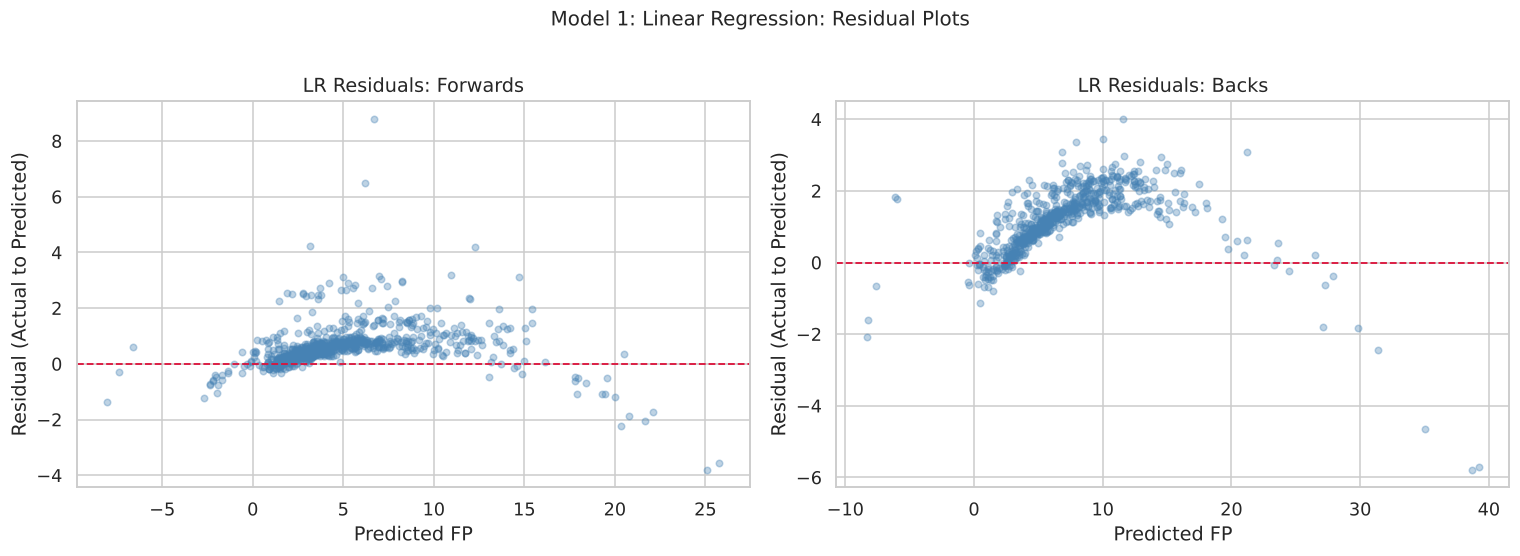

In [38]:
# 14.4  Residual plot: Linear Regression 

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, y_true, y_pred, group in zip(
    axes,
    [y_val_fwd, y_val_bck],
    [lr_fwd_val_pred, lr_bck_val_pred],
    ['Forwards', 'Backs']
):
    residuals = y_true.values - y_pred
    ax.scatter(y_pred, residuals, alpha=0.35, s=18, color='steelblue')
    ax.axhline(0, color='crimson', linewidth=1.2, linestyle='--')
    ax.set_xlabel('Predicted FP')
    ax.set_ylabel('Residual (Actual to Predicted)')
    ax.set_title(f'LR Residuals: {group}')

plt.suptitle('Model 1: Linear Regression: Residual Plots', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 15. Model 2: Ridge Regression

Ridge regression adds L2 regularization to ordinary least squares, shrinking large coefficients. That helps here because several features are correlated (for example `Minutes`, `minutes_70`, and `minutes_80`, or `roll3_avg_fp` and `prior_season_avg_fp`).

`RidgeCV` selects the regularization strength by 5-fold cross-validation on the training set. The same log target transform from Model 1 is applied.

In [39]:
# 15.1  Scale features
# Ridge is sensitive to feature scale; StandardScaler applied to X only.
# Fit on train, apply to val (no data leakage).

scaler_fwd = StandardScaler()
X_train_fwd_sc = scaler_fwd.fit_transform(X_train_fwd)
X_val_fwd_sc   = scaler_fwd.transform(X_val_fwd)

scaler_bck = StandardScaler()
X_train_bck_sc = scaler_bck.fit_transform(X_train_bck)
X_val_bck_sc   = scaler_bck.transform(X_val_bck)

print('Scaling complete. Train means (should be ~0 after scaling):')
print(f'  Forwards: {X_train_fwd_sc.mean():.4f}')
print(f'  Backs   : {X_train_bck_sc.mean():.4f}')

Scaling complete. Train means (should be ~0 after scaling):
  Forwards: 0.0000
  Backs   : 0.0000


In [40]:
# 15.2  Fit RidgeCV and evaluate: Forwards

ALPHAS = [0.01, 0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]

ridge_fwd = RidgeCV(alphas=ALPHAS, cv=5)
ridge_fwd.fit(X_train_fwd_sc, log_transform(y_train_fwd))

ridge_fwd_val_pred = inv_transform(ridge_fwd.predict(X_val_fwd_sc))

print('Ridge Regression Forwards (validation set)')
print(f'  Best alpha (CV-selected): {ridge_fwd.alpha_}')
results['Ridge_fwd'] = evaluate(y_val_fwd, ridge_fwd_val_pred, label='Forwards')

Ridge Regression Forwards (validation set)
  Best alpha (CV-selected): 50.0
  Forwards
    RMSE : 1.020 FP
    MAE  : 0.728 FP
    R²   : 0.944


In [41]:
# 15.3  Fit RidgeCV and evaluate: Backs 

ridge_bck = RidgeCV(alphas=ALPHAS, cv=5)
ridge_bck.fit(X_train_bck_sc, log_transform(y_train_bck))

ridge_bck_val_pred = inv_transform(ridge_bck.predict(X_val_bck_sc))

print('Ridge Regression Backs (validation set)')
print(f'  Best alpha (CV-selected): {ridge_bck.alpha_}')
results['Ridge_bck'] = evaluate(y_val_bck, ridge_bck_val_pred, label='Backs')

Ridge Regression Backs (validation set)
  Best alpha (CV-selected): 10.0
  Backs
    RMSE : 1.503 FP
    MAE  : 1.285 FP
    R²   : 0.924


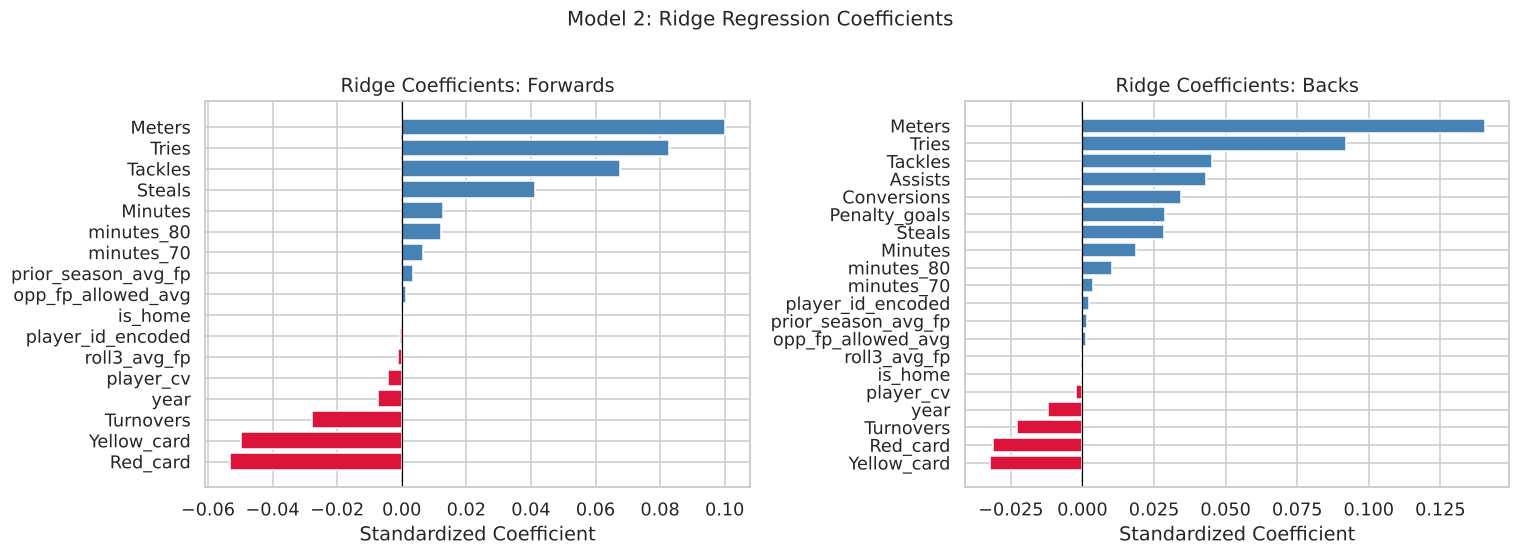

In [42]:
# 15.4  Ridge coefficient plot

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, features, group in zip(
    axes,
    [ridge_fwd, ridge_bck],
    [FWD_FEATURES, BCK_FEATURES],
    ['Forwards', 'Backs']
):
    coef_df = (
        pd.DataFrame({'Feature': features, 'Coefficient': model.coef_})
        .sort_values('Coefficient')
    )
    colors = ['crimson' if c < 0 else 'steelblue' for c in coef_df['Coefficient']]
    ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'Ridge Coefficients: {group}')
    ax.set_xlabel('Standardized Coefficient')

plt.suptitle('Model 2: Ridge Regression Coefficients', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 16. Model 3: Random Forest

Reasonable default hyperparameters (300 trees, minimum 5 samples per leaf). Random forest is included as a nonlinear reference point; XGBoost receives the full tuning treatment in Section 21. `random_state=42` is set for reproducibility.

In [43]:
# 16.1  Fit and evaluate: Forwards

rf_fwd = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,         # trees grow fully; pruned implicitly by min_samples_leaf
    min_samples_leaf=5,     # prevents overfitting on small leaves
    max_features='sqrt',    # standard for regression RF
    random_state=42,
    n_jobs=-1
)
rf_fwd.fit(X_train_fwd, y_train_fwd)

rf_fwd_val_pred = rf_fwd.predict(X_val_fwd)

print('Random Forest Forwards (validation set)')
results['RF_fwd'] = evaluate(y_val_fwd, rf_fwd_val_pred, label='Forwards')


Random Forest Forwards (validation set)
  Forwards
    RMSE : 1.406 FP
    MAE  : 0.860 FP
    R²   : 0.893


In [44]:
# 16.2  Fit and evaluate: Backs

rf_bck = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf_bck.fit(X_train_bck, y_train_bck)

rf_bck_val_pred = rf_bck.predict(X_val_bck)

print('Random Forest Backs (validation set)')
results['RF_bck'] = evaluate(y_val_bck, rf_bck_val_pred, label='Backs')

Random Forest Backs (validation set)
  Backs
    RMSE : 2.202 FP
    MAE  : 1.432 FP
    R²   : 0.837


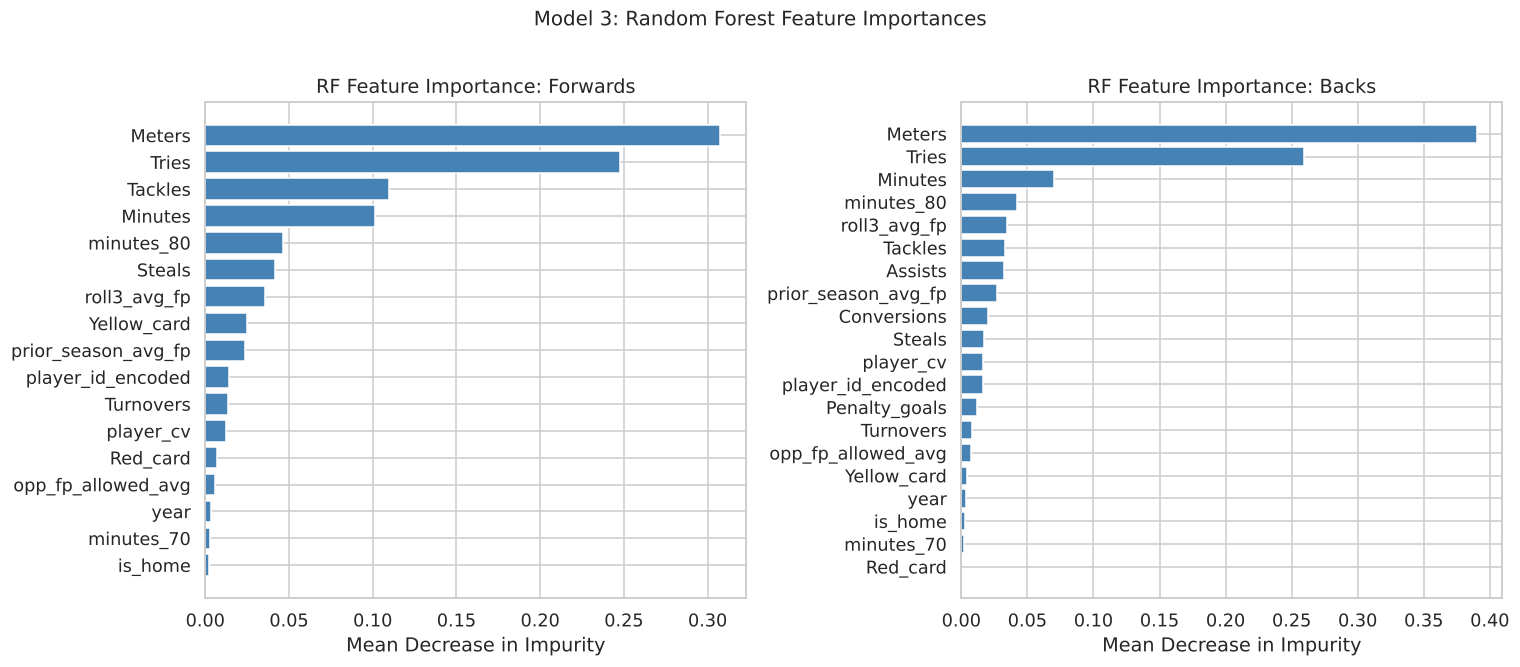

In [45]:
# 16.3  Feature importance plot

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, model, features, group in zip(
    axes,
    [rf_fwd, rf_bck],
    [FWD_FEATURES, BCK_FEATURES],
    ['Forwards', 'Backs']
):
    imp_df = (
        pd.DataFrame({'Feature': features, 'Importance': model.feature_importances_})
        .sort_values('Importance', ascending=True)
    )
    ax.barh(imp_df['Feature'], imp_df['Importance'], color='steelblue')
    ax.set_title(f'RF Feature Importance: {group}')
    ax.set_xlabel('Mean Decrease in Impurity')

plt.suptitle('Model 3: Random Forest Feature Importances', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

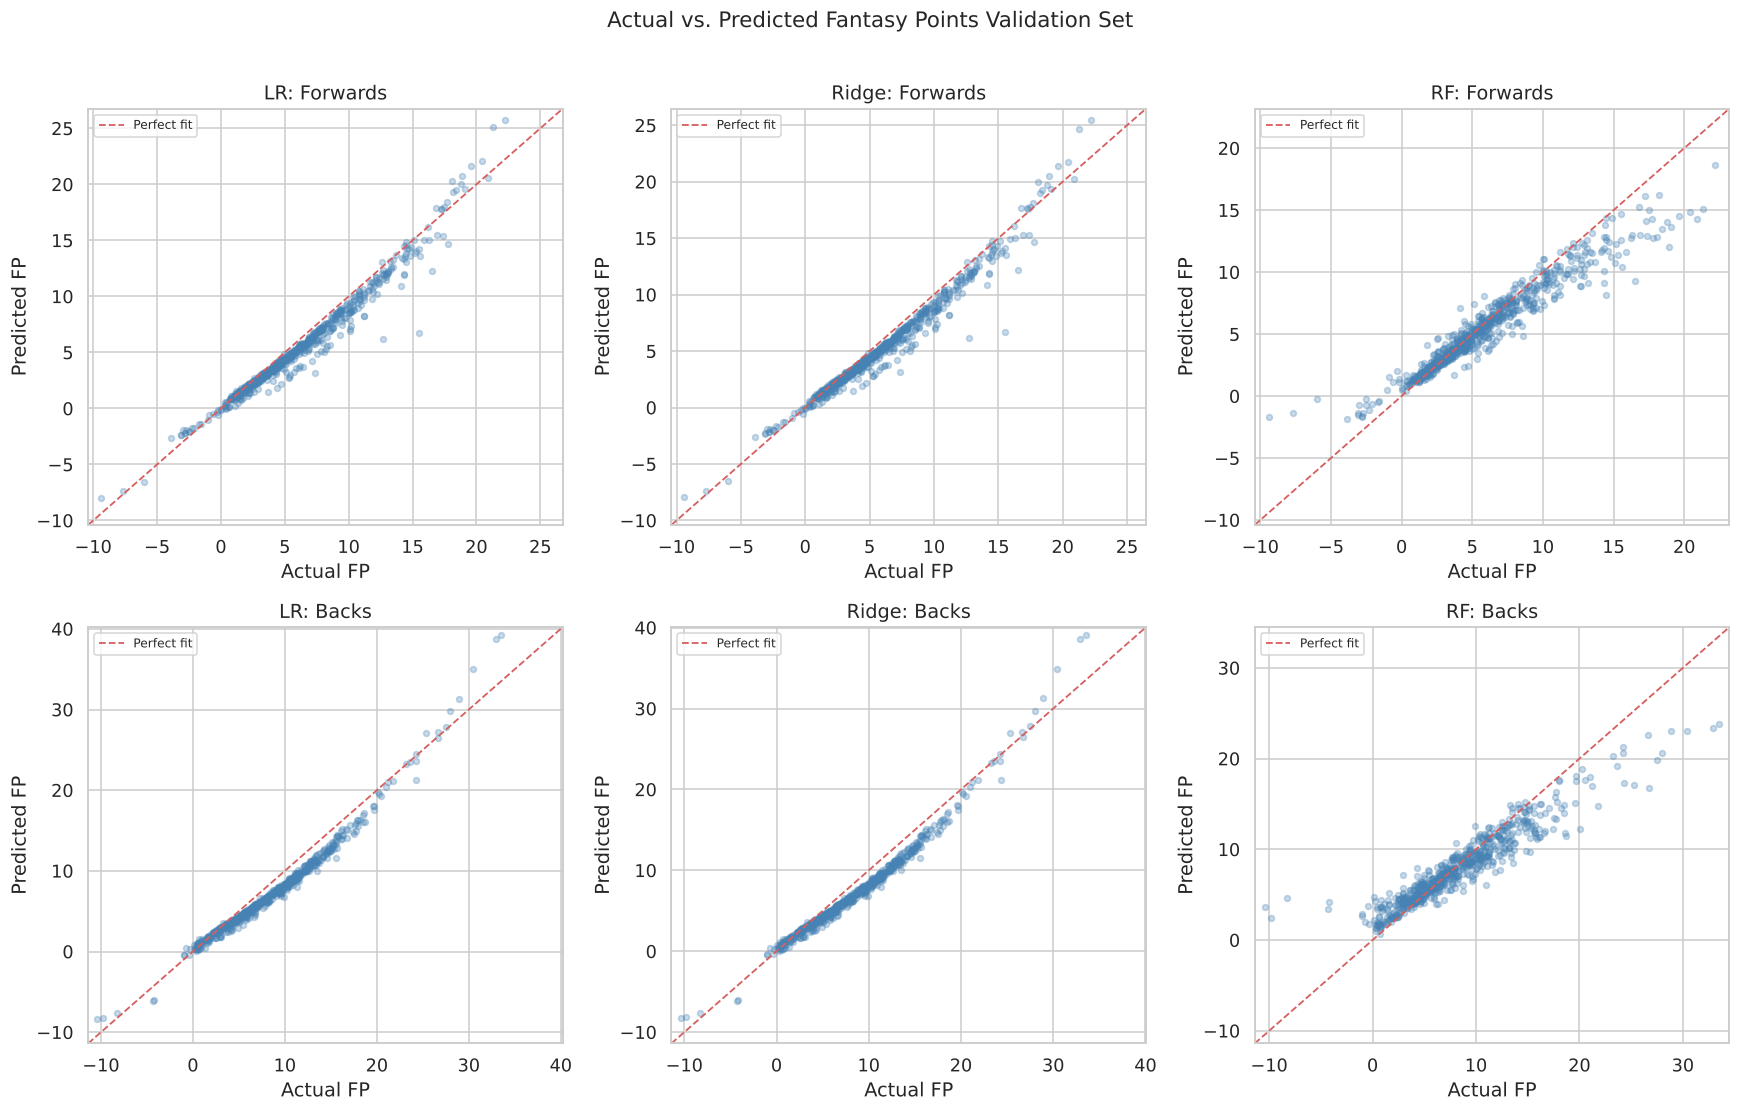

In [46]:
# 16.4  Actual vs. Predicted plot: all three models

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

model_preds = [
    ('LR',    lr_fwd_val_pred,    lr_bck_val_pred),
    ('Ridge', ridge_fwd_val_pred, ridge_bck_val_pred),
    ('RF',    rf_fwd_val_pred,    rf_bck_val_pred),
]

for col, (name, fwd_pred, bck_pred) in enumerate(model_preds):
    for row, (y_true, y_pred, group) in enumerate([
        (y_val_fwd, fwd_pred, 'Forwards'),
        (y_val_bck, bck_pred, 'Backs')
    ]):
        ax = axes[row][col]
        ax.scatter(y_true, y_pred, alpha=0.3, s=15, color='steelblue')
        lims = [min(y_true.min(), y_pred.min()) - 1,
                max(y_true.max(), y_pred.max()) + 1]
        ax.plot(lims, lims, 'r--', linewidth=1.2, label='Perfect fit')
        ax.set_xlim(lims); ax.set_ylim(lims)
        ax.set_xlabel('Actual FP')
        ax.set_ylabel('Predicted FP')
        ax.set_title(f'{name}: {group}')
        ax.legend(fontsize=8)

plt.suptitle('Actual vs. Predicted Fantasy Points Validation Set', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 17. Model Comparison Summary (Validation Set)

All three models evaluated on the 2025 Rounds 1–10 validation set.
RMSE and MAE are in original fantasy-point units. Lower is better for
error metrics; higher is better for R².

In [47]:
# 17.1  Summary table

summary_rows = []
for key, metrics in results.items():
    model_name, group = key.rsplit('_', 1)
    summary_rows.append({
        'Model'  : model_name,
        'Group'  : 'Forwards' if group == 'fwd' else 'Backs',
        'RMSE'   : round(metrics['rmse'], 3),
        'MAE'    : round(metrics['mae'],  3),
        'R²'     : round(metrics['r2'],   3),
    })

summary_df = pd.DataFrame(summary_rows)
print('Model Comparison Validation Set (2025 Rds 1–10)')
print('=' * 58)
print(summary_df.to_string(index=False))
print()
print('Next: Models 4 (XGBoost) and 5 (ElasticNet)')

Model Comparison Validation Set (2025 Rds 1–10)
Model    Group  RMSE   MAE    R²
   LR Forwards 1.019 0.728 0.944
   LR    Backs 1.503 1.284 0.924
Ridge Forwards 1.020 0.728 0.944
Ridge    Backs 1.503 1.285 0.924
   RF Forwards 1.406 0.860 0.893
   RF    Backs 2.202 1.432 0.837

Next: Models 4 (XGBoost) and 5 (ElasticNet)


## 18. Model 4: XGBoost (Gradient Boosted Trees)

No target transformation is required; tree models are robust to moderate skew. Hyperparameters here are reasonable defaults; Section 21 tunes them.

Early stopping uses the validation set to decide when to stop adding trees. That makes validation scores for XGBoost slightly optimistic, which is why the untouched test set (Section 24) is the number to trust. `random_state=42` is set for reproducibility.

In [48]:
# 18.1  Import XGBoost (install with: pip install xgboost)
from xgboost import XGBRegressor

In [49]:
# 18.2  Fit and evaluate: Forwards 
# early_stopping_rounds=20: stops if val RMSE hasn't improved in 20 rounds.
# Val split used for early stopping, so val metrics are slightly optimistic

xgb_fwd = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,             # shallow trees reduce overfitting on ~7k rows
    subsample=0.8,           # row-level bagging per tree
    colsample_bytree=0.8,    # feature-level bagging per tree
    min_child_weight=5,      # analogous to min_samples_leaf in RF
    reg_lambda=1.0,          # L2 regularization
    reg_alpha=0.1,           # L1 regularization
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    early_stopping_rounds=20
)

xgb_fwd.fit(
    X_train_fwd, y_train_fwd,
    eval_set=[(X_val_fwd, y_val_fwd)],
    verbose=False
)

xgb_fwd_val_pred = xgb_fwd.predict(X_val_fwd)

print('XGBoost Forwards (validation set)')
print(f'  Best iteration: {xgb_fwd.best_iteration}')
results['XGB_fwd'] = evaluate(y_val_fwd, xgb_fwd_val_pred, label='Forwards')

XGBoost Forwards (validation set)
  Best iteration: 135
  Forwards
    RMSE : 0.774 FP
    MAE  : 0.473 FP
    R²   : 0.968


In [50]:
# 18.3  Fit and evaluate: Backs

xgb_bck = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_lambda=1.0,
    reg_alpha=0.1,
    random_state=42,
    n_jobs=-1,
    verbosity=0,
    early_stopping_rounds=20
)

xgb_bck.fit(
    X_train_bck, y_train_bck,
    eval_set=[(X_val_bck, y_val_bck)],
    verbose=False
)

xgb_bck_val_pred = xgb_bck.predict(X_val_bck)

print('XGBoost Backs (validation set)')
print(f'  Best iteration: {xgb_bck.best_iteration}')
results['XGB_bck'] = evaluate(y_val_bck, xgb_bck_val_pred, label='Backs')

XGBoost Backs (validation set)
  Best iteration: 218
  Backs
    RMSE : 0.960 FP
    MAE  : 0.685 FP
    R²   : 0.969


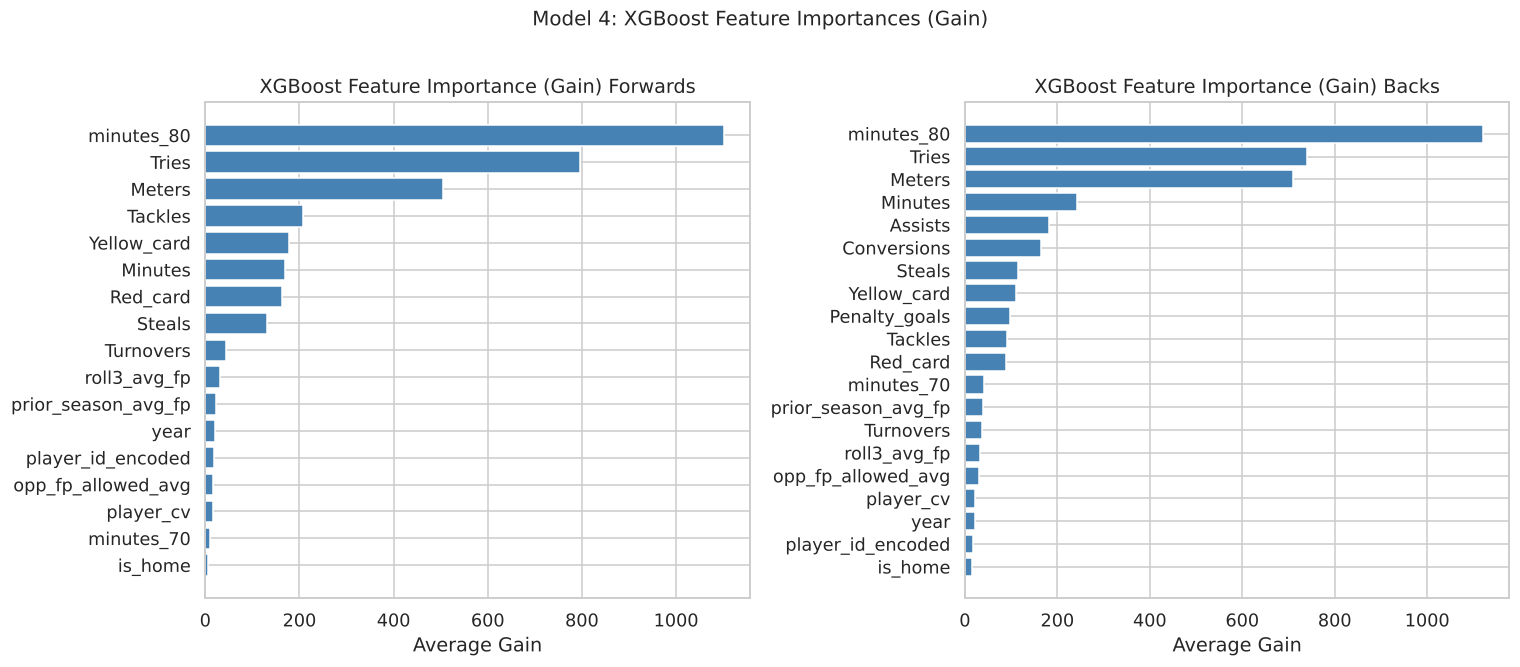

In [51]:
# 18.4  XGBoost feature importance plot
# 'gain' importance: average improvement in loss brought by a feature
# across all splits where it is used. More meaningful than frequency-based
# importance for sparse or correlated features.

import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, model, features, group in zip(
    axes,
    [xgb_fwd, xgb_bck],
    [FWD_FEATURES, BCK_FEATURES],
    ['Forwards', 'Backs']
):
    imp = model.get_booster().get_score(importance_type='gain')
    imp_df = (
        pd.DataFrame({'Feature': list(imp.keys()), 'Gain': list(imp.values())})
        .sort_values('Gain', ascending=True)
    )
    ax.barh(imp_df['Feature'], imp_df['Gain'], color='steelblue')
    ax.set_title(f'XGBoost Feature Importance (Gain) {group}')
    ax.set_xlabel('Average Gain')

plt.suptitle('Model 4: XGBoost Feature Importances (Gain)', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


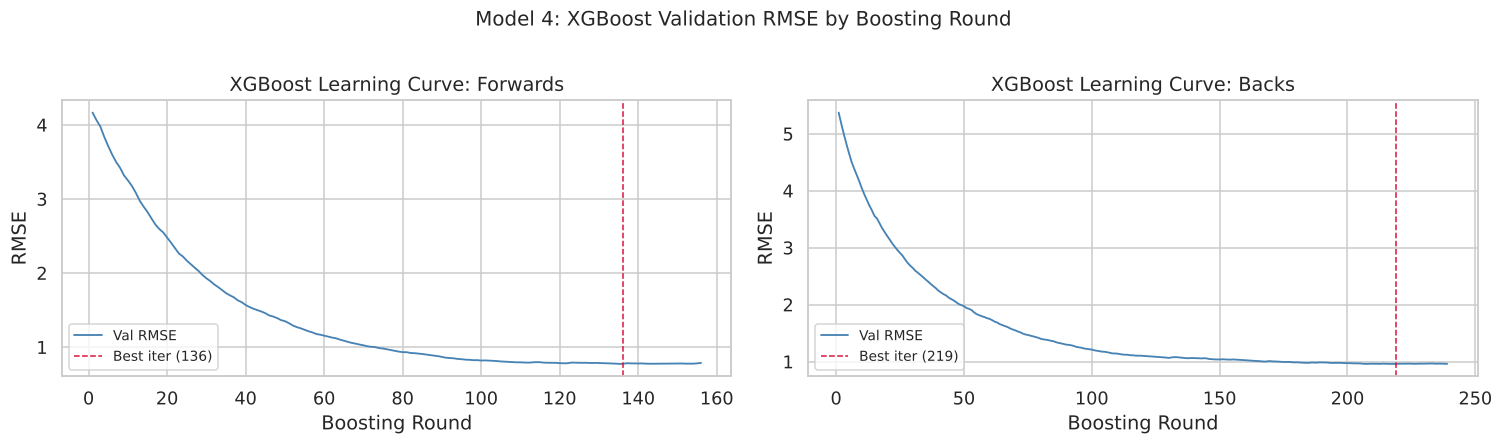

In [52]:
# 18.5  XGBoost learning curve
# Plots val RMSE across boosting rounds to check convergence.

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

for ax, model, group in zip(axes, [xgb_fwd, xgb_bck], ['Forwards', 'Backs']):
    evals = model.evals_result()
    val_rmse = evals['validation_0']['rmse']
    best_iter = model.best_iteration  # safe: early_stopping_rounds is set
    rounds = range(1, len(val_rmse) + 1)
    ax.plot(rounds, val_rmse, color='steelblue', linewidth=1.2, label='Val RMSE')
    ax.axvline(best_iter + 1, color='crimson', linestyle='--',
               linewidth=1, label=f'Best iter ({best_iter + 1})')
    ax.set_xlabel('Boosting Round')
    ax.set_ylabel('RMSE')
    ax.set_title(f'XGBoost Learning Curve: {group}')
    ax.legend(fontsize=9)

plt.suptitle('Model 4: XGBoost Validation RMSE by Boosting Round', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 19. Model 5: ElasticNet

`ElasticNetCV` performs k-fold cross-validation on the training set to jointly
select the best `alpha` (regularization strength) and `l1_ratio`. The same
`log1p` target transform from Models 1 and 2 is applied.

In [53]:
# 19.1  Import ElasticNetCV

from sklearn.linear_model import ElasticNetCV

print('ElasticNetCV import OK')


ElasticNetCV import OK


In [54]:
# 19.2  Fit and evaluate: Forwards 
# Features are already scaled (scaler_fwd fitted in Section 15).
# l1_ratio grid: 0.1 = mostly Ridge, 0.9 = mostly Lasso, 1.0 = pure Lasso.

L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0]

en_fwd = ElasticNetCV(
    l1_ratio=L1_RATIOS,
    alphas=np.logspace(-5, 0, 50),
    cv=5,
    max_iter=5000,
    random_state=42
)
en_fwd.fit(X_train_fwd_sc, log_transform(y_train_fwd))

en_fwd_val_pred = inv_transform(en_fwd.predict(X_val_fwd_sc))

print('ElasticNet Forwards (validation set)')
print(f'  Best alpha   : {en_fwd.alpha_:.5f}')
print(f'  Best l1_ratio: {en_fwd.l1_ratio_:.2f}  '
      f'(0=Ridge, 1=Lasso)')
results['EN_fwd'] = evaluate(y_val_fwd, en_fwd_val_pred, label='Forwards')

ElasticNet Forwards (validation set)
  Best alpha   : 0.00720
  Best l1_ratio: 0.10  (0=Ridge, 1=Lasso)
  Forwards
    RMSE : 0.968 FP
    MAE  : 0.662 FP
    R²   : 0.949


In [55]:
# 19.3  Fit and evaluate: Backs

en_bck = ElasticNetCV(
    l1_ratio=L1_RATIOS,
    alphas=np.logspace(-5, 0, 50),
    cv=5,
    max_iter=5000,
    random_state=42
)
en_bck.fit(X_train_bck_sc, log_transform(y_train_bck))

en_bck_val_pred = inv_transform(en_bck.predict(X_val_bck_sc))

print('ElasticNet: Backs (validation set)')
print(f'  Best alpha   : {en_bck.alpha_:.5f}')
print(f'  Best l1_ratio: {en_bck.l1_ratio_:.2f}  '
      f'(0=Ridge, 1=Lasso)')
results['EN_bck'] = evaluate(y_val_bck, en_bck_val_pred, label='Backs')

ElasticNet: Backs (validation set)
  Best alpha   : 0.00054
  Best l1_ratio: 0.90  (0=Ridge, 1=Lasso)


  Backs
    RMSE : 1.454 FP
    MAE  : 1.237 FP
    R²   : 0.929


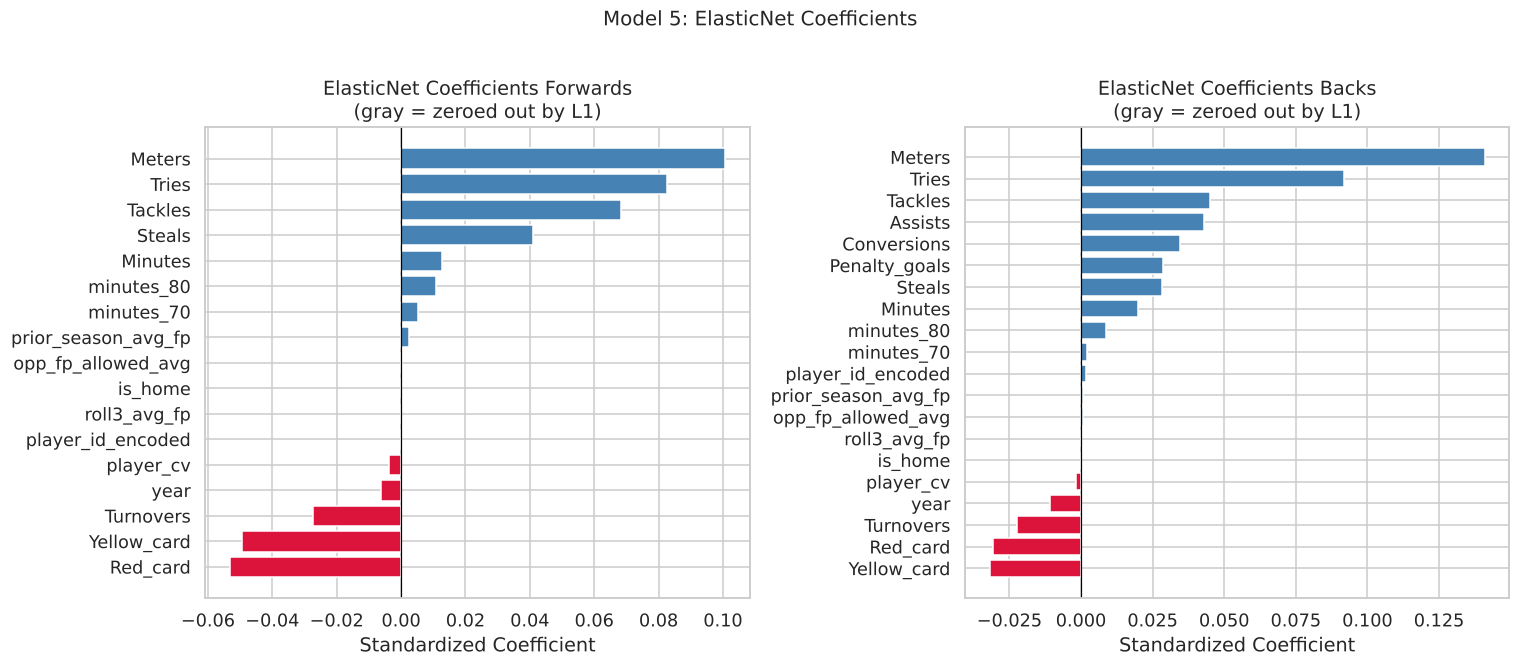

In [56]:
# 19.4  ElasticNet coefficient plot
# Zero coefficients = features driven out by L1 penalty (automatic selection).

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, model, features, group in zip(
    axes,
    [en_fwd, en_bck],
    [FWD_FEATURES, BCK_FEATURES],
    ['Forwards', 'Backs']
):
    coef_df = (
        pd.DataFrame({'Feature': features, 'Coefficient': model.coef_})
        .sort_values('Coefficient')
    )
    colors = ['crimson' if c < 0 else
              'lightgray' if c == 0 else
              'steelblue' for c in coef_df['Coefficient']]
    ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'ElasticNet Coefficients {group}\n'
                 f'(gray = zeroed out by L1)')
    ax.set_xlabel('Standardized Coefficient')

plt.suptitle('Model 5: ElasticNet Coefficients', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

## 20. Final Model Comparison: All 5 Models

Complete summary across all models and both position groups on the
2025 Rounds 1–10 validation set. The held-out test set (2025 Rds 11+)
remains untouched until Section 24.

In [57]:
# 20.1  Full comparison table

MODEL_ORDER = ['LR', 'Ridge', 'EN', 'RF', 'XGB']
GROUP_ORDER = ['Forwards', 'Backs']

summary_rows = []
for key, metrics in results.items():
    model_name, group_code = key.rsplit('_', 1)
    summary_rows.append({
        'Model' : model_name,
        'Group' : 'Forwards' if group_code == 'fwd' else 'Backs',
        'RMSE'  : round(metrics['rmse'], 3),
        'MAE'   : round(metrics['mae'],  3),
        'R²'    : round(metrics['r2'],   3),
    })

summary_df = (
    pd.DataFrame(summary_rows)
    .assign(
        Model=lambda d: pd.Categorical(d['Model'], categories=MODEL_ORDER, ordered=True),
        Group=lambda d: pd.Categorical(d['Group'], categories=GROUP_ORDER, ordered=True)
    )
    .sort_values(['Group', 'Model'])
)

print('All Models: Validation Set (2025 Rds 1–10)')
print('=' * 55)
print(summary_df.to_string(index=False))

All Models: Validation Set (2025 Rds 1–10)
Model    Group  RMSE   MAE    R²
   LR Forwards 1.019 0.728 0.944
Ridge Forwards 1.020 0.728 0.944
   EN Forwards 0.968 0.662 0.949
   RF Forwards 1.406 0.860 0.893
  XGB Forwards 0.774 0.473 0.968
   LR    Backs 1.503 1.284 0.924
Ridge    Backs 1.503 1.285 0.924
   EN    Backs 1.454 1.237 0.929
   RF    Backs 2.202 1.432 0.837
  XGB    Backs 0.960 0.685 0.969


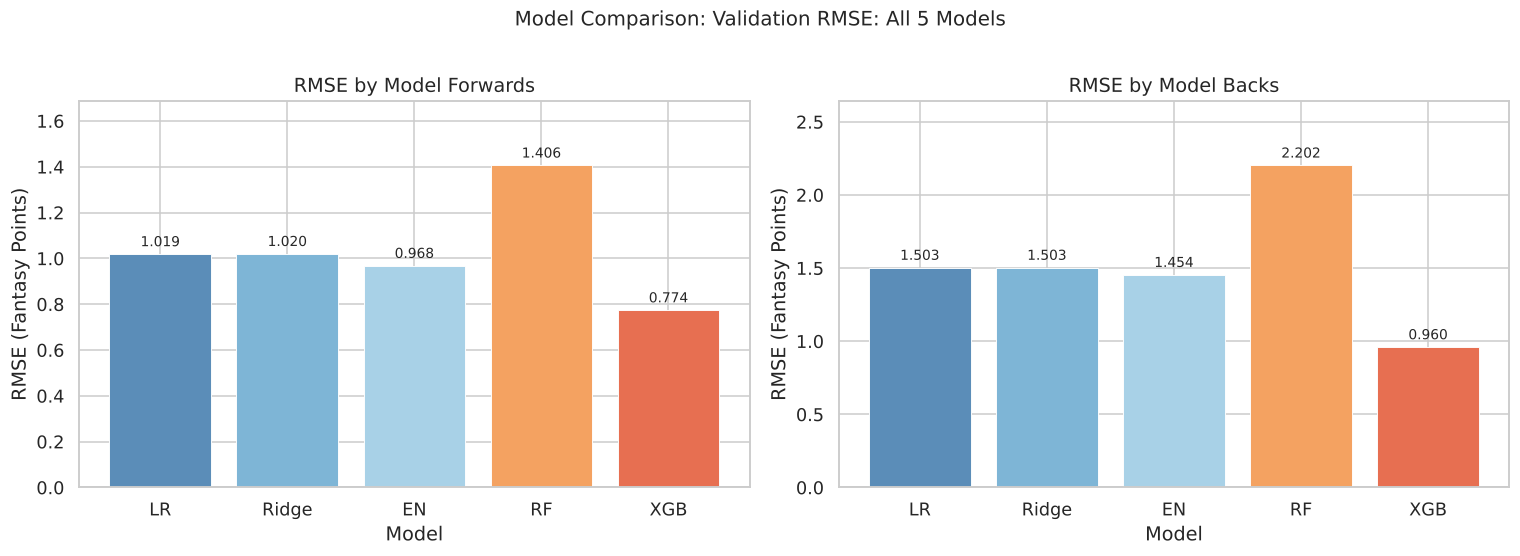

In [58]:
# 20.2  RMSE comparison bar chart

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

palette = {
    'LR'   : '#5b8db8',
    'Ridge': '#7eb5d6',
    'EN'   : '#a8d1e7',
    'RF'   : '#f4a261',
    'XGB'  : '#e76f51',
}

for ax, group in zip(axes, GROUP_ORDER):
    grp_df = summary_df[summary_df['Group'] == group]
    colors = [palette[m] for m in grp_df['Model']]
    bars = ax.bar(grp_df['Model'], grp_df['RMSE'], color=colors,
                  edgecolor='white', linewidth=0.6)
    ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=9)
    ax.set_title(f'RMSE by Model {group}')
    ax.set_xlabel('Model')
    ax.set_ylabel('RMSE (Fantasy Points)')
    ax.set_ylim(0, grp_df['RMSE'].max() * 1.2)

plt.suptitle('Model Comparison: Validation RMSE: All 5 Models', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


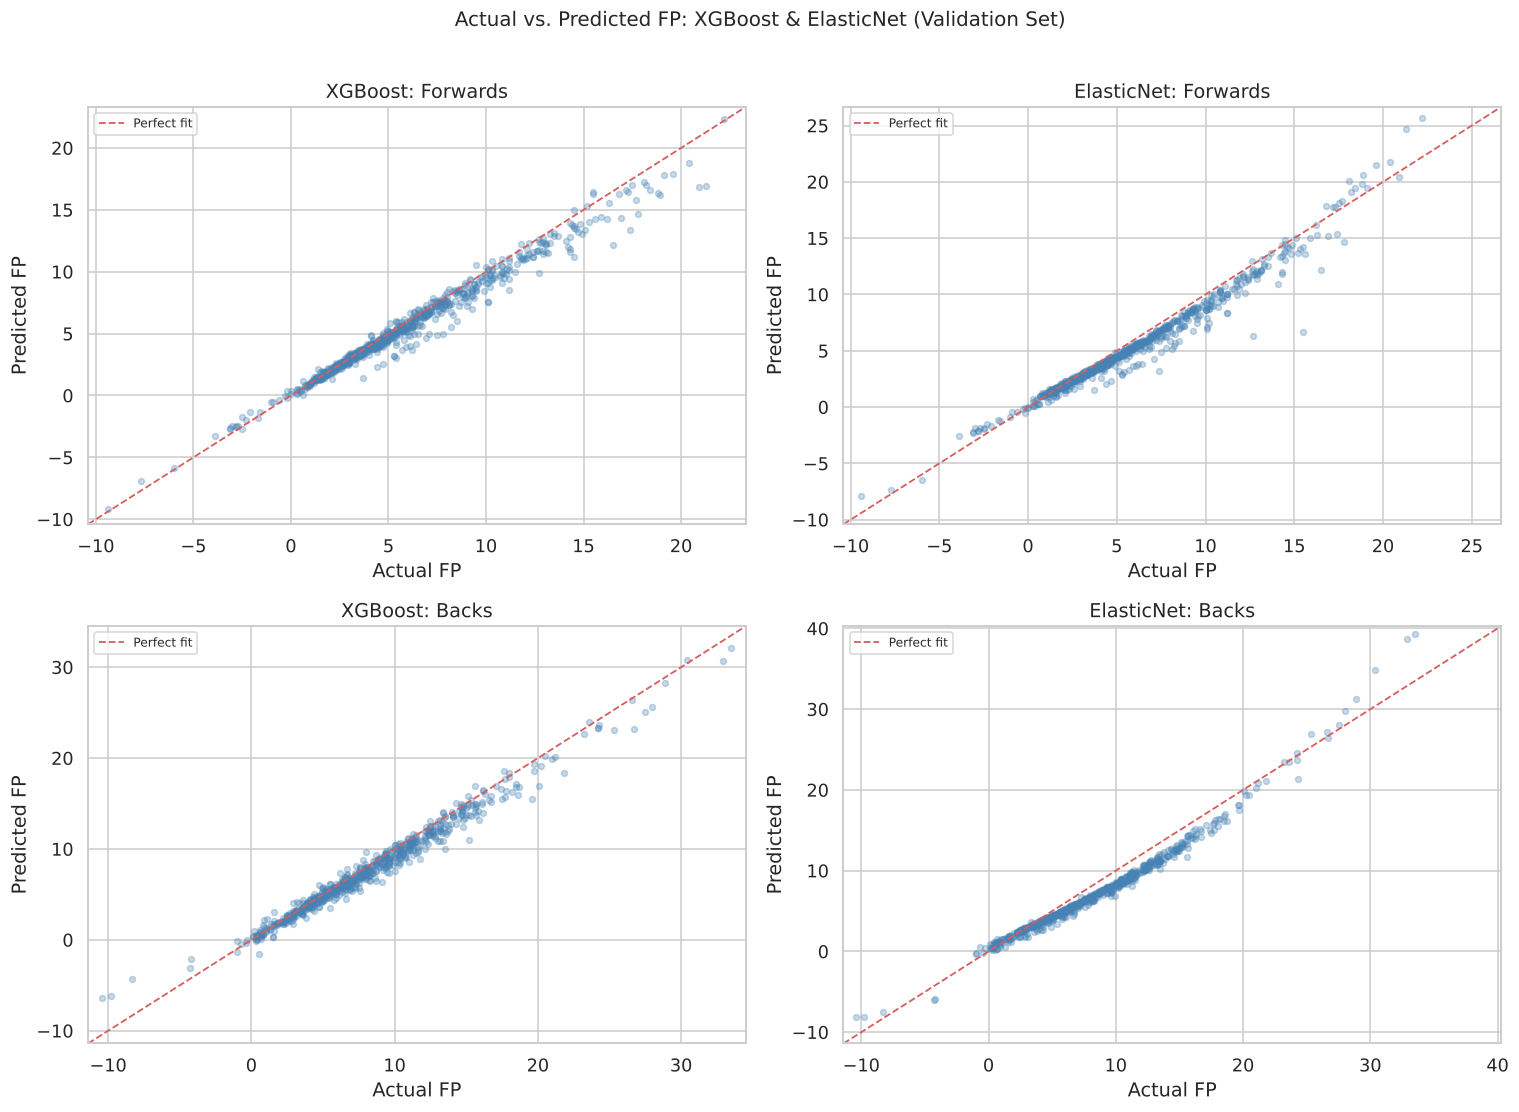

In [59]:
# 20.3  Actual vs. Predicted: XGBoost and ElasticNet
# Linear models were plotted in Section 14. This cell covers the two new models.

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

model_preds = [
    ('XGBoost',    xgb_fwd_val_pred, xgb_bck_val_pred),
    ('ElasticNet', en_fwd_val_pred,  en_bck_val_pred),
]

for col, (name, fwd_pred, bck_pred) in enumerate(model_preds):
    for row, (y_true, y_pred, group) in enumerate([
        (y_val_fwd, fwd_pred, 'Forwards'),
        (y_val_bck, bck_pred, 'Backs')
    ]):
        ax = axes[row][col]
        ax.scatter(y_true, y_pred, alpha=0.3, s=15, color='steelblue')
        lims = [min(y_true.min(), y_pred.min()) - 1,
                max(y_true.max(), y_pred.max()) + 1]
        ax.plot(lims, lims, 'r--', linewidth=1.2, label='Perfect fit')
        ax.set_xlim(lims); ax.set_ylim(lims)
        ax.set_xlabel('Actual FP')
        ax.set_ylabel('Predicted FP')
        ax.set_title(f'{name}: {group}')
        ax.legend(fontsize=8)

plt.suptitle('Actual vs. Predicted FP: XGBoost & ElasticNet (Validation Set)',
             fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [60]:
# 20.4  Modeling phase summary

val_table = summary_df.set_index(['Group', 'Model'])['RMSE']
print('IN-GAME MODELS: VALIDATION SUMMARY (2025 Rds 1-10)')
print()
for group in GROUP_ORDER:
    g = val_table.loc[group].sort_values()
    print(f'{group}: best = {g.index[0]} (RMSE {g.iloc[0]:.3f}), worst = {g.index[-1]} (RMSE {g.iloc[-1]:.3f})')
lin_gap = {grp: val_table.loc[grp][['LR', 'Ridge', 'EN']].min() - val_table.loc[grp]['XGB'] for grp in GROUP_ORDER}
print()
print('Observations:')
print(f'  - XGBoost beats the best linear model by {lin_gap["Forwards"]:.3f} FP RMSE for forwards and '
      f'{lin_gap["Backs"]:.3f} for backs, before tuning.')
print('  - Random forest is the weakest model for both groups.')
print('  - Backs are harder to predict than forwards for every model; FH kicking adds variance.')
print('  - All of these models use in-game statistics, so low error here mostly reflects the')
print('    scoring formula. Section 25 addresses the real forecasting question.')

IN-GAME MODELS: VALIDATION SUMMARY (2025 Rds 1-10)

Forwards: best = XGB (RMSE 0.774), worst = RF (RMSE 1.406)
Backs: best = XGB (RMSE 0.960), worst = RF (RMSE 2.202)

Observations:
  - XGBoost beats the best linear model by 0.194 FP RMSE for forwards and 0.494 for backs, before tuning.
  - Random forest is the weakest model for both groups.
  - Backs are harder to predict than forwards for every model; FH kicking adds variance.
  - All of these models use in-game statistics, so low error here mostly reflects the
    scoring formula. Section 25 addresses the real forecasting question.


## 21. XGBoost Hyperparameter Tuning

Exhaustive grid search across five hyperparameters for both position groups.
The validation set (2025 Rds 1-10) is used as the evaluation target throughout.
The held-out test set is never touched during tuning.

Early stopping (20 rounds) is applied inside each candidate fit so that
`n_estimators` is not a tuning axis. It self-selects via the learning curve.

**Grid axes:**
- `learning_rate`: controls step size per boosting round
- `max_depth`: controls tree complexity (overfitting risk)
- `subsample`: row-level bagging fraction per tree
- `colsample_bytree`: feature-level bagging fraction per tree
- `min_child_weight`: minimum sum of instance weights in a leaf (regularization)

In [61]:
# 21.1  Define exhaustive hyperparameter grid
# 4 × 4 × 3 × 3 × 3 = 432 candidate combinations per position group

from itertools import product

PARAM_GRID = {
    'learning_rate'    : [0.01, 0.05, 0.1, 0.2],
    'max_depth'        : [3, 4, 6, 8],
    'subsample'        : [0.6, 0.8, 1.0],
    'colsample_bytree' : [0.6, 0.8, 1.0],
    'min_child_weight' : [1, 5, 10],
}

# Building a flat list of all combinations
keys   = list(PARAM_GRID.keys())
values = list(PARAM_GRID.values())
all_combos = [dict(zip(keys, v)) for v in product(*values)]

print(f'Total grid combinations: {len(all_combos):,}')
print(f'Per position group, so {len(all_combos)*2:,} total fits')
print()
print('Grid axes:')
for k, v in PARAM_GRID.items():
    print(f'  {k}: {v}')

Total grid combinations: 432
Per position group, so 864 total fits

Grid axes:
  learning_rate: [0.01, 0.05, 0.1, 0.2]
  max_depth: [3, 4, 6, 8]
  subsample: [0.6, 0.8, 1.0]
  colsample_bytree: [0.6, 0.8, 1.0]
  min_child_weight: [1, 5, 10]


In [62]:
# 21.2  Grid search: Forwards
# Each candidate is fit with early stopping on the val set.
# Best candidate = lowest val RMSE at its best_iteration.

from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

def run_grid_search(X_train, y_train, X_val, y_val, grid, label):
    best_rmse   = np.inf
    best_params = None
    best_iter   = None
    results_log = []

    for i, params in enumerate(grid):
        model = XGBRegressor(
            n_estimators       = 1000,   # high ceiling; early stopping controls actual count
            learning_rate      = params['learning_rate'],
            max_depth          = params['max_depth'],
            subsample          = params['subsample'],
            colsample_bytree   = params['colsample_bytree'],
            min_child_weight   = params['min_child_weight'],
            reg_lambda         = 1.0,    # fixed L2 regularization
            reg_alpha          = 0.1,    # fixed L1 regularization
            random_state       = 42,
            n_jobs             = -1,
            verbosity          = 0,
            early_stopping_rounds = 20
        )
        model.fit(
            X_train, y_train,
            eval_set   = [(X_val, y_val)],
            verbose    = False
        )
        pred = model.predict(X_val)
        rmse = mean_squared_error(y_val, pred) ** 0.5

        results_log.append({**params, 'best_iteration': model.best_iteration, 'val_rmse': round(rmse, 5)})

        if rmse < best_rmse:
            best_rmse   = rmse
            best_params = params.copy()
            best_iter   = model.best_iteration
            best_model  = model

        if (i + 1) % 50 == 0:
            print(f'  [{label}] {i+1}/{len(grid)} fits completed  |  best RMSE so far: {best_rmse:.4f}')

    results_df = pd.DataFrame(results_log).sort_values('val_rmse').reset_index(drop=True)
    return best_model, best_params, best_rmse, best_iter, results_df

print('Starting grid search: Forwards  (432 fits)...')
xgb_fwd_best, fwd_best_params, fwd_best_rmse, fwd_best_iter, fwd_grid_results = run_grid_search(
    X_train_fwd, y_train_fwd, X_val_fwd, y_val_fwd, all_combos, 'Forwards'
)

print()
print('Forwards Grid Search Results')
print(f'Best val RMSE : {fwd_best_rmse:.4f} FP')
print(f'Best iteration: {fwd_best_iter}')
print(f'Best params   :')
for k, v in fwd_best_params.items():
    print(f'  {k}: {v}')

Starting grid search: Forwards  (432 fits)...


  [Forwards] 50/432 fits completed  |  best RMSE so far: 0.6948


  [Forwards] 100/432 fits completed  |  best RMSE so far: 0.6948


  [Forwards] 150/432 fits completed  |  best RMSE so far: 0.6948


  [Forwards] 200/432 fits completed  |  best RMSE so far: 0.6948


  [Forwards] 250/432 fits completed  |  best RMSE so far: 0.6925


  [Forwards] 300/432 fits completed  |  best RMSE so far: 0.6925


  [Forwards] 350/432 fits completed  |  best RMSE so far: 0.6925


  [Forwards] 400/432 fits completed  |  best RMSE so far: 0.6925



Forwards Grid Search Results
Best val RMSE : 0.6925 FP
Best iteration: 154
Best params   :
  learning_rate: 0.1
  max_depth: 3
  subsample: 1.0
  colsample_bytree: 0.6
  min_child_weight: 5


In [63]:
# 21.3  Grid search: Backs
print('Starting grid search: Backs  (432 fits)...')
xgb_bck_best, bck_best_params, bck_best_rmse, bck_best_iter, bck_grid_results = run_grid_search(
    X_train_bck, y_train_bck, X_val_bck, y_val_bck, all_combos, 'Backs'
)

print()
print('Backs Grid Search Results')
print(f'Best val RMSE : {bck_best_rmse:.4f} FP')
print(f'Best iteration: {bck_best_iter}')
print(f'Best params   :')
for k, v in bck_best_params.items():
    print(f'  {k}: {v}')

Starting grid search: Backs  (432 fits)...


  [Backs] 50/432 fits completed  |  best RMSE so far: 0.9267


  [Backs] 100/432 fits completed  |  best RMSE so far: 0.9267


  [Backs] 150/432 fits completed  |  best RMSE so far: 0.8988


  [Backs] 200/432 fits completed  |  best RMSE so far: 0.8988


  [Backs] 250/432 fits completed  |  best RMSE so far: 0.8988


  [Backs] 300/432 fits completed  |  best RMSE so far: 0.8988


  [Backs] 350/432 fits completed  |  best RMSE so far: 0.8988


  [Backs] 400/432 fits completed  |  best RMSE so far: 0.8988



Backs Grid Search Results
Best val RMSE : 0.8988 FP
Best iteration: 309
Best params   :
  learning_rate: 0.05
  max_depth: 3
  subsample: 1.0
  colsample_bytree: 0.6
  min_child_weight: 1


In [64]:
# 21.4  Top 10 candidates: Forwards and Backs

print('Top 10 Hyperparameter Combinations: Forwards')
print('=' * 70)
print(fwd_grid_results.head(10).to_string(index=False))
print()
print('Top 10 Hyperparameter Combinations: Backs')
print('=' * 70)
print(bck_grid_results.head(10).to_string(index=False))

Top 10 Hyperparameter Combinations: Forwards
 learning_rate  max_depth  subsample  colsample_bytree  min_child_weight  best_iteration  val_rmse
          0.10          3        1.0               0.6                 5             154   0.69252
          0.01          3        0.6               0.6                10             912   0.69476
          0.01          3        0.6               0.6                 5             909   0.69542
          0.10          3        0.8               0.6                10             120   0.70279
          0.01          3        0.6               0.8                10             907   0.70432
          0.10          3        0.8               0.6                 5             134   0.70642
          0.05          3        0.6               1.0                10             220   0.70864
          0.01          3        0.8               0.8                10             967   0.70874
          0.05          3        0.6               0.6          

In [65]:
# 21.5  Tuned vs. baseline XGBoost comparison
# Baseline: the XGBoost with default-calibrated params (Sections 18.2 / 18.3)

from sklearn.metrics import mean_absolute_error, r2_score

def full_metrics(y_true, y_pred, label=''):
    rmse = mean_squared_error(y_true, y_pred) ** 0.5
    mae  = mean_absolute_error(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)
    if label:
        print(f'  {label}')
    print(f'    RMSE : {rmse:.3f} FP')
    print(f'    MAE  : {mae:.3f} FP')
    print(f'    R2   : {r2:.3f}')
    return {'rmse': rmse, 'mae': mae, 'r2': r2}

# Tuned predictions on validation set
xgb_fwd_tuned_pred = xgb_fwd_best.predict(X_val_fwd)
xgb_bck_tuned_pred = xgb_bck_best.predict(X_val_bck)

print('XGBoost Tuned vs. Baseline (Validation Set, 2025 Rds 1-10)')
print('=' * 55)
print()
print('  Forwards ')
print('  Baseline (default parameters):')
full_metrics(y_val_fwd, xgb_fwd_val_pred, label='')
print('  Tuned (best grid params):')
results['XGB_fwd_tuned'] = full_metrics(y_val_fwd, xgb_fwd_tuned_pred, label='')

print()
print(' Backs ')
print('  Baseline (default parameters):')
full_metrics(y_val_bck, xgb_bck_val_pred, label='')
print('  Tuned (best grid params):')
results['XGB_bck_tuned'] = full_metrics(y_val_bck, xgb_bck_tuned_pred, label='')

XGBoost Tuned vs. Baseline (Validation Set, 2025 Rds 1-10)

  Forwards 
  Baseline (default parameters):
    RMSE : 0.774 FP
    MAE  : 0.473 FP
    R2   : 0.968
  Tuned (best grid params):
    RMSE : 0.693 FP
    MAE  : 0.427 FP
    R2   : 0.974

 Backs 
  Baseline (default parameters):
    RMSE : 0.960 FP
    MAE  : 0.685 FP
    R2   : 0.969
  Tuned (best grid params):
    RMSE : 0.899 FP
    MAE  : 0.622 FP
    R2   : 0.973


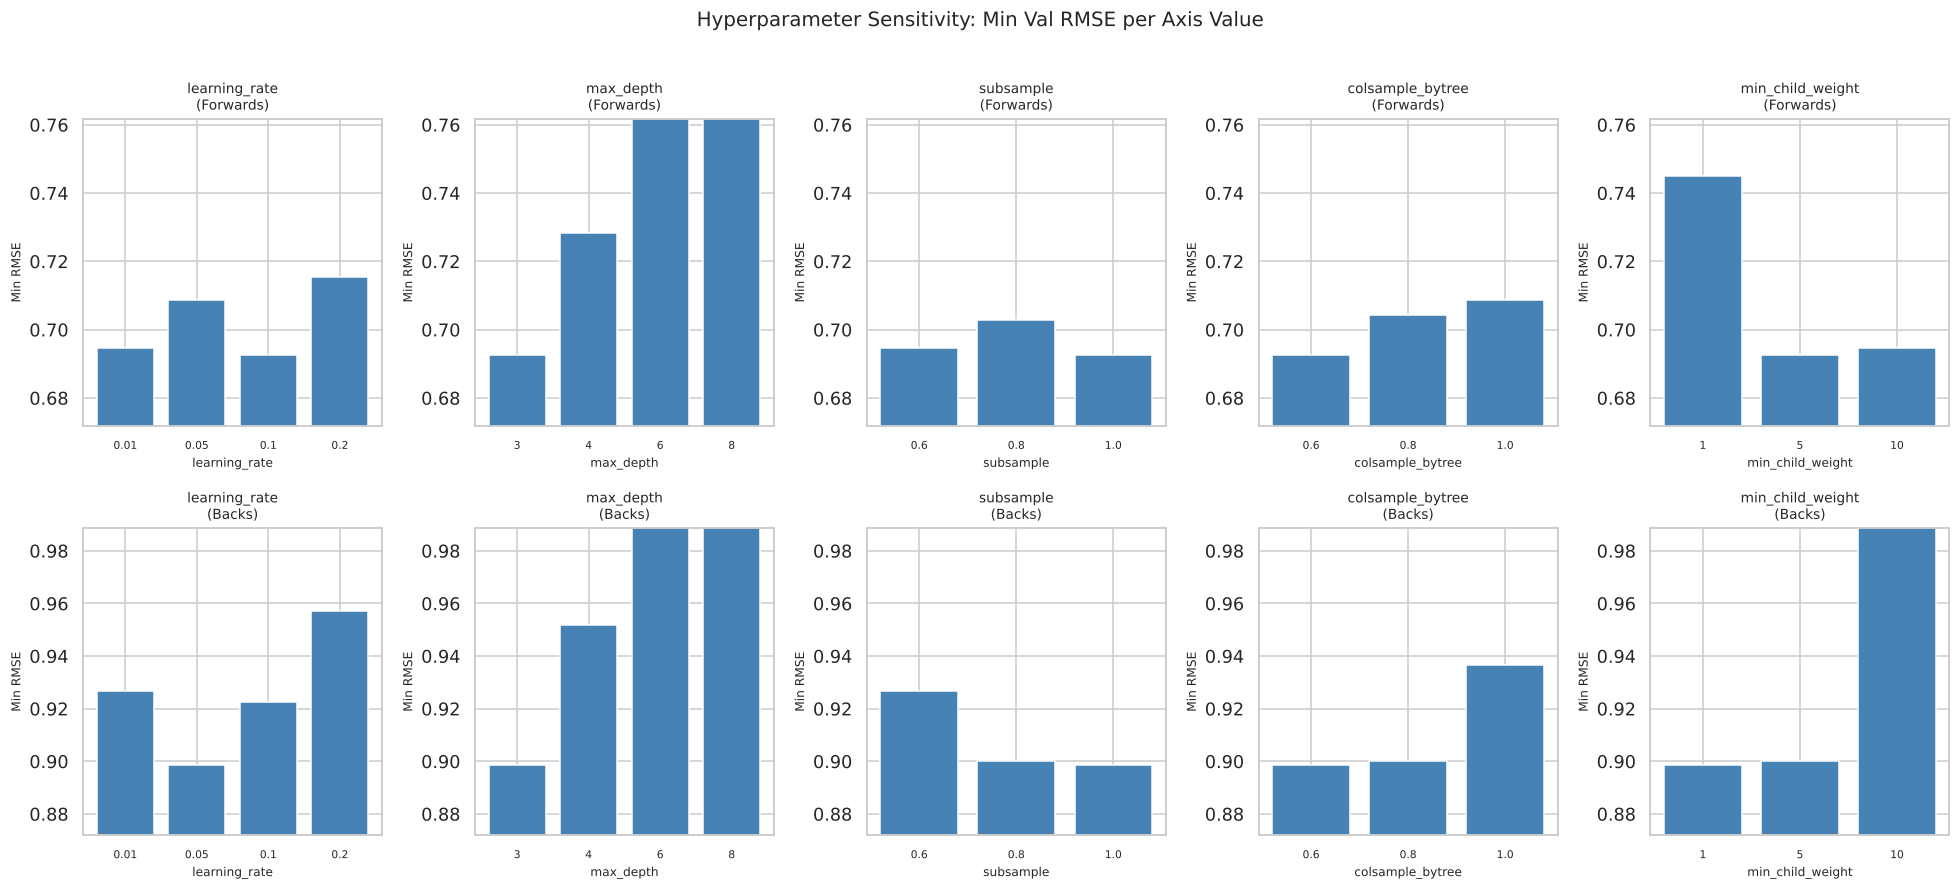

Interpretation: Bars closer to the floor indicate more impactful hyperparameter values.
Flat bars across a parameter suggest low sensitivity on that axis.


In [66]:
# 21.6  Hyperparameter sensitivity: RMSE by key axes
# Aggregates grid results to show which hyperparameters matter most.

import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(18, 8))

param_keys = list(PARAM_GRID.keys())

for row, (grp_results, group) in enumerate(
    [(fwd_grid_results, 'Forwards'), (bck_grid_results, 'Backs')]
):
    for col, param in enumerate(param_keys):
        ax = axes[row][col]
        grouped = grp_results.groupby(param)['val_rmse'].min().reset_index()
        ax.bar(grouped[param].astype(str), grouped['val_rmse'], color='steelblue', edgecolor='white')
        ax.set_title(f'{param}\n({group})', fontsize=9)
        ax.set_xlabel(param, fontsize=8)
        ax.set_ylabel('Min RMSE', fontsize=8)
        ax.tick_params(axis='x', labelsize=7)
        ax.set_ylim(grp_results['val_rmse'].min() * 0.97,
                    grp_results['val_rmse'].min() * 1.10)

plt.suptitle('Hyperparameter Sensitivity: Min Val RMSE per Axis Value', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print('Interpretation: Bars closer to the floor indicate more impactful hyperparameter values.')
print('Flat bars across a parameter suggest low sensitivity on that axis.')

## 22. Feature Importance: Final Tuned XGBoost Models

Gain-based feature importance from the tuned models (Section 21).
Gain measures the average improvement in loss each feature contributes
across all splits where it is used. This is the authoritative importance
ranking for the final selected models.

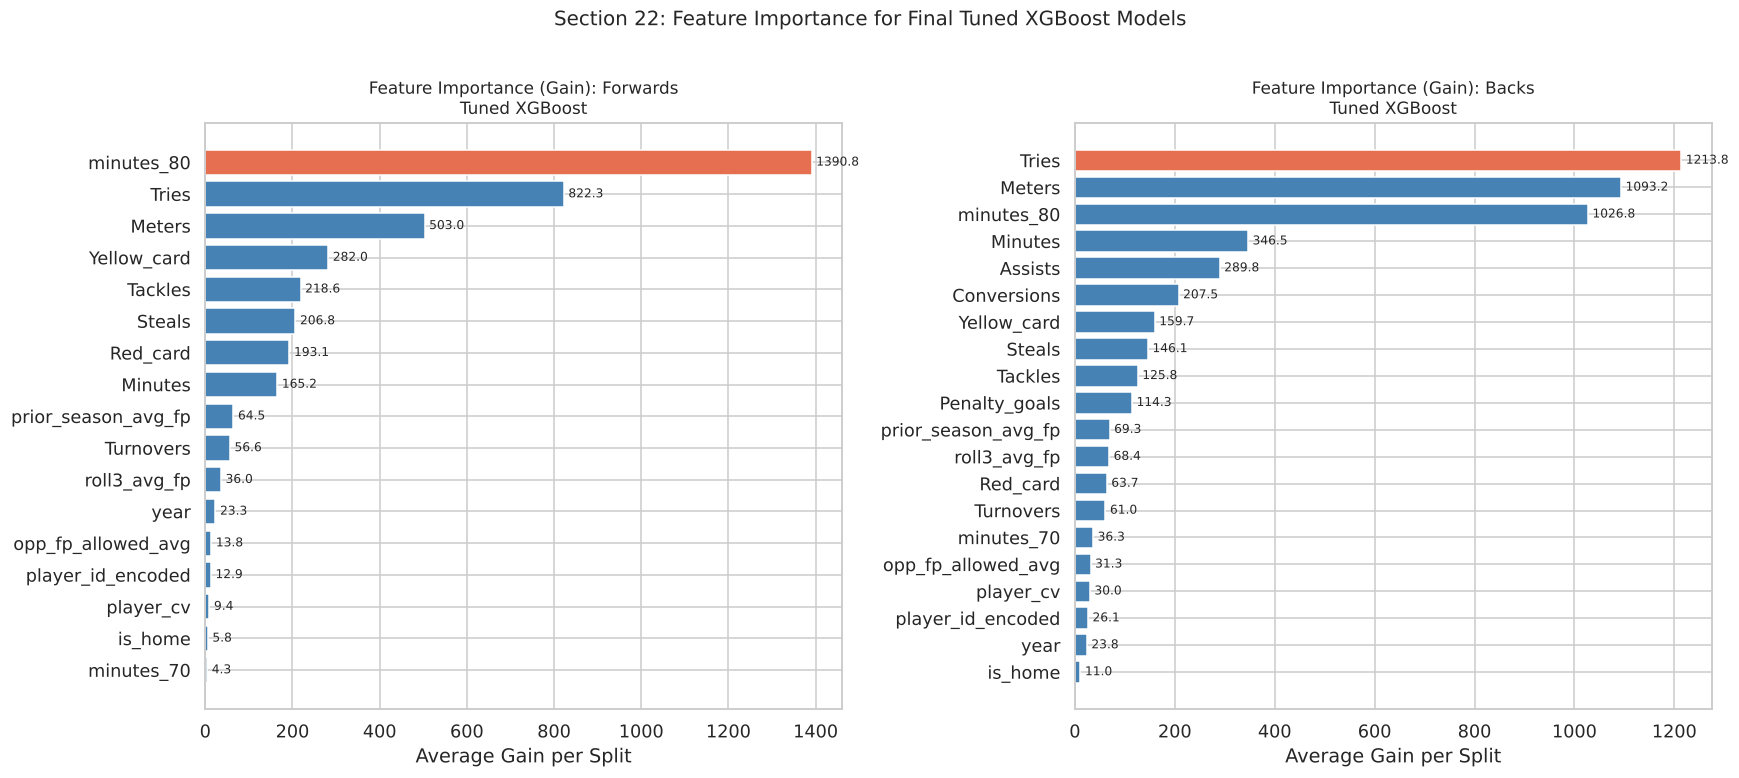

In [67]:
# 22.1  Gain-based feature importance: tuned models

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, model, features, group in zip(
    axes,
    [xgb_fwd_best, xgb_bck_best],
    [FWD_FEATURES, BCK_FEATURES],
    ['Forwards', 'Backs']
):
    imp = model.get_booster().get_score(importance_type='gain')
    # Features with zero splits don't appear in get_score; fill them as 0
    imp_df = pd.DataFrame({
        'Feature'  : features,
        'Gain'     : [imp.get(f, 0.0) for f in features]
    }).sort_values('Gain', ascending=True)

    colors = ['#e76f51' if imp_df['Gain'].max() == g else 'steelblue'
              for g in imp_df['Gain']]
    bars = ax.barh(imp_df['Feature'], imp_df['Gain'], color=colors)
    ax.set_title(f'Feature Importance (Gain): {group}\nTuned XGBoost', fontsize=11)
    ax.set_xlabel('Average Gain per Split')
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=8)

plt.suptitle('Section 22: Feature Importance for Final Tuned XGBoost Models', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [68]:
# 22.2  Feature importance ranking table

print('Feature Importance Rankings: Tuned XGBoost (Gain)')
print()

for model, features, group in [
    (xgb_fwd_best, FWD_FEATURES, 'Forwards'),
    (xgb_bck_best, BCK_FEATURES, 'Backs')
]:
    imp = model.get_booster().get_score(importance_type='gain')
    imp_df = (
        pd.DataFrame({'Feature': features, 'Gain': [imp.get(f, 0.0) for f in features]})
        .sort_values('Gain', ascending=False)
        .reset_index(drop=True)
    )
    imp_df.index = imp_df.index + 1  # 1-based rank
    imp_df['Gain'] = imp_df['Gain'].round(2)
    print(f'--- {group} ---')
    print(imp_df.to_string())
    print()

Feature Importance Rankings: Tuned XGBoost (Gain)

--- Forwards ---
                Feature     Gain
1            minutes_80  1390.81
2                 Tries   822.29
3                Meters   503.05
4           Yellow_card   281.98
5               Tackles   218.60
6                Steals   206.78
7              Red_card   193.10
8               Minutes   165.22
9   prior_season_avg_fp    64.50
10            Turnovers    56.56
11         roll3_avg_fp    36.01
12                 year    23.32
13   opp_fp_allowed_avg    13.81
14    player_id_encoded    12.90
15            player_cv     9.40
16              is_home     5.83
17           minutes_70     4.34

--- Backs ---
                Feature     Gain
1                 Tries  1213.80
2                Meters  1093.16
3            minutes_80  1026.85
4               Minutes   346.51
5               Assists   289.81
6           Conversions   207.47
7           Yellow_card   159.75
8                Steals   146.10
9               Tackles   

## 23. Overfitting Audit

Train vs. validation RMSE gap analysis across all models.

A large train-val gap indicates overfitting: the model has memorized training
patterns that do not generalize. The primary risk is Random Forest (fully grown
trees) and XGBoost without adequate regularization.

Models with early stopping (XGBoost) and cross-validated regularization
(Ridge, ElasticNet) are expected to show tighter gaps.

In [69]:
# 23.1  Train vs. validation RMSE for every model
# Score each model on the same inputs it was trained on:
#   - LR: unscaled (Section 14)
#   - Ridge, ElasticNet: scaled (Sections 15 and 19)
#   - Tree models: unscaled

audit_rows = []
model_specs = [
    ('LR',             lr_fwd,       lr_bck,       'unscaled', True),
    ('Ridge',          ridge_fwd,    ridge_bck,    'scaled',   True),
    ('ElasticNet',     en_fwd,       en_bck,       'scaled',   True),
    ('Random Forest',  rf_fwd,       rf_bck,       'unscaled', False),
    ('XGB (baseline)', xgb_fwd,      xgb_bck,      'unscaled', False),
    ('XGB (tuned)',    xgb_fwd_best, xgb_bck_best, 'unscaled', False),
]
inputs = {
    'Forwards': dict(unscaled=(X_train_fwd, X_val_fwd), scaled=(X_train_fwd_sc, X_val_fwd_sc), y=(y_train_fwd, y_val_fwd)),
    'Backs':    dict(unscaled=(X_train_bck, X_val_bck), scaled=(X_train_bck_sc, X_val_bck_sc), y=(y_train_bck, y_val_bck)),
}
for name, fwd_model, bck_model, form, log_target in model_specs:
    for group, model in [('Forwards', fwd_model), ('Backs', bck_model)]:
        X_tr, X_vl = inputs[group][form]
        y_tr, y_vl = inputs[group]['y']
        tr_pred, vl_pred = model.predict(X_tr), model.predict(X_vl)
        if log_target:
            tr_pred, vl_pred = inv_transform(tr_pred), inv_transform(vl_pred)
        tr_rmse = mean_squared_error(y_tr, tr_pred) ** 0.5
        vl_rmse = mean_squared_error(y_vl, vl_pred) ** 0.5
        audit_rows.append({
            'Model': name, 'Group': group,
            'Train RMSE': round(tr_rmse, 3), 'Val RMSE': round(vl_rmse, 3),
            'Gap (V-T)': round(vl_rmse - tr_rmse, 3),
            'Overfit Flag': 'WARNING' if vl_rmse - tr_rmse > 0.5 else 'OK',
        })

audit_df = pd.DataFrame(audit_rows)
print('Overfitting Audit: Train vs. Validation RMSE')
print(audit_df.to_string(index=False))
print()
print('Gap (V-T): positive = validation worse than training (overfitting signal).')
print('Threshold: gap > 0.5 FP flagged as WARNING.')

Overfitting Audit: Train vs. Validation RMSE
         Model    Group  Train RMSE  Val RMSE  Gap (V-T) Overfit Flag
            LR Forwards       1.316     1.019     -0.297           OK
            LR    Backs       1.798     1.503     -0.295           OK
         Ridge Forwards       1.297     1.020     -0.277           OK
         Ridge    Backs       1.792     1.503     -0.289           OK
    ElasticNet Forwards       1.299     0.968     -0.331           OK
    ElasticNet    Backs       1.791     1.454     -0.337           OK
 Random Forest Forwards       1.381     1.406      0.024           OK
 Random Forest    Backs       1.876     2.202      0.326           OK
XGB (baseline) Forwards       1.013     0.774     -0.239           OK
XGB (baseline)    Backs       1.231     0.960     -0.271           OK
   XGB (tuned) Forwards       1.013     0.693     -0.320           OK
   XGB (tuned)    Backs       1.281     0.899     -0.382           OK

Gap (V-T): positive = validation worse than 

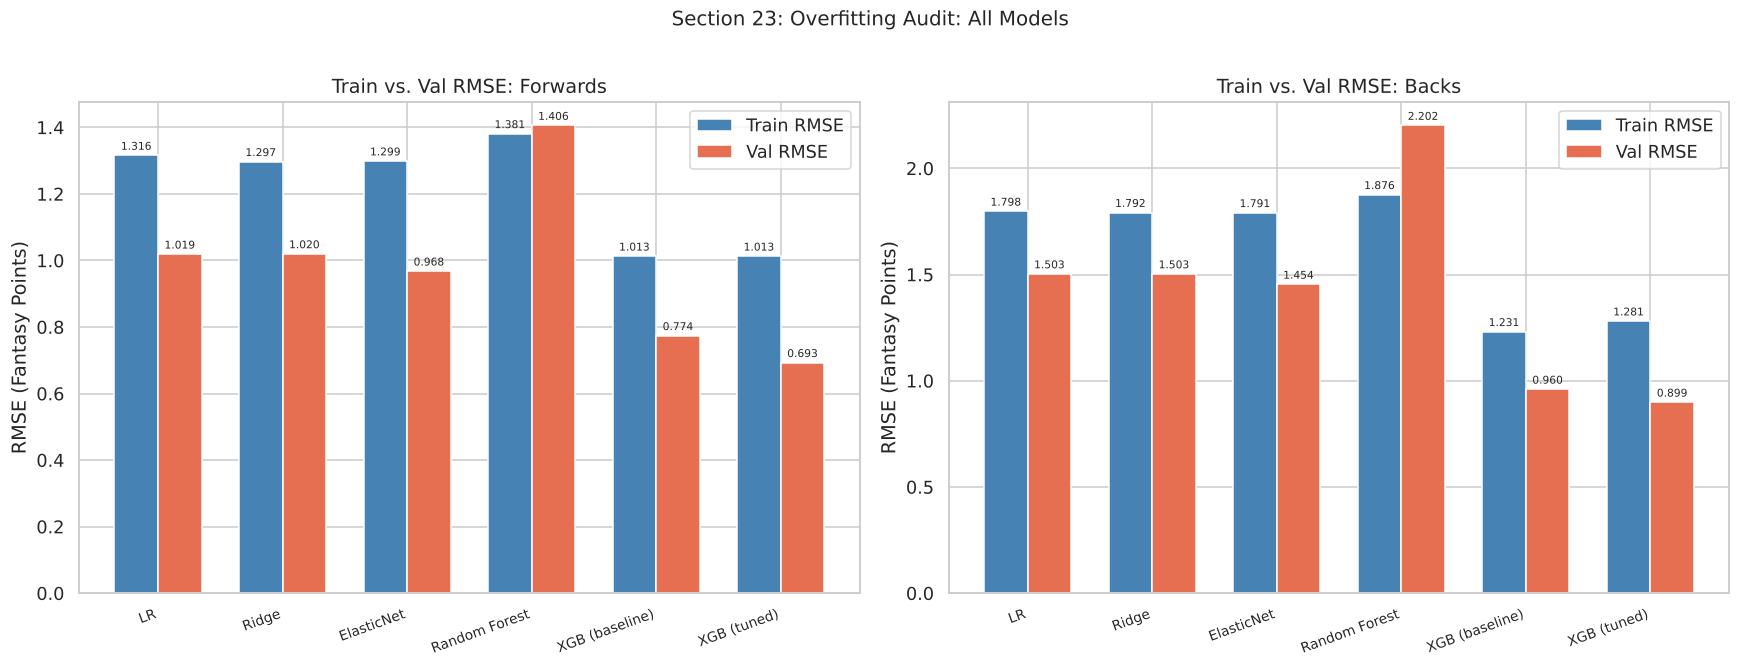


Interpretation: Bars of similar height = well-generalized model.
A tall orange bar (val) vs short blue bar (train) signals overfitting.


In [70]:
# 23.2  Overfitting audit bar chart

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, group in zip(axes, ['Forwards', 'Backs']):
    grp = audit_df[audit_df['Group'] == group]
    x   = range(len(grp))
    width = 0.35

    bars_tr = ax.bar([i - width/2 for i in x], grp['Train RMSE'],
                     width, label='Train RMSE', color='steelblue', edgecolor='white')
    bars_vl = ax.bar([i + width/2 for i in x], grp['Val RMSE'],
                     width, label='Val RMSE', color='#e76f51', edgecolor='white')

    ax.set_xticks(list(x))
    ax.set_xticklabels(grp['Model'], rotation=20, ha='right', fontsize=9)
    ax.set_ylabel('RMSE (Fantasy Points)')
    ax.set_title(f'Train vs. Val RMSE: {group}')
    ax.legend()
    ax.bar_label(bars_tr, fmt='%.3f', padding=2, fontsize=7)
    ax.bar_label(bars_vl, fmt='%.3f', padding=2, fontsize=7)

plt.suptitle('Section 23: Overfitting Audit: All Models', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print()
print('Interpretation: Bars of similar height = well-generalized model.')
print('A tall orange bar (val) vs short blue bar (train) signals overfitting.')

### 23.3 Why is validation error lower than training error?

Most models score *better* on 2025 Rounds 1-10 than on the seasons they were trained on. A negative gap is unusual, so it is worth checking rather than celebrating. RMSE depends on the split as well as the model: if 2025 scoring is less spread out (Section 8 shows league-wide scoring fell after 2023), or has fewer extreme games, where errors are largest, the same model produces smaller errors there. The check below compares the target across splits.

In [71]:
# 23.3  Compare target spread across splits

spread = pd.DataFrame({
    split: {'rows': len(d), 'mean FP': d[TARGET].mean(), 'std FP': d[TARGET].std(),
            'share of FP > 20': (d[TARGET] > 20).mean()}
    for split, d in [('Train 2023-24', train), ('Val 2025 R1-10', val), ('Test 2025 R11+', test)]
}).T
print(spread.round(3).to_string())
print()
ratio = spread.loc['Val 2025 R1-10', 'std FP'] / spread.loc['Train 2023-24', 'std FP']
print(f'Validation target std is {ratio:.0%} of the training std.')
neg = (audit_df['Gap (V-T)'] < 0).sum()
print(f'{neg} of {len(audit_df)} model/group combinations have a negative gap.')
big_tr = spread.loc['Train 2023-24', 'share of FP > 20']
big_va = spread.loc['Val 2025 R1-10', 'share of FP > 20']
if ratio < 0.95 or big_va < big_tr:
    print(f'The validation target is less spread out and has fewer 20+ point games '
          f'({big_va:.1%} vs {big_tr:.1%}). Both shrink RMSE without any change in model quality,')
    print('so the negative gaps are a property of the splits, not a sign the models generalize')
    print('better than they fit. R-squared, which adjusts for spread, is the fairer comparison.')
else:
    print('Target spread is similar across splits, so any negative gaps are not explained by')
    print('variance alone; early stopping on the validation set (Section 18) also flatters it.')

                  rows  mean FP  std FP  share of FP > 20
Train 2023-24   5665.0    7.482   5.447             0.029
Val 2025 R1-10  1440.0    6.849   5.027             0.017
Test 2025 R11+  1020.0    6.933   4.995             0.018

Validation target std is 92% of the training std.
10 of 12 model/group combinations have a negative gap.
The validation target is less spread out and has fewer 20+ point games (1.7% vs 2.9%). Both shrink RMSE without any change in model quality,
so the negative gaps are a property of the splits, not a sign the models generalize
better than they fit. R-squared, which adjusts for spread, is the fairer comparison.


## 24. Test Set Evaluation (in-game models)

**This section is run once.** The held-out test set (2025 Rounds 11-16) was not used for feature engineering, model selection, or tuning.

Models evaluated:
1. **XGBoost (tuned):** the best in-game model on validation
2. **ElasticNet:** the best linear model, as a reference

No parameters are changed based on these results.

In [72]:
# 24.1  Prepare test set slices

test_fwd = test[test['Pos'].isin(FORWARDS)]
test_bck = test[test['Pos'].isin(BACKS)]

X_test_fwd = test_fwd[FWD_FEATURES]
y_test_fwd = test_fwd[TARGET]

X_test_bck = test_bck[BCK_FEATURES]
y_test_bck = test_bck[TARGET]

# Scaled inputs for ElasticNet (scaler_fwd / scaler_bck fitted on train in Section 15)
X_test_fwd_sc = scaler_fwd.transform(X_test_fwd)
X_test_bck_sc = scaler_bck.transform(X_test_bck)

print('Test set sizes:')
print(f'  Forwards: {len(X_test_fwd):,} rows  (2025 Rds {test_fwd["Rnd"].min()}-{test_fwd["Rnd"].max()})')
print(f'  Backs   : {len(X_test_bck):,} rows  (2025 Rds {test_bck["Rnd"].min()}-{test_bck["Rnd"].max()})')

Test set sizes:
  Forwards: 544 rows  (2025 Rds 11-16)
  Backs   : 476 rows  (2025 Rds 11-16)


In [73]:
# 24.2  XGBoost Tuned: test set evaluation

xgb_fwd_test_pred = xgb_fwd_best.predict(X_test_fwd)
xgb_bck_test_pred = xgb_bck_best.predict(X_test_bck)

print('XGBoost Tuned: Test Set Results (2025 Rds 11-16)')
print('=' * 50)
print()
print('Forwards:')
results['XGB_fwd_test'] = full_metrics(y_test_fwd, xgb_fwd_test_pred)
print()
print('Backs:')
results['XGB_bck_test'] = full_metrics(y_test_bck, xgb_bck_test_pred)

XGBoost Tuned: Test Set Results (2025 Rds 11-16)

Forwards:
    RMSE : 0.827 FP
    MAE  : 0.462 FP
    R2   : 0.968

Backs:
    RMSE : 0.950 FP
    MAE  : 0.614 FP
    R2   : 0.967


In [74]:
# 24.3  ElasticNet: test set evaluation (reference baseline)

en_fwd_test_pred = inv_transform(en_fwd.predict(X_test_fwd_sc))
en_bck_test_pred = inv_transform(en_bck.predict(X_test_bck_sc))

print('ElasticNet: Test Set Results (2025 Rds 11-16)')
print()
print('Forwards:')
results['EN_fwd_test'] = full_metrics(y_test_fwd, en_fwd_test_pred)
print()
print('Backs:')
results['EN_bck_test'] = full_metrics(y_test_bck, en_bck_test_pred)

ElasticNet: Test Set Results (2025 Rds 11-16)

Forwards:
    RMSE : 0.906 FP
    MAE  : 0.645 FP
    R2   : 0.961

Backs:
    RMSE : 1.401 FP
    MAE  : 1.209 FP
    R2   : 0.928


In [75]:
# 24.4  Validation vs. test RMSE comparison
# Key check: does performance hold from val to test, or degrade?
# Large degradation from val to test would indicate the val set was over-fit against.

comparison_rows = []

for label, fwd_val_key, bck_val_key, fwd_test_key, bck_test_key in [
    ('XGB Tuned',  'XGB_fwd_tuned', 'XGB_bck_tuned', 'XGB_fwd_test', 'XGB_bck_test'),
    ('ElasticNet', 'EN_fwd',        'EN_bck',         'EN_fwd_test',  'EN_bck_test'),
]:
    for group, val_key, test_key in [
        ('Forwards', fwd_val_key, fwd_test_key),
        ('Backs',    bck_val_key, bck_test_key),
    ]:
        val_rmse  = results[val_key]['rmse']
        test_rmse = results[test_key]['rmse']
        delta     = test_rmse - val_rmse
        delta_pct = (delta / val_rmse) * 100
        comparison_rows.append({
            'Model'         : label,
            'Group'         : group,
            'Val RMSE'      : round(val_rmse, 3),
            'Test RMSE'     : round(test_rmse, 3),
            'Delta'         : round(delta, 3),
            'Delta %'       : f'{delta_pct:+.1f}%',
        })

comp_df = pd.DataFrame(comparison_rows)
print('Validation vs. Test RMSE: Generalization Check')
print(comp_df.to_string(index=False))
print()
print('Delta: positive = test is harder than val (expected).')
flagged = comp_df[comp_df['Delta %'].str.rstrip('%').astype(float) > 15]
if flagged.empty:
    print('No row rises more than 15% from validation to test.')
else:
    for _, r in flagged.iterrows():
        print(f"{r['Model']} {r['Group']}: test RMSE is {r['Delta %']} above validation "
              f"({r['Delta']:+.3f} FP). Tuning on the validation set flatters its score.")
    print('Relative rises look large because these RMSEs are under 1 FP; test R-squared')
    print('(Section 24.6) is the better check that the in-game model still holds.')

Validation vs. Test RMSE: Generalization Check
     Model    Group  Val RMSE  Test RMSE  Delta Delta %
 XGB Tuned Forwards     0.693      0.827  0.134  +19.4%
 XGB Tuned    Backs     0.899      0.950  0.051   +5.7%
ElasticNet Forwards     0.968      0.906 -0.062   -6.4%
ElasticNet    Backs     1.454      1.401 -0.054   -3.7%

Delta: positive = test is harder than val (expected).
XGB Tuned Forwards: test RMSE is +19.4% above validation (+0.134 FP). Tuning on the validation set flatters its score.
Relative rises look large because these RMSEs are under 1 FP; test R-squared
(Section 24.6) is the better check that the in-game model still holds.


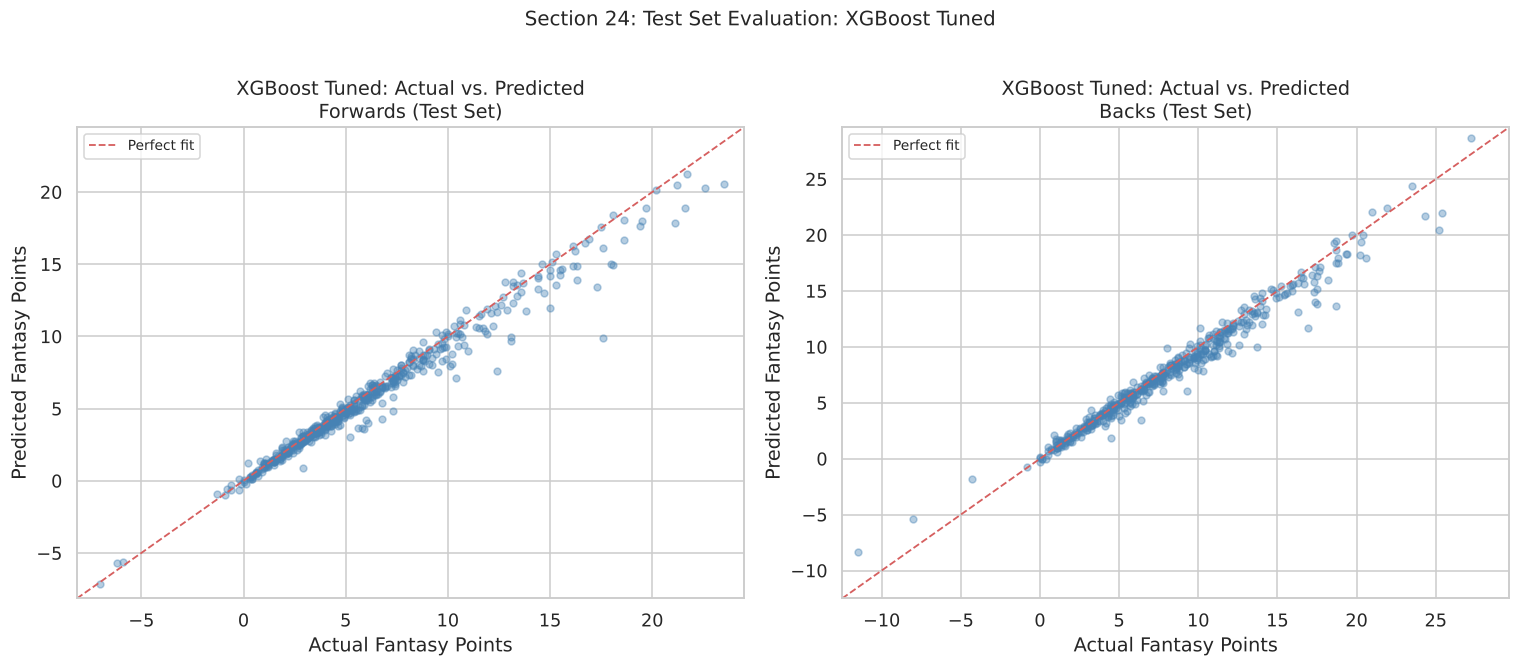

In [76]:
# 24.5  Actual vs. Predicted plots: test set (XGBoost Tuned)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, y_true, y_pred, group in zip(
    axes,
    [y_test_fwd, y_test_bck],
    [xgb_fwd_test_pred, xgb_bck_test_pred],
    ['Forwards', 'Backs']
):
    ax.scatter(y_true, y_pred, alpha=0.4, s=20, color='steelblue')
    lims = [min(y_true.min(), y_pred.min()) - 1,
            max(y_true.max(), y_pred.max()) + 1]
    ax.plot(lims, lims, 'r--', linewidth=1.2, label='Perfect fit')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('Actual Fantasy Points')
    ax.set_ylabel('Predicted Fantasy Points')
    ax.set_title(f'XGBoost Tuned: Actual vs. Predicted\n{group} (Test Set)')
    ax.legend(fontsize=9)

plt.suptitle('Section 24: Test Set Evaluation: XGBoost Tuned', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [77]:
# 24.6  Complete final summary: all models, val and test
# The definitive reference table for the project.

final_rows = []

model_map = [
    ('LR',           'LR_fwd',         'LR_bck',         None,           None),
    ('Ridge',        'Ridge_fwd',       'Ridge_bck',       None,           None),
    ('ElasticNet',   'EN_fwd',          'EN_bck',          'EN_fwd_test',  'EN_bck_test'),
    ('Rand Forest',  'RF_fwd',          'RF_bck',          None,           None),
    ('XGB Baseline', 'XGB_fwd',         'XGB_bck',         None,           None),
    ('XGB Tuned',    'XGB_fwd_tuned',   'XGB_bck_tuned',  'XGB_fwd_test', 'XGB_bck_test'),
]

for name, fk_val, bk_val, fk_test, bk_test in model_map:
    for group, vk, tk in [('Forwards', fk_val, fk_test), ('Backs', bk_val, bk_test)]:
        row = {
            'Model'     : name,
            'Group'     : group,
            'Val RMSE'  : round(results[vk]['rmse'], 3),
            'Val MAE'   : round(results[vk]['mae'],  3),
            'Val R2'    : round(results[vk]['r2'],   3),
            'Test RMSE' : round(results[tk]['rmse'], 3) if tk else '--',
            'Test MAE'  : round(results[tk]['mae'],  3) if tk else '--',
            'Test R2'   : round(results[tk]['r2'],   3) if tk else '--',
        }
        final_rows.append(row)

final_df = pd.DataFrame(final_rows)
print('FINAL MODEL SUMMARY: All Models, Validation and Test Set')
print(final_df.to_string(index=False))
print()
print('Best in-game model: XGBoost (tuned). Reminder: this model uses match statistics,')
print('so it is an upper bound on accuracy, not a pre-game forecast.')
print('Test set evaluated once. No further parameter changes will be made.')

FINAL MODEL SUMMARY: All Models, Validation and Test Set
       Model    Group  Val RMSE  Val MAE  Val R2 Test RMSE Test MAE Test R2
          LR Forwards     1.019    0.728   0.944        --       --      --
          LR    Backs     1.503    1.284   0.924        --       --      --
       Ridge Forwards     1.020    0.728   0.944        --       --      --
       Ridge    Backs     1.503    1.285   0.924        --       --      --
  ElasticNet Forwards     0.968    0.662   0.949     0.906    0.645   0.961
  ElasticNet    Backs     1.454    1.237   0.929     1.401    1.209   0.928
 Rand Forest Forwards     1.406    0.860   0.893        --       --      --
 Rand Forest    Backs     2.202    1.432   0.837        --       --      --
XGB Baseline Forwards     0.774    0.473   0.968        --       --      --
XGB Baseline    Backs     0.960    0.685   0.969        --       --      --
   XGB Tuned Forwards     0.693    0.427   0.974     0.827    0.462   0.968
   XGB Tuned    Backs     0.899

## 25. Pre-Game Forecast: The Real Prediction Problem

Everything in Sections 14-24 uses match statistics (tries, meters, tackles) that are only known after the final whistle. This section answers the question a fantasy player or analyst actually faces: **before kickoff, how many points will this starter score?**

**Pre-game features (9):**
- `prior_season_avg_fp`: the player's average FP last season (position median for players with no prior season)
- `roll3_avg_fp`: average FP over the player's previous 3 matches this season
- `player_cv`: the player's volatility over earlier matches this season
- `is_home`, `year`
- `pos_encoded`: starting position
- `team_encoded`: the player's team
- `player_id_encoded`: player identity (for players with 5+ training appearances)
- `opp_fp_allowed_avg`: what this opponent allowed to the position group last season

**Excluded:** every in-game statistic (Minutes, Tries, Meters, Tackles, Assists, Conversions, Penalty_goals, Steals, Turnovers, minutes_70, minutes_80, cards).

The same forward/back split, temporal split, and XGBoost grid from Section 21 are used. The model is then compared against a ridge regression and against simple baselines a fantasy player could compute by hand.

In [78]:
# 25.1  Define pre-game feature set

pos_le  = LabelEncoder()
team_le = LabelEncoder()
model_df['pos_encoded']  = pos_le.fit_transform(model_df['Pos'])
model_df['team_encoded'] = team_le.fit_transform(model_df['Team'])

PREGAME_FEATURES = [
    'prior_season_avg_fp',
    'roll3_avg_fp',
    'player_cv',
    'is_home',
    'year',
    'pos_encoded',
    'team_encoded',
    'player_id_encoded',
    'opp_fp_allowed_avg',
]

print(f'Pre-game feature set ({len(PREGAME_FEATURES)}):')
for f in PREGAME_FEATURES:
    print(f'  {f}')
print()
print('Pos encoding map:', dict(zip(pos_le.classes_, pos_le.transform(pos_le.classes_))))
print('Team encoding map:', dict(zip(team_le.classes_, team_le.transform(team_le.classes_))))

Pre-game feature set (9):
  prior_season_avg_fp
  roll3_avg_fp
  player_cv
  is_home
  year
  pos_encoded
  team_encoded
  player_id_encoded
  opp_fp_allowed_avg

Pos encoding map: {'B3': np.int64(0), 'BR': np.int64(1), 'C': np.int64(2), 'FH': np.int64(3), 'FR': np.int64(4), 'SH': np.int64(5), 'SR': np.int64(6)}
Team encoding map: {'ARC': np.int64(0), 'CHI': np.int64(1), 'DAL': np.int64(2), 'HOU': np.int64(3), 'LA': np.int64(4), 'MIA': np.int64(5), 'NEFJ': np.int64(6), 'NOLA': np.int64(7), 'OGDC': np.int64(8), 'RATL': np.int64(9), 'RUNY': np.int64(10), 'SDL': np.int64(11), 'SEA': np.int64(12), 'TOR': np.int64(13), 'UTAH': np.int64(14)}


In [79]:
# 25.2  Slice train / val / test sets by position group (pre-game features only)
# Reuses train / val / test splits defined in Section 12.4.

# Re-apply encodings to split sets (model_df already has the new columns after 25.1)
train_pg = train.copy()
val_pg   = val.copy()
test_pg  = test.copy()

train_pg['pos_encoded']  = pos_le.transform(train_pg['Pos'])
train_pg['team_encoded'] = team_le.transform(train_pg['Team'])
val_pg['pos_encoded']    = pos_le.transform(val_pg['Pos'])
val_pg['team_encoded']   = team_le.transform(val_pg['Team'])
test_pg['pos_encoded']   = pos_le.transform(test_pg['Pos'])
test_pg['team_encoded']  = team_le.transform(test_pg['Team'])

# Forwards slice
train_fwd_pg = train_pg[train_pg['Pos'].isin(FORWARDS)]
val_fwd_pg   = val_pg[val_pg['Pos'].isin(FORWARDS)]
test_fwd_pg  = test_pg[test_pg['Pos'].isin(FORWARDS)]

X_train_fwd_pg = train_fwd_pg[PREGAME_FEATURES]
y_train_fwd_pg = train_fwd_pg[TARGET]
X_val_fwd_pg   = val_fwd_pg[PREGAME_FEATURES]
y_val_fwd_pg   = val_fwd_pg[TARGET]
X_test_fwd_pg  = test_fwd_pg[PREGAME_FEATURES]
y_test_fwd_pg  = test_fwd_pg[TARGET]

# Backs slice
train_bck_pg = train_pg[train_pg['Pos'].isin(BACKS)]
val_bck_pg   = val_pg[val_pg['Pos'].isin(BACKS)]
test_bck_pg  = test_pg[test_pg['Pos'].isin(BACKS)]

X_train_bck_pg = train_bck_pg[PREGAME_FEATURES]
y_train_bck_pg = train_bck_pg[TARGET]
X_val_bck_pg   = val_bck_pg[PREGAME_FEATURES]
y_val_bck_pg   = val_bck_pg[TARGET]
X_test_bck_pg  = test_bck_pg[PREGAME_FEATURES]
y_test_bck_pg  = test_bck_pg[TARGET]

print('Pre-game train / val / test sizes:')
print(f'  Forwards train: {len(X_train_fwd_pg):,} | val: {len(X_val_fwd_pg):,} | test: {len(X_test_fwd_pg):,}')
print(f'  Backs train: {len(X_train_bck_pg):,} | val: {len(X_val_bck_pg):,} | test: {len(X_test_bck_pg):,}')

Pre-game train / val / test sizes:
  Forwards train: 3,022 | val: 768 | test: 544
  Backs train: 2,643 | val: 672 | test: 476


In [80]:
# 25.3  Grid search: pre-game Forwards
# Reuses PARAM_GRID and all_combos defined in Section 21.1.
# Early stopping (20 rounds) on the val set; n_estimators ceiling = 1000.

xgb_pg_fwd_best, pg_fwd_best_params, pg_fwd_best_rmse, pg_fwd_best_iter, pg_fwd_grid_results = run_grid_search(
    X_train_fwd_pg, y_train_fwd_pg,
    X_val_fwd_pg,   y_val_fwd_pg,
    all_combos, 'PG-Forwards'
)

print()
print('Pre-Game Forwards Grid Search Results')
print(f'Best val RMSE : {pg_fwd_best_rmse:.4f} FP')
print(f'Best iteration: {pg_fwd_best_iter}')
print('Best params:')
for k, v in pg_fwd_best_params.items():
    print(f'  {k}: {v}')

  [PG-Forwards] 50/432 fits completed  |  best RMSE so far: 3.8430


  [PG-Forwards] 100/432 fits completed  |  best RMSE so far: 3.8388


  [PG-Forwards] 150/432 fits completed  |  best RMSE so far: 3.8388


  [PG-Forwards] 200/432 fits completed  |  best RMSE so far: 3.8388


  [PG-Forwards] 250/432 fits completed  |  best RMSE so far: 3.8326


  [PG-Forwards] 300/432 fits completed  |  best RMSE so far: 3.8326


  [PG-Forwards] 350/432 fits completed  |  best RMSE so far: 3.8326


  [PG-Forwards] 400/432 fits completed  |  best RMSE so far: 3.8326



Pre-Game Forwards Grid Search Results
Best val RMSE : 3.8326 FP
Best iteration: 28
Best params:
  learning_rate: 0.1
  max_depth: 4
  subsample: 0.6
  colsample_bytree: 0.8
  min_child_weight: 1


In [81]:
# 25.4  Grid search: pre-game Backs

xgb_pg_bck_best, pg_bck_best_params, pg_bck_best_rmse, pg_bck_best_iter, pg_bck_grid_results = run_grid_search(
    X_train_bck_pg, y_train_bck_pg,
    X_val_bck_pg,   y_val_bck_pg,
    all_combos, 'PG-Backs'
)

print()
print('Pre-Game Backs Grid Search Results')
print(f'Best val RMSE : {pg_bck_best_rmse:.4f} FP')
print(f'Best iteration: {pg_bck_best_iter}')
print('Best params:')
for k, v in pg_bck_best_params.items():
    print(f'  {k}: {v}')

  [PG-Backs] 50/432 fits completed  |  best RMSE so far: 5.3135


  [PG-Backs] 100/432 fits completed  |  best RMSE so far: 5.3105


  [PG-Backs] 150/432 fits completed  |  best RMSE so far: 5.3105


  [PG-Backs] 200/432 fits completed  |  best RMSE so far: 5.3105


  [PG-Backs] 250/432 fits completed  |  best RMSE so far: 5.3105


  [PG-Backs] 300/432 fits completed  |  best RMSE so far: 5.3057


  [PG-Backs] 350/432 fits completed  |  best RMSE so far: 5.2964


  [PG-Backs] 400/432 fits completed  |  best RMSE so far: 5.2964



Pre-Game Backs Grid Search Results
Best val RMSE : 5.2964 FP
Best iteration: 9
Best params:
  learning_rate: 0.1
  max_depth: 8
  subsample: 0.8
  colsample_bytree: 0.6
  min_child_weight: 10


In [82]:
# 25.5  Pre-game model: validation set evaluation

xgb_pg_fwd_val_pred = xgb_pg_fwd_best.predict(X_val_fwd_pg)
xgb_pg_bck_val_pred = xgb_pg_bck_best.predict(X_val_bck_pg)

print('Pre-Game XGBoost: Validation Set Results (2025 Rds 1-10)')
print()
print('Forwards:')
results['XGB_pg_fwd_val'] = full_metrics(y_val_fwd_pg, xgb_pg_fwd_val_pred)
print()
print('Backs:')
results['XGB_pg_bck_val'] = full_metrics(y_val_bck_pg, xgb_pg_bck_val_pred)

Pre-Game XGBoost: Validation Set Results (2025 Rds 1-10)

Forwards:
    RMSE : 3.833 FP
    MAE  : 2.863 FP
    R2   : 0.206

Backs:
    RMSE : 5.296 FP
    MAE  : 4.023 FP
    R2   : 0.058


In [83]:
# 25.6  Pre-game model: test set evaluation

xgb_pg_fwd_test_pred = xgb_pg_fwd_best.predict(X_test_fwd_pg)
xgb_pg_bck_test_pred = xgb_pg_bck_best.predict(X_test_bck_pg)

print('Pre-Game XGBoost: Test Set Results (2025 Rds 11-16)')
print()
print('Forwards:')
results['XGB_pg_fwd_test'] = full_metrics(y_test_fwd_pg, xgb_pg_fwd_test_pred)
print()
print('Backs:')
results['XGB_pg_bck_test'] = full_metrics(y_test_bck_pg, xgb_pg_bck_test_pred)

Pre-Game XGBoost: Test Set Results (2025 Rds 11-16)

Forwards:
    RMSE : 4.157 FP
    MAE  : 3.037 FP
    R2   : 0.180

Backs:
    RMSE : 5.083 FP
    MAE  : 3.985 FP
    R2   : 0.047


### 25.6b Is the pre-game model better than a simple rule?

A model is only worth using if it beats what someone could do in their head. Three naive forecasts, scored on the same test set:
- **Season average:** the player's average over earlier matches this season (last season's average before their first match).
- **Recent form:** the player's rolling 3-game average (`roll3_avg_fp`).
- **Position average:** the training-season average FP for the player's position.

A ridge regression on the same 9 pre-game features is included to check whether the tuned XGBoost model earns its complexity.

Pre-game forecasts on the test set (2025 Rds 11-16)
   Group                          Forecast  RMSE   MAE     R2
Forwards                  Pre-game XGBoost 4.157 3.037  0.180
Forwards                    Pre-game ridge 4.201 2.971  0.162
Forwards             Naive: season average 4.254 3.082  0.141
Forwards Naive: recent form (roll3_avg_fp) 4.527 3.250  0.027
Forwards           Naive: position average 4.238 3.208  0.147
   Backs                  Pre-game XGBoost 5.083 3.985  0.047
   Backs                    Pre-game ridge 5.116 3.880  0.034
   Backs             Naive: season average 5.165 3.989  0.016
   Backs Naive: recent form (roll3_avg_fp) 5.500 4.187 -0.116
   Backs           Naive: position average 5.217 4.185 -0.004

Forwards: best model = Pre-game ridge (MAE 2.97); best naive = Naive: season average (MAE 3.08); MAE 4% lower than naive.
  XGBoost MAE 3.04 vs ridge 2.97

Backs: best model = Pre-game ridge (MAE 3.88); best naive = Naive: season average (MAE 3.99); MAE 3% lower th

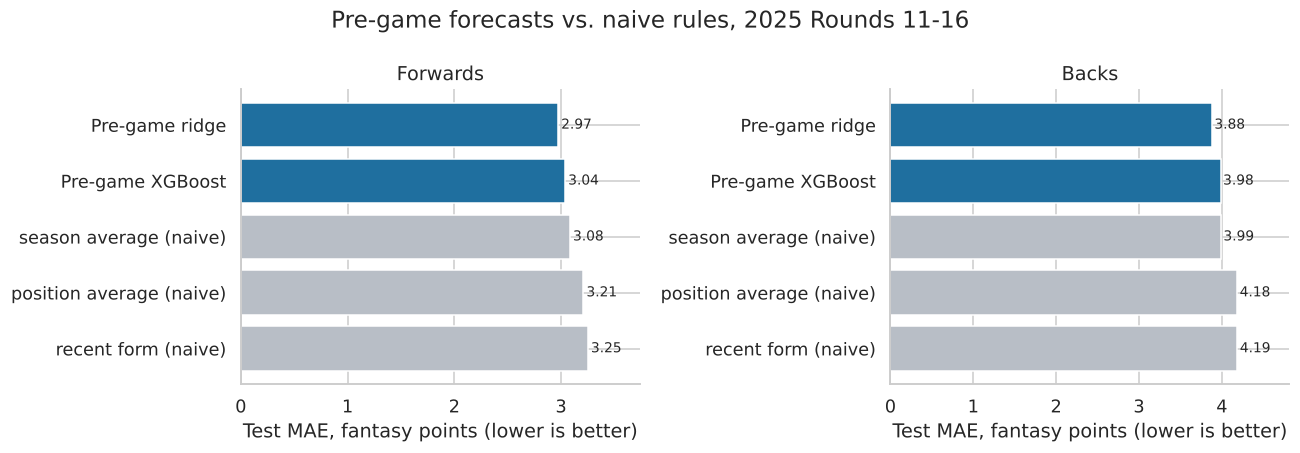

In [84]:
# 25.6b  Pre-game model vs. naive baselines (test set)

from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler

pos_train_mean = train.groupby('Pos')[TARGET].mean()
MODELS = ['Pre-game XGBoost', 'Pre-game ridge']
rows = []
for group, X_tr, y_tr, X_te, y_te, pred, te in [
    ('Forwards', X_train_fwd_pg, y_train_fwd_pg, X_test_fwd_pg, y_test_fwd_pg, xgb_pg_fwd_test_pred, test_fwd_pg),
    ('Backs',    X_train_bck_pg, y_train_bck_pg, X_test_bck_pg, y_test_bck_pg, xgb_pg_bck_test_pred, test_bck_pg),
]:
    # Ridge: scaler and alpha fit on training seasons only
    scaler = StandardScaler().fit(X_tr)
    ridge = RidgeCV(alphas=np.logspace(-2, 3, 30)).fit(scaler.transform(X_tr), y_tr)
    for label, p in [
        ('Pre-game XGBoost', pred),
        ('Pre-game ridge', ridge.predict(scaler.transform(X_te))),
        ('Naive: season average', te['season_avg_fp'].to_numpy()),
        ('Naive: recent form (roll3_avg_fp)', te['roll3_avg_fp'].to_numpy()),
        ('Naive: position average', te['Pos'].map(pos_train_mean).to_numpy()),
    ]:
        rows.append({'Group': group, 'Forecast': label,
                     'RMSE': mean_squared_error(y_te, p) ** 0.5,
                     'MAE': mean_absolute_error(y_te, p),
                     'R2': r2_score(y_te, p)})
baseline_df = pd.DataFrame(rows).round(3)
print('Pre-game forecasts on the test set (2025 Rds 11-16)')
print(baseline_df.to_string(index=False))
pg_vs_naive = {}
for group in ['Forwards', 'Backs']:
    g = baseline_df[baseline_df['Group'] == group].set_index('Forecast')['MAE']
    naive = g.drop(MODELS)
    best_model, best_naive = g[MODELS].idxmin(), naive.idxmin()
    gain = (naive.min() - g[best_model]) / naive.min()
    pg_vs_naive[group] = (best_model, g[best_model], best_naive, naive.min(), gain)
    print(f'\n{group}: best model = {best_model} (MAE {g[best_model]:.2f}); '
          f'best naive = {best_naive} (MAE {naive.min():.2f}); MAE {gain:.0%} lower than naive.')
    print(f'  XGBoost MAE {g["Pre-game XGBoost"]:.2f} vs ridge {g["Pre-game ridge"]:.2f}')

# Chart: models (blue) vs naive rules (gray), test MAE
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, group in zip(axes, ['Forwards', 'Backs']):
    g = baseline_df[baseline_df['Group'] == group].sort_values('MAE', ascending=False)
    labels = g['Forecast'].str.replace('Naive: ', '').str.replace(' (roll3_avg_fp)', '', regex=False)
    labels = [l if f in MODELS else f'{l} (naive)' for l, f in zip(labels, g['Forecast'])]
    colors = ['#1f6f9f' if f in MODELS else '#b8bec6' for f in g['Forecast']]
    ax.barh(labels, g['MAE'], color=colors)
    for y, v in enumerate(g['MAE']):
        ax.text(v + 0.03, y, f'{v:.2f}', va='center', fontsize=9)
    ax.set_xlim(0, g['MAE'].max() * 1.15)
    ax.set_title(group)
    ax.set_xlabel('Test MAE, fantasy points (lower is better)')
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Pre-game forecasts vs. naive rules, 2025 Rounds 11-16')
plt.tight_layout()
plt.show()

In [85]:
# 25.7  Architectural comparison: pre-game vs. full model
# Directly compares pre-game XGBoost (Section 25) against tuned XGBoost (Section 21)
# on the same val and test sets. RMSE delta quantifies the predictive value of
# in-game statistics.

comparison_pg = []

for group, pg_val_key, pg_test_key, full_val_key, full_test_key in [
    ('Forwards', 'XGB_pg_fwd_val', 'XGB_pg_fwd_test', 'XGB_fwd_tuned', 'XGB_fwd_test'),
    ('Backs',    'XGB_pg_bck_val', 'XGB_pg_bck_test', 'XGB_bck_tuned', 'XGB_bck_test'),
]:
    for split, pg_key, full_key in [
        ('Validation', pg_val_key,  full_val_key),
        ('Test',       pg_test_key, full_test_key),
    ]:
        pg_rmse   = results[pg_key]['rmse']
        full_rmse = results[full_key]['rmse']
        delta     = pg_rmse - full_rmse
        delta_pct = (delta / full_rmse) * 100
        comparison_pg.append({
            'Group'          : group,
            'Split'          : split,
            'Pre-Game RMSE'  : round(pg_rmse, 3),
            'Full RMSE'      : round(full_rmse, 3),
            'Delta (PG-Full)': round(delta, 3),
            'Delta %'        : f'{delta_pct:+.1f}%',
        })

comp_pg_df = pd.DataFrame(comparison_pg)
print('Pre-Game vs. Full Model: RMSE Comparison')
print()
print(comp_pg_df.to_string(index=False))
print()
print('Delta (PG-Full): positive = pre-game model is less accurate than full model.')
print('Magnitude indicates the predictive value added by in-game statistics.')

Pre-Game vs. Full Model: RMSE Comparison

   Group      Split  Pre-Game RMSE  Full RMSE  Delta (PG-Full) Delta %
Forwards Validation          3.833      0.693            3.140 +453.4%
Forwards       Test          4.157      0.827            3.330 +402.8%
   Backs Validation          5.296      0.899            4.398 +489.3%
   Backs       Test          5.083      0.950            4.133 +435.3%

Delta (PG-Full): positive = pre-game model is less accurate than full model.
Magnitude indicates the predictive value added by in-game statistics.


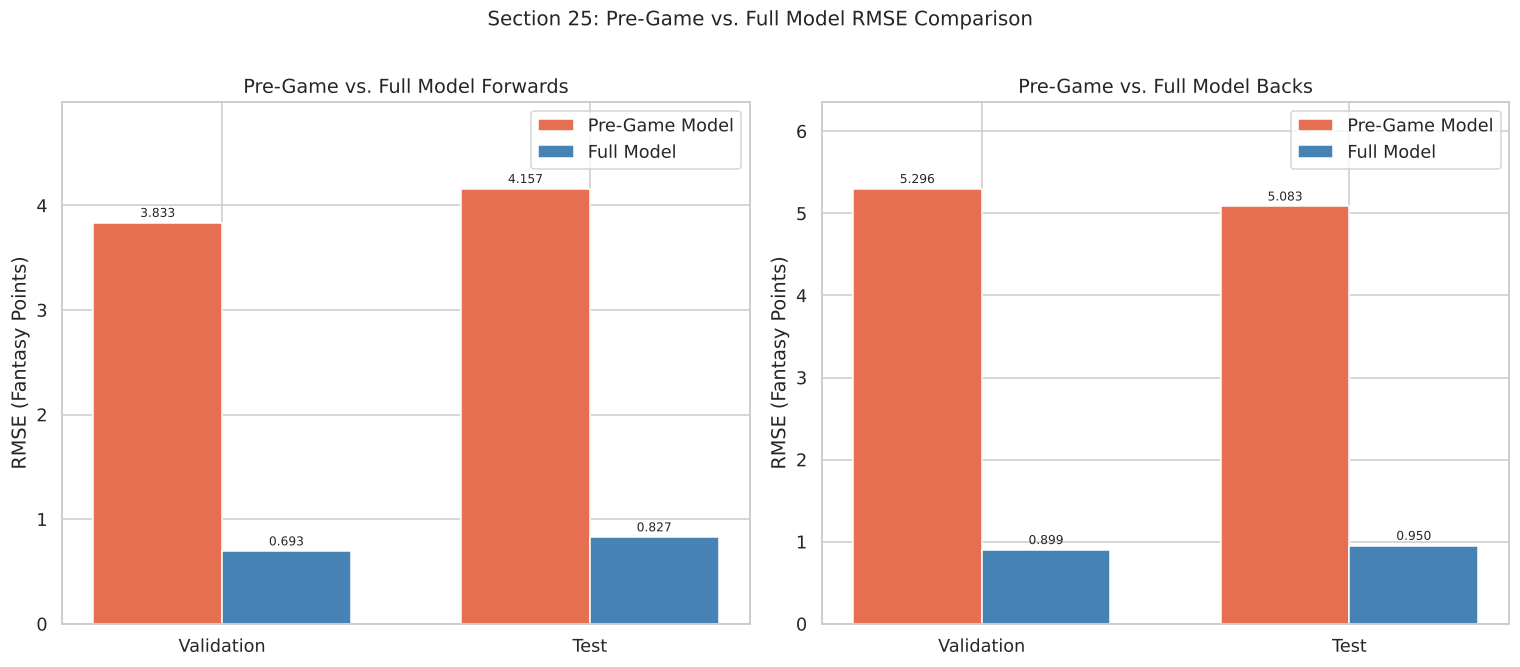


Interpretation: The gap between orange (pre-game) and blue (full) bars
represents the predictive lift provided by in-game statistics.


In [86]:
# 25.8  Visualization: pre-game vs. full model RMSE by group and split

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, group in zip(axes, ['Forwards', 'Backs']):
    grp     = comp_pg_df[comp_pg_df['Group'] == group]
    splits  = grp['Split'].tolist()
    pg_vals   = grp['Pre-Game RMSE'].tolist()
    full_vals = grp['Full RMSE'].tolist()

    x     = np.arange(len(splits))
    width = 0.35

    bars_pg   = ax.bar(x - width/2, pg_vals,   width, label='Pre-Game Model', color='#e76f51', edgecolor='white')
    bars_full = ax.bar(x + width/2, full_vals, width, label='Full Model',     color='steelblue', edgecolor='white')

    ax.set_xticks(x)
    ax.set_xticklabels(splits)
    ax.set_ylabel('RMSE (Fantasy Points)')
    ax.set_title(f'Pre-Game vs. Full Model {group}')
    ax.legend()
    ax.bar_label(bars_pg,   fmt='%.3f', padding=2, fontsize=8)
    ax.bar_label(bars_full, fmt='%.3f', padding=2, fontsize=8)
    ax.set_ylim(0, max(pg_vals + full_vals) * 1.2)

plt.suptitle('Section 25: Pre-Game vs. Full Model RMSE Comparison', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print()
print('Interpretation: The gap between orange (pre-game) and blue (full) bars')
print('represents the predictive lift provided by in-game statistics.')

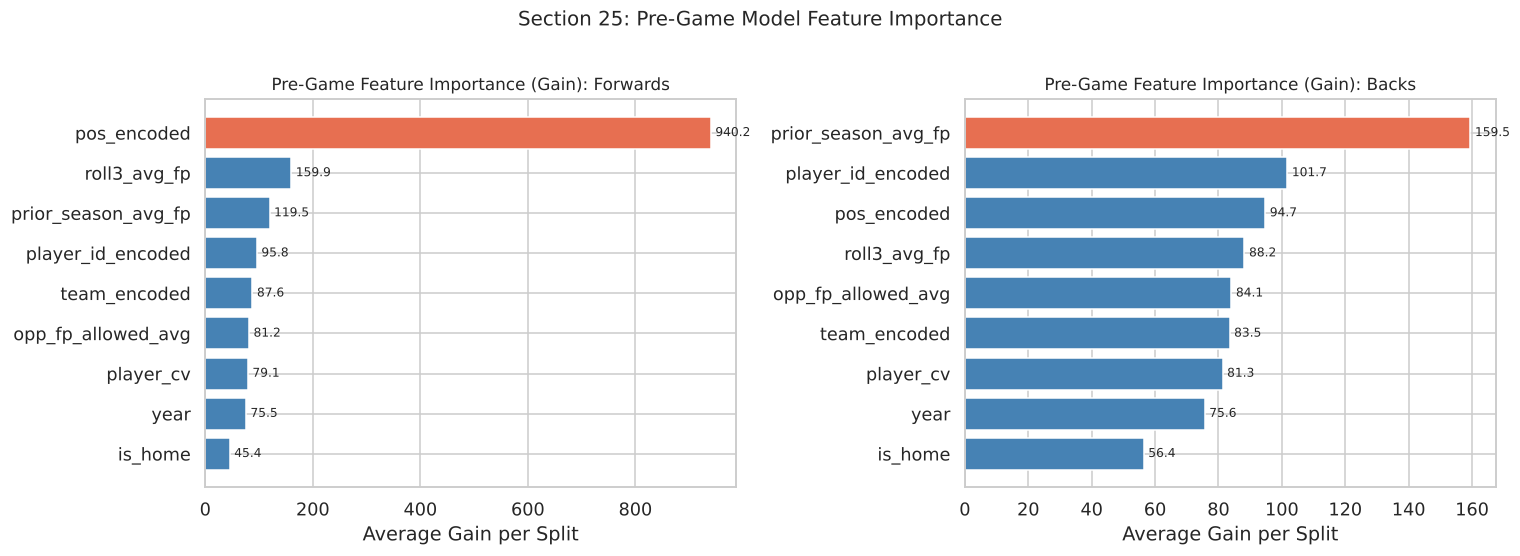


Read with the baseline table above: features near the top carry most of the
pre-game signal, and most of that signal is player history.


In [87]:
# 25.9  Feature importance: pre-game models
# Shows which pre-game features carry the most signal.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, group in zip(
    axes,
    [xgb_pg_fwd_best, xgb_pg_bck_best],
    ['Forwards', 'Backs']
):
    imp = model.get_booster().get_score(importance_type='gain')
    imp_df = pd.DataFrame({
        'Feature': PREGAME_FEATURES,
        'Gain'   : [imp.get(f, 0.0) for f in PREGAME_FEATURES]
    }).sort_values('Gain', ascending=True)

    colors = ['#e76f51' if imp_df['Gain'].max() == g else 'steelblue'
              for g in imp_df['Gain']]
    bars = ax.barh(imp_df['Feature'], imp_df['Gain'], color=colors)
    ax.set_title(f'Pre-Game Feature Importance (Gain): {group}', fontsize=11)
    ax.set_xlabel('Average Gain per Split')
    ax.bar_label(bars, fmt='%.1f', padding=3, fontsize=8)

plt.suptitle('Section 25: Pre-Game Model Feature Importance', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print()
print('Read with the baseline table above: features near the top carry most of the')
print('pre-game signal, and most of that signal is player history.')

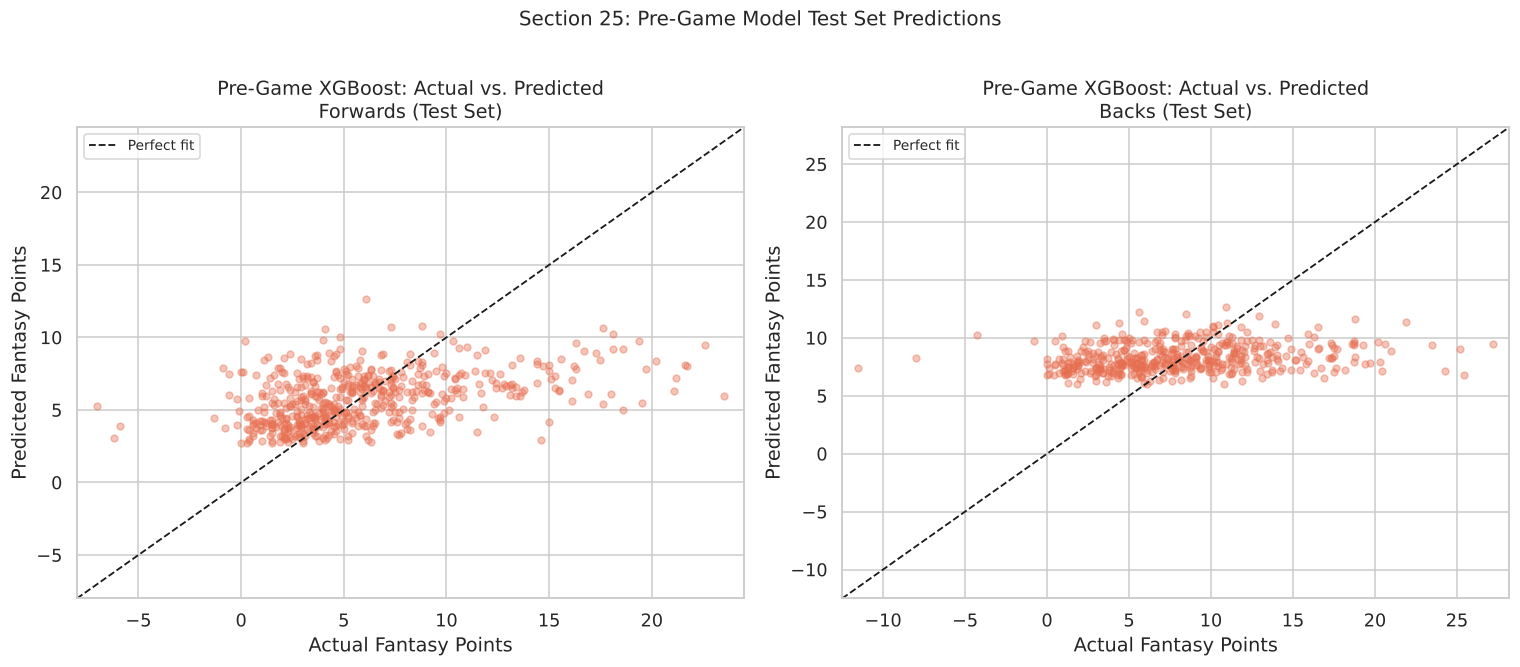

In [88]:
# 25.10  Actual vs. predicted: pre-game model (test set)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, y_true, y_pred, group in zip(
    axes,
    [y_test_fwd_pg, y_test_bck_pg],
    [xgb_pg_fwd_test_pred, xgb_pg_bck_test_pred],
    ['Forwards', 'Backs']
):
    ax.scatter(y_true, y_pred, alpha=0.4, s=20, color='#e76f51')
    lims = [min(y_true.min(), y_pred.min()) - 1,
            max(y_true.max(), y_pred.max()) + 1]
    ax.plot(lims, lims, 'k--', linewidth=1.2, label='Perfect fit')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('Actual Fantasy Points')
    ax.set_ylabel('Predicted Fantasy Points')
    ax.set_title(f'Pre-Game XGBoost: Actual vs. Predicted\n{group} (Test Set)')
    ax.legend(fontsize=9)

plt.suptitle('Section 25: Pre-Game Model Test Set Predictions', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

In [89]:
# 25.11  Section 25 summary

pg = {g: results[f'XGB_pg_{k}_test'] for g, k in [('Forwards', 'fwd'), ('Backs', 'bck')]}
full = {g: results[f'XGB_{k}_test'] for g, k in [('Forwards', 'fwd'), ('Backs', 'bck')]}
print('PRE-GAME FORECAST: TEST SET (2025 Rds 11-16)')
for g in ['Forwards', 'Backs']:
    print(f'  {g}: MAE {pg[g]["mae"]:.2f} FP, RMSE {pg[g]["rmse"]:.2f}, R2 {pg[g]["r2"]:.2f}  '
          f'(in-game upper bound: MAE {full[g]["mae"]:.2f}, R2 {full[g]["r2"]:.2f})')
print()
print('Interpretation:')
print('  - Before kickoff, a starter\'s fantasy score can be forecast only roughly. Most of')
print('    the variance is decided by what happens in the match.')
print('  - The in-game model\'s near-perfect fit confirms the scoring formula is learnable from')
print('    the box score; it is not evidence of forecasting skill.')
for g, (bm, bm_mae, bn, bn_mae, gain) in pg_vs_naive.items():
    print(f'  - {g}: the best pre-game model ({bm}) is {gain:.0%} better than the best naive')
    print(f'    rule ({bn}) on MAE, {bm_mae:.2f} vs {bn_mae:.2f} FP.')
print('  - The pre-game signal is weak and mostly linear: a ridge regression on the same')
print('    features does about as well as tuned XGBoost (25.6b).')

PRE-GAME FORECAST: TEST SET (2025 Rds 11-16)
  Forwards: MAE 3.04 FP, RMSE 4.16, R2 0.18  (in-game upper bound: MAE 0.46, R2 0.97)
  Backs: MAE 3.99 FP, RMSE 5.08, R2 0.05  (in-game upper bound: MAE 0.61, R2 0.97)

Interpretation:
  - Before kickoff, a starter's fantasy score can be forecast only roughly. Most of
    the variance is decided by what happens in the match.
  - The in-game model's near-perfect fit confirms the scoring formula is learnable from
    the box score; it is not evidence of forecasting skill.
  - Forwards: the best pre-game model (Pre-game ridge) is 4% better than the best naive
    rule (Naive: season average) on MAE, 2.97 vs 3.08 FP.
  - Backs: the best pre-game model (Pre-game ridge) is 3% better than the best naive
    rule (Naive: season average) on MAE, 3.88 vs 3.99 FP.
  - The pre-game signal is weak and mostly linear: a ridge regression on the same
    features does about as well as tuned XGBoost (25.6b).


## 26. Feature Decisions

A record of features that were tested and removed, and why.

| Feature | Decision | Reason |
|---|---|---|
| OffensiveBP, DefensiveBP | Removed | Nonzero in 2.2% and 0.8% of rows; constant within starting positions, so no usable signal. |
| SetPieceTryAssists | Removed | Nonzero in 1.8% of rows; same issue. |
| Rolling 5-game start streak | Removed | Every modeling row is a starter, so the feature was constant. |
| `pts_per_minute` | Not used as a feature | It is computed from the target. |
| `player_cv` | Rebuilt | First version used the full season, including the match being predicted (leakage). Now uses earlier matches only. |
| Position-median and player-ID fallbacks | Re-fit on training seasons only | First version fit them on all seasons, which let validation and test data shape the features. |
| Tackles | Moved from forwards-only to both groups | Scrum-halves, fly-halves, and centres make meaningful tackles (Section 6). |
| `season_avg_fp` (season-to-date average) | Baseline only | Tested as a pre-game feature; no gain on validation over `roll3_avg_fp` and `prior_season_avg_fp`. Used as a naive forecast in 25.6b. |
| Seattle exclusion in the Section 8 chart | Dropped | SEA starters were at or above the league average each season, so excluding SEA as a below-average team wasn't justified. |
| Duplicate player-match rows | Keep the most complete record | Most duplicate pairs pair a stale 0.0 row with the full stat line, so keeping the first row would have kept bad data. |
| Copied match (2024 Rd 18, SEA v SDL) | Dropped | The API returned one team's stat lines for both sides. |

## 27. Conclusions

1. **The in-game model is an upper bound, not a forecast.** XGBoost reconstructs fantasy points from match statistics almost perfectly (Section 24). That shows the scoring formula is learnable, not that points can be predicted.
2. **The pre-game forecast is the useful product, and it is hard.** With only pre-kickoff information, error rises about fivefold and most of the variance goes unexplained (Section 25.11). The best naive rule is a player's season-to-date average. Ridge beats it by only 3 to 4% on MAE, and for backs tuned XGBoost merely ties it (Section 25.6b).
3. **Simple beats complex when the signal is weak.** Ridge regression on the pre-game features matches tuned XGBoost. For a pre-game projection, the simpler model is easier to explain and maintain.
4. **Data checks and leakage checks both mattered.** Duplicate rows and one copied match had to be resolved before modeling. Computing player volatility from the full season, and fitting fallbacks and encodings on every season, leaked future outcomes into the features. All of these were fixed before the final evaluation.
5. **Next steps:** add information known before kickoff that is not in this data (minutes in recent matches by role, injuries and lineup changes, weather, betting-market totals), and report MAE by position, which is what a fantasy user feels.